In [1]:
import numpy as np
import pandas as pd
import os
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
import os
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import glob
%matplotlib inline
param_map = {
    '5ms': {'time': 5},
    '50ms': {'time': 0.5},
    '500ms': {'time': 0.1},
    '5gs': {'time': 0.01},
    '250ks': {'time': 20}
}

In [2]:
def dataimport(directory, name):
    """Load xs, ts, ns arrays from directory using a common name prefix."""
    xs = np.load(os.path.join(directory, f"{name}xs.npy"))
    ts = np.load(os.path.join(directory, f"{name}ts.npy"))
    ns = np.load(os.path.join(directory, f"{name}ns.npy"))
    return xs, ts, ns


In [5]:
directory=r'D:\PhD Thesis Writing\Data\2025-07-23'

In [7]:
xs2,ts2,ns2=dataimport(directory, r'measurement_23_07_25_ramp1')

In [9]:
ts2

array(['16:49:53:998392', '16:49:54:000386', '16:49:54:002381', ...,
       '16:59:16:400969', '16:59:16:402291', '16:59:16:404329'],
      dtype='<U15')

In [11]:
plt.plot(ns,xs)

NameError: name 'ns' is not defined

In [13]:
import os
from os import PathLike
from pathlib import Path
import numpy as np
from datetime import time
from typing import Union, List, Dict, Any

# --- Helpers ---------------------------------------------------------------

def _parse_time_string(tstr: str) -> time:
    """Parse 'HH:MM:SS:ffffff' into a datetime.time."""
    h, m, s, us = tstr.split(':')
    return time(int(h), int(m), int(s), int(us))

def _time_to_seconds(t: time) -> float:
    return t.hour * 3600 + t.minute * 60 + t.second + t.microsecond / 1e6

def _measurement_key_from_ts(ts_array: np.ndarray) -> float:
    """Use the earliest timestamp in this measurement as its sort key."""
    if ts_array.size == 0:
        return float('inf')
    first_t = _parse_time_string(str(ts_array[0]))
    return _time_to_seconds(first_t)

# --- Core ------------------------------------------------------------------

def import_all_measurements(directory: Union[str, PathLike]) -> List[Dict[str, Any]]:
    """
    Scan `directory` for files that end with 'xs.npy', 'ts.npy', 'ns.npy'.
    Group by the shared prefix and return a list of dicts
    {'name','ts','ns','xs'} sorted by earliest timestamp in 'ts'.
    """
    directory = Path(directory)
    if not directory.is_dir():
        raise NotADirectoryError(f"{directory} is not a directory")

    found = {}
    for p in directory.glob("*.npy"):
        fn = p.name
        for suf in ("xs.npy", "ts.npy", "ns.npy"):
            if fn.endswith(suf):
                base = fn[:-len(suf)]
                found.setdefault(base, set()).add(suf)
                break

    complete_bases = [b for b, sset in found.items() if {"xs.npy", "ts.npy", "ns.npy"} <= sset]
    measurements: List[Dict[str, Any]] = []

    for base in complete_bases:
        xs = np.load(directory / f"{base}xs.npy", allow_pickle=False)
        ts = np.load(directory / f"{base}ts.npy", allow_pickle=False)
        ns = np.load(directory / f"{base}ns.npy", allow_pickle=False)

        if ts.dtype.kind not in ('U', 'S'):
            ts = ts.astype(str)

        measurements.append({"name": base, "ts": ts, "ns": ns, "xs": xs})

    measurements.sort(key=lambda rec: _measurement_key_from_ts(rec["ts"]))
    return measurements

def import_all_measurements_as_array(directory: Union[str, PathLike]) -> np.ndarray:
    """
    Same as import_all_measurements, but returns a numpy object array of tuples:
    (name, ts, ns, xs)
    """
    lst = import_all_measurements(directory)
    return np.array([(d["name"], d["ts"], d["ns"], d["xs"]) for d in lst], dtype=object)


In [15]:
meas = import_all_measurements(r'D:\PhD Thesis Writing\Data\2025-07-23')
# meas is a list of dicts, already time-ordered:
# [{'name': 'm1_', 'ts': array([...]), 'ns': array([...]), 'xs': array([...])}, ...]
# Access first measurement:
first = meas[0]
name, ts, ns, xs = first["name"], first["ts"], first["ns"], first["xs"]

# If you prefer a numpy array of entries:
meas_arr = import_all_measurements_as_array(r'D:\PhD Thesis Writing\Data\2025-07-23')
# Each meas_arr[i] is: (name, ts, ns, xs)


In [17]:
meas_arr[0][0]

'test2'

In [19]:
meas_arr[1][0]

'test3'

In [21]:
# meas_arr is a 1D dtype=object array of tuples
names = [name for name, _, _, _ in meas_arr]          # list of names
# or, if you specifically want a NumPy array:
names_np = np.array([name for name, _, _, _ in meas_arr], dtype=object)

In [23]:
# Each meas_arr[i] is (name, ts, ns, xs)
for i, rec in enumerate(meas_arr):
    name = rec[0]
    print(i, name)

# List of (index, name):
indexed_names = [(i, rec[0]) for i, rec in enumerate(meas_arr)]

0 test2
1 test3
2 test4
3 test5
4 test6
5 measurement_23_07_25_test
6 measurement_23_07_25_test2
7 measurement_23_07_25_test3
8 measurement_23_07_25_test4
9 measurement_23_07_25_test5_nolight
10 measurement_23_07_25_test6
11 measurement_23_07_25_test7
12 measurement_23_07_25_test8
13 measurement_23_07_25_test9
14 measurement1
15 measurement2
16 measurement3_varying
17 measurement_23_07_25_test10
18 measurement_23_07_25_test11
19 measurement_23_07_25_varying1
20 measurement4_ramp
21 measurement_23_07_25_constant1
22 measurement_23_07_25_ramp1


In [25]:
# 0-based indices
for i, rec in enumerate(meas_arr):
    ts = rec[1]
    first = ts[0] if getattr(ts, "size", len(ts)) > 0 else "∅"
    print(i, first)

# 1-based indices
for i, rec in enumerate(meas_arr, start=1):
    ts = rec[1]
    first = ts[0] if getattr(ts, "size", len(ts)) > 0 else "∅"
    print(i, first)

# Optional: list of (index, first_ts)
indexed_first_ts = [
    (i, (rec[1][0] if getattr(rec[1], "size", len(rec[1])) > 0 else None))
    for i, rec in enumerate(meas_arr)]

0 13:12:43:590538
1 13:14:20:078390
2 13:15:01:805313
3 13:21:15:877009
4 13:27:23:206492
5 15:03:35:528481
6 15:04:26:695604
7 15:05:13:351529
8 15:05:37:008228
9 15:07:08:742215
10 15:15:21:007542
11 15:49:59:295467
12 15:50:51:974894
13 16:03:31:095296
14 16:05:41:374196
15 16:07:33:717815
16 16:13:53:622481
17 16:22:43:471925
18 16:23:16:479886
19 16:26:38:918254
20 16:29:49:261183
21 16:43:00:991373
22 16:49:53:998392
1 13:12:43:590538
2 13:14:20:078390
3 13:15:01:805313
4 13:21:15:877009
5 13:27:23:206492
6 15:03:35:528481
7 15:04:26:695604
8 15:05:13:351529
9 15:05:37:008228
10 15:07:08:742215
11 15:15:21:007542
12 15:49:59:295467
13 15:50:51:974894
14 16:03:31:095296
15 16:05:41:374196
16 16:07:33:717815
17 16:13:53:622481
18 16:22:43:471925
19 16:23:16:479886
20 16:26:38:918254
21 16:29:49:261183
22 16:43:00:991373
23 16:49:53:998392


In [27]:
%matplotlib inline

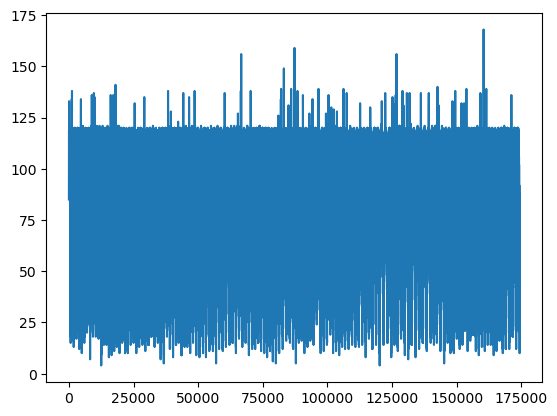

In [29]:
i=21
plt.plot(meas_arr[i][2],meas_arr[i][3])

In [33]:
import numpy as np

def _parse_times_to_seconds(ts_array):
    """
    Convert array of 'HH:MM:SS:ffffff' strings into an increasing
    seconds timeline, unwrapping across midnight if needed.
    Returns a float array of seconds.
    """
    # to string (in case it's bytes)
    ts = np.asarray(ts_array).astype(str)

    # parse each timestamp
    def _one(t):
        h, m, s, us = t.split(':')
        return (int(h) * 3600) + (int(m) * 60) + int(s) + int(us) / 1e6

    secs = np.fromiter((_one(t) for t in ts), dtype=float, count=len(ts))
    if secs.size == 0:
        return secs

    # unwrap day rollovers (if any)
    diffs = np.diff(secs)
    # whenever time goes "backwards", add 24h to all subsequent points
    wraps = np.where(diffs < 0)[0]
    if wraps.size > 0:
        secs_unwrapped = secs.copy()
        add = 0.0
        for i in range(secs.size):
            if i > 0 and secs[i] < secs[i-1]:
                add += 86400.0
            secs_unwrapped[i] += add
        secs = secs_unwrapped

    return secs

def estimate_dark_rate(ts, ns):
    """
    Estimate dark counts per second from one measurement:
      rate = sum(ns) / (t_last - t_first)
    Also returns a 1-sigma Poisson SE: sqrt(N)/T.
    """
    ts = np.asarray(ts)
    ns = np.asarray(ns)

    # guard: no data
    if ts.size == 0 or ns.size == 0:
        return np.nan, np.nan, 0.0

    # make lengths compatible (trim to common length if needed)
    n = min(ts.size, ns.size)
    if ts.size != ns.size:
        ts = ts[:n]
        ns = ns[:n]

    # parse timestamps to a continuous seconds axis
    secs = _parse_times_to_seconds(ts)

    # duration
    if n == 1:
        # can't infer a duration from a single sample
        return np.nan, np.nan, 0.0
    duration = float(secs[-1] - secs[0])
    if duration <= 0:
        return np.nan, np.nan, 0.0

    # sum counts (ignore NaNs, clip negatives)
    ns_clean = np.nan_to_num(ns, nan=0.0)
    ns_clean = np.clip(ns_clean, 0, None)
    total_counts = float(np.sum(ns_clean))

    # rate and (Poisson) standard error
    rate = total_counts / duration
    rate_se = np.sqrt(total_counts) / duration

    return rate, rate_se, duration, total_counts

# ---- Example on your measurement #9 ----
name_nl, ts_nl, ns_nl, xs_nl = meas_arr[9]
rate, rate_se, duration, total_counts= estimate_dark_rate(ts_nl, xs_nl)

print(f"Measurement: {name_nl}")
print(f"Duration: {duration:.3f} s")
print(f"Dark count rate: {rate:.3f} counts/s (± {rate_se:.3f} 1σ)")
print(f"Duration: {total_counts:.3f} counts")

Measurement: measurement_23_07_25_test5_nolight
Duration: 15.006 s
Dark count rate: 2.399 counts/s (± 0.400 1σ)
Duration: 36.000 counts


In [31]:
plt.plot(

SyntaxError: unexpected EOF while parsing (582913220.py, line 1)

In [33]:
ts_nl[0]

NameError: name 'ts_nl' is not defined

In [35]:
ts_nl[7700]

NameError: name 'ts_nl' is not defined

In [37]:
ts_nl[1]

NameError: name 'ts_nl' is not defined

In [39]:
meas_arr2 = import_all_measurements_as_array(r'D:\PhD Thesis Writing\Data\2025-07-24')


In [41]:
# Each meas_arr[i] is (name, ts, ns, xs)
for i, rec in enumerate(meas_arr2):
    name = rec[0]
    print(i, name)

# List of (index, name):
indexed_names = [(i, rec[0]) for i, rec in enumerate(meas_arr2)]

0 measurement_24_07_25_ramp1
1 measurement_24_07_25_ramptest
2 measurement_24_07_25_ramp2
3 measurement_24_07_25_balanced1
4 measurement_24_07_25_balanced2_lv
5 measurement_24_07_25_fan_lv
6 measurement_24_07_25_fan2_lv
7 measurement_24_07_25_fan3_lv
8 measurement_24_07_25_fan4_lv
9 measurement_24_07_25_1km_balanced_lv
10 measurement_24_07_25_1km_balanced1_lv
11 measurement_24_07_25_1km_balanced2_lv
12 measurement_24_07_25_1km_random1_lv
13 measurement_24_07_25_1km_ramp1_lv


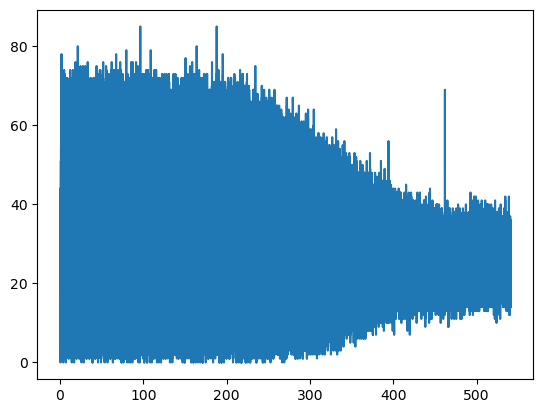

In [50]:
plt.plot(ts_13,meas_arr2[13][3])

In [45]:
def ts_to_seconds_since_start(ts):
    """
    Convert timestamps 'HH:MM:SS:ffffff' to seconds relative to the first sample.
    Handles day rollovers by unwrapping when time goes backwards.

    Parameters
    ----------
    ts : array-like of str (or bytes)
        e.g. ["16:49:53:998392", "16:49:54:000386", ...]

    Returns
    -------
    secs_rel : np.ndarray of float
        Seconds since ts[0], with secs_rel[0] == 0.0
    """
    ts = np.asarray(ts).astype(str)
    n = ts.size
    if n == 0:
        return np.array([], dtype=float)

    def _parse(tstr):
        h, m, s, us = tstr.split(':')
        return int(h)*3600 + int(m)*60 + int(s) + int(us)/1e6

    secs = np.fromiter((_parse(t) for t in ts), dtype=float, count=n)

    # unwrap across midnight (or any backward jump)
    add = 0.0
    unwrapped = np.empty_like(secs)
    unwrapped[0] = secs[0]
    for i in range(1, n):
        if secs[i] < secs[i-1]:
            add += 86400.0  # add one day
        unwrapped[i] = secs[i] + add

    return unwrapped - unwrapped[0]

In [47]:
ts_13=ts_to_seconds_since_start(meas_arr2[13][1])


In [52]:
%matplotlib qt
plt.plot(meas_arr2[11][2],meas_arr2[11][3])

In [54]:
meas_arr2[3][1][0]

'13:11:24:110205'

In [56]:
meas_arr2[3][1][1]

'13:11:24:112199'

In [58]:
meas_arr2[4][1][0]

'14:34:11:956446'

In [60]:
meas_arr2[4][1][1]

'14:34:11:958440'

In [62]:
len(meas_arr2[4][3])

106349

In [64]:
len(meas_arr2[3][3])

484677

In [66]:
ts3,cs3=meas_arr2[3][1],meas_arr2[3][3]
ts4,cs4=meas_arr2[4][1],meas_arr2[4][3]

In [68]:
plt.plot(meas_arr2[3][2],meas_arr2[3][3])
plt.plot(meas_arr2[4][2],meas_arr2[4][3])

In [242]:
meas_arr3 = import_all_measurements_as_array(r'D:\PhD Thesis Writing\Data\2025-10-15')


In [244]:
meas_arr3

array([['measurement_15_10_25_1chnl_1km_MPCandVOA_lv',
        array(['17:38:21:604824', '17:38:21:605822', '17:38:21:607816', ...,
               '18:35:35:471010', '18:35:35:472236', '18:35:35:474237'],
              dtype='<U15')                                                 ,
        array([      1,       2,       3, ..., 1768284, 1768285, 1768286]),
        array([27., 40., 40., ..., 34., 40., 29.])]], dtype=object)

In [318]:
%matplotlib inline
plt.plot(meas_arr3[0][2]/500,meas_arr3[0][3])

In [254]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, chi2
# Optional: independence test (if installed)
try:
    from statsmodels.stats.diagnostic import acorr_ljungbox
    HAVE_SM = True
except Exception:
    HAVE_SM = False

# --- Inputs ---
# t: 1D array of timestamps (seconds, or any monotonic unit)
# counts: 1D array of photon counts per bin, same length as t
# Assumes bins are equal duration. If unsure, see the "Unequal bins?" note below.
# Example:
# t = np.arange(len(vtd))  # or your actual times (must be monotonic)
# counts = your_counts_array

def fano_bootstrap(counts, n_boot=2000, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    m = np.mean(counts)
    v = np.var(counts, ddof=1)
    f = v / m if m > 0 else np.nan
    # bootstrap CI for Fano factor
    boots = []
    n = len(counts)
    for _ in range(n_boot):
        samp = rng.choice(counts, size=n, replace=True)
        m_b = np.mean(samp)
        v_b = np.var(samp, ddof=1)
        boots.append(v_b / m_b if m_b > 0 else np.nan)
    boots = np.array(boots)
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return f, (lo, hi), m, v

def chisq_poisson_gof(counts):
    """
    Pearson chi-square GOF test comparing the empirical distribution
    to Poisson with lambda = mean(counts). Tail bins are merged so that
    expected >= 5. Returns (chi2_stat, df, pval, table) where table lists
    bin ranges used and (obs, exp).
    """
    lam = np.mean(counts)
    # Support from 0..max
    k_vals = np.arange(0, counts.max() + 1)
    n = len(counts)
    obs_hist = np.bincount(counts, minlength=k_vals.size).astype(float)
    exp_hist = n * poisson.pmf(k_vals, lam)

    # Merge low-expected tails to ensure expected >= 5
    # Start from both ends and combine until all bins have exp>=5
    def merge_bins(obs, exp):
        left, right = 0, len(obs) - 1
        groups = []
        while left <= right:
            # start a new group on the left
            g_obs, g_exp = obs[left], exp[left]
            g_start, g_end = left, left
            while g_exp < 5 and g_end < right:
                # decide whether to merge to the right side of this block
                g_end += 1
                g_obs += obs[g_end]
                g_exp += exp[g_end]
            groups.append((g_start, g_end, g_obs, g_exp))
            left = g_end + 1
        # If last group's expected < 5 and there is >1 group, merge with previous
        if groups and groups[-1][3] < 5 and len(groups) > 1:
            a = groups.pop()
            b = groups.pop()
            groups.append((b[0], a[1], b[2] + a[2], b[3] + a[3]))
        return groups

    groups = merge_bins(obs_hist, exp_hist)
    # Compute chi-square across merged groups
    chi2_stat = 0.0
    table = []
    for g in groups:
        i0, i1, o, e = g
        if e > 0:
            chi2_stat += (o - e) ** 2 / e
        table.append(((i0, i1), o, e))
    # df = (#groups - 1 - #estimated parameters). We estimated lambda => 1 param.
    df = max(1, len(groups) - 1 - 1)
    pval = 1 - chi2.cdf(chi2_stat, df)
    return chi2_stat, df, pval, table, lam

def qqplot_poisson(counts, ax=None):
    """Discrete QQ plot vs Poisson(lam)."""
    lam = np.mean(counts)
    x = np.sort(counts)
    n = len(x)
    # Expected quantiles via inverse CDF on (i-0.5)/n
    p = (np.arange(1, n + 1) - 0.5) / n
    q = poisson.ppf(p, lam)
    if ax is None:
        ax = plt.gca()
    ax.plot(q, x, '.', label='Empirical vs Poisson quantiles')
    minv, maxv = min(q.min(), x.min()), max(q.max(), x.max())
    ax.plot([minv, maxv], [minv, maxv], '-', label='y=x reference')
    ax.set_xlabel('Poisson quantiles')
    ax.set_ylabel('Empirical quantiles')
    ax.set_title('Poisson QQ plot')
    ax.grid(True)
    ax.legend()

def rootogram(counts, ax=None):
    """Hanging rootogram against Poisson(lam)."""
    lam = np.mean(counts)
    k = np.arange(0, counts.max() + 1)
    n = len(counts)
    obs = np.bincount(counts, minlength=len(k))
    exp = n * poisson.pmf(k, lam)
    if ax is None:
        ax = plt.gca()
    ax.axhline(0, linewidth=1)
    # hanging bars: sqrt(obs) - sqrt(exp)
    y = np.sqrt(obs) - np.sqrt(exp)
    ax.bar(k, y, width=0.9, align='center')
    ax.set_xlabel('Count value')
    ax.set_ylabel(r'$\sqrt{{obs}}-\sqrt{{exp}}$')
    ax.set_title('Hanging rootogram vs Poisson')
    ax.grid(True, axis='y')

def independence_check(counts, lags=20):
    """Optional Ljung–Box test on (counts - mean)."""
    if not HAVE_SM:
        return None
    res = acorr_ljungbox(counts - np.mean(counts), lags=[lags], return_df=True)
    # returns DataFrame with lb_stat and lb_pvalue at the specified lag
    stat = float(res['lb_stat'].iloc[0])
    pval = float(res['lb_pvalue'].iloc[0])
    return stat, pval

def check_equal_bins(t):
    """Quick sanity: relative std of inter-bin spacing."""
    dt = np.diff(t)
    cv = np.std(dt) / np.mean(dt)
    return float(cv), dt

# ---------------- Use the functions ----------------
def analyze_poisson(t, counts, n_boot=2000, lb_lag=20, make_plots=True):
    # 0) Are bins equal length?
    cv, dt = check_equal_bins(t)
    if cv > 0.05:
        print(f"WARNING: bin widths vary (CV={cv:.3f}). Poisson tests assume equal exposure per bin.")
    else:
        print(f"Bin width CV={cv:.3f} (looks reasonably equal).")

    # 1) Fano factor
    F, (F_lo, F_hi), mean_c, var_c = fano_bootstrap(counts, n_boot=n_boot)
    print(f"Mean = {mean_c:.4f}, Var = {var_c:.4f}, Fano = {F:.4f} (95% CI [{F_lo:.4f}, {F_hi:.4f}])")

    # 2) Chi-square GOF to Poisson(mean)
    chi2_stat, df, pval, table, lam = chisq_poisson_gof(counts)
    print(f"Chi-square GOF vs Poisson(lam={lam:.4f}): chi2={chi2_stat:.2f}, df={df}, p={pval:.4g}")
    # Show merged bins with low expected counts
    small = [(rng, o, e) for (rng, o, e) in table if e < 8]  # arbitrary threshold to display
    if small:
        print("Merged/low-expected groups (range -> observed / expected):")
        for rng, o, e in small[:10]:
            print(f"  {rng[0]}–{rng[1]} -> {o:.1f} / {e:.1f}")

    # 3) Optional independence test (time structure)
    if HAVE_SM:
        lb = independence_check(counts, lags=lb_lag)
        if lb:
            stat, p = lb
            print(f"Ljung–Box (lag={lb_lag}): stat={stat:.2f}, p={p:.4g}")
    else:
        print("Ljung–Box test skipped (statsmodels not installed).")

    # 4) Plots
    if make_plots:
        plt.figure(figsize=(11,4))
        plt.plot(counts, '.', label='Counts')
        plt.xlabel('Bin index')
        plt.ylabel('Counts')
        plt.title('Counts over time')
        plt.grid(True)
        plt.legend()

        plt.figure(figsize=(11,4))
        rootogram(counts)
        plt.tight_layout()

        plt.figure(figsize=(5.5,5.5))
        qqplot_poisson(counts)
        plt.tight_layout()
        plt.show()

# ---- Example call ----
# analyze_poisson(t, counts)


In [260]:
import numpy as np

vtd=meas_arr3[0][1]

# vtd: your array of strings like '17:47:08:952227'
parsed = np.array([list(map(int, s.split(':'))) for s in vtd], dtype=np.int64)
H, M, S, us = parsed.T

# absolute microseconds since midnight
t_us = ((H * 3600 + M * 60 + S) * 1_000_000 + us)

# handle midnight wrap (optional)
wraps = np.where(np.diff(t_us) < 0)[0]
if wraps.size:
    day_us = 24 * 3600 * 1_000_000
    for w in wraps:
        t_us[w+1:] += day_us

# numeric time axis you can subtract / diff on
t_s = (t_us - t_us[0]) / 1e6        # seconds since first sample
dt_s = np.diff(t_us) / 1e6          # inter-sample spacings in seconds


In [268]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2, poisson

# ---------- 1) Parse timestamps like 'HH:MM:SS:ffffff' to seconds ----------
def parse_vtd_seconds(vtd):
    parsed = np.array([list(map(int, s.split(':'))) for s in vtd], dtype=np.int64)
    H, M, S, us = parsed.T
    t_us = ((H * 3600 + M * 60 + S) * 1_000_000 + us)
    # handle midnight wrap
    wraps = np.where(np.diff(t_us) < 0)[0]
    if wraps.size:
        day_us = 24 * 3600 * 1_000_000
        for w in wraps:
            t_us[w+1:] += day_us
    return (t_us - t_us[0]) / 1e6  # seconds since start

# ---------- 2) Build edges from centers ----------
def centers_to_edges(t_center):
    t_center = np.asarray(t_center, float)
    if t_center.ndim != 1 or t_center.size < 2:
        raise ValueError("Need at least two timestamps.")
    # internal edges are midpoints
    mids = 0.5 * (t_center[:-1] + t_center[1:])
    # extrapolate first and last edge
    first_edge = t_center[0] - (mids[0] - t_center[0])
    last_edge  = t_center[-1] + (t_center[-1] - mids[-1])
    edges = np.concatenate(([first_edge], mids, [last_edge]))
    return edges

# ---------- 3) Rebin by overlap (rate-integrating, accurate) ----------
def rebin_by_overlap(old_edges, counts, new_width=None):
    """
    old_edges: array (N+1) of original bin edges (monotonic)
    counts:    array (N)   of counts per original bin
    new_width: fixed uniform bin width; if None, use median of original widths
    Returns: new_counts, new_edges
    """
    old_edges = np.asarray(old_edges, float)
    counts = np.asarray(counts, float)
    if old_edges.ndim != 1 or counts.ndim != 1 or old_edges.size != counts.size + 1:
        raise ValueError("old_edges length must be counts length + 1.")

    # original widths and rates
    dt = np.diff(old_edges)
    if np.any(dt <= 0):
        raise ValueError("Edges must be strictly increasing.")
    rates = counts / dt  # piecewise-constant rate within each original bin

    # choose uniform width
    if new_width is None:
        new_width = np.median(dt)

    start, stop = old_edges[0], old_edges[-1]
    n_new = int(np.ceil((stop - start) / new_width))
    new_edges = start + np.arange(n_new + 1) * new_width

    # overlap integration: for each new bin, integrate r_i over overlap length
    new_counts = np.zeros(n_new, dtype=float)
    i = 0  # index for original bins
    for j in range(n_new):
        a, b = new_edges[j], new_edges[j+1]
        # advance i until old interval intersects [a,b)
        while i < len(dt) and old_edges[i+1] <= a:
            i += 1
        ii = i
        # accumulate overlaps across old bins until we pass b
        while ii < len(dt) and old_edges[ii] < b:
            left = max(a, old_edges[ii])
            right = min(b, old_edges[ii+1])
            olap = right - left
            if olap > 0:
                new_counts[j] += rates[ii] * olap
            if old_edges[ii+1] <= b:
                ii += 1
            else:
                break

    # numeric guard: round tiny negatives to zero, then to ints
    new_counts = np.maximum(new_counts, 0.0)
    return new_counts.astype(int), new_edges

# ---------- 4) Poisson GOF for equal-width bins ----------
def poisson_gof_equal_bins(counts):
    lam = counts.mean()
    k = np.arange(0, counts.max() + 1)
    n = len(counts)
    obs = np.bincount(counts, minlength=len(k)).astype(float)
    exp = n * poisson.pmf(k, lam)

    # merge tail bins until expected >= 5
    groups = []
    left, right = 0, len(obs) - 1
    while left <= right:
        g_obs, g_exp = obs[left], exp[left]
        g_start, g_end = left, left
        while g_exp < 5 and g_end < right:
            g_end += 1
            g_obs += obs[g_end]
            g_exp += exp[g_end]
        groups.append((g_start, g_end, g_obs, g_exp))
        left = g_end + 1

    chi2_stat = sum((o - e) ** 2 / e for _, _, o, e in groups if e > 0)
    df = max(1, len(groups) - 2)  # minus 1 for sum-to-n, minus 1 for estimated λ
    pval = 1 - chi2.cdf(chi2_stat, df)
    return lam, chi2_stat, df, pval

# ---------- 5) Convenience wrapper ----------
def poisson_test_from_centers(vtd_centers, counts, target_width=None, make_plots=True):
    """
    vtd_centers: array of timestamp strings ('HH:MM:SS:ffffff') at bin centers
    counts:      counts measured at those centers (same length)
    target_width: fixed bin width in seconds (None => median original width)
    """
    t_center = parse_vtd_seconds(vtd_centers)
    edges = centers_to_edges(t_center)
    rebinned_counts, new_edges = rebin_by_overlap(edges, counts, new_width=target_width)
    lam, chi2_stat, df, p = poisson_gof_equal_bins(rebinned_counts)
    print(f"Rebinned to Δt = {new_edges[1]-new_edges[0]:.6f} s | {len(rebinned_counts)} bins")
    print(f"Poisson GOF: λ̂={lam:.3f}, χ²={chi2_stat:.2f}, df={df}, p={p:.4g}")

    if make_plots:
        # show counts and Poisson fit
        x = np.arange(len(rebinned_counts))
        plt.figure(figsize=(10,4))
        plt.bar(x, rebinned_counts, label='Rebinned counts')
        plt.xlabel('Uniform bin index'); plt.ylabel('Counts')
        plt.title('Counts after uniform rebinning'); plt.grid(True, axis='y'); plt.legend()
        plt.tight_layout(); plt.show()

    return rebinned_counts, new_edges, (lam, chi2_stat, df, p)

Rebinned to Δt = 0.100000 s | 34339 bins
Poisson GOF: λ̂=1839.165, χ²=927.26, df=266, p=0


C:\Users\Ry\AppData\Local\Temp\ipykernel_24504\3727202576.py:130: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.show()
C:\Users\Ry\anaconda3\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


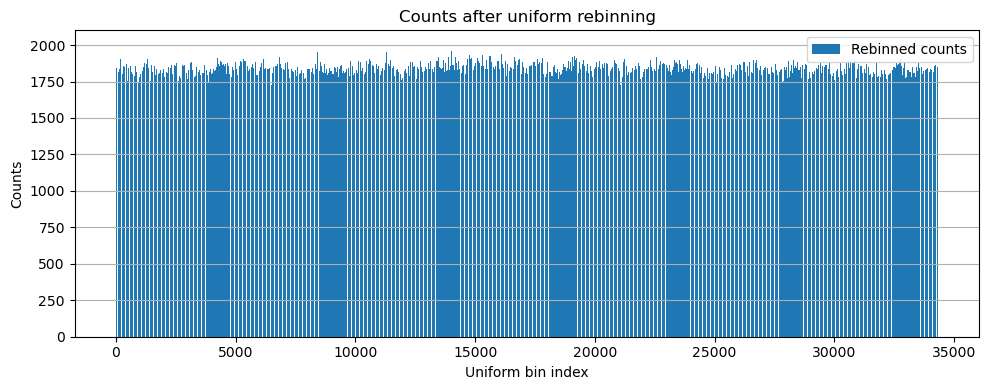

In [278]:
# ---------------------- Example usage ----------------------
rebinned_counts, new_edges, stats = poisson_test_from_centers(meas_arr3[0][1], meas_arr3[0][3], target_width=0.1)
# If you want a specific fixed width (e.g., 0.1 s): target_width=0.1


mean=1839.16, var=1475.50, Fano=0.802


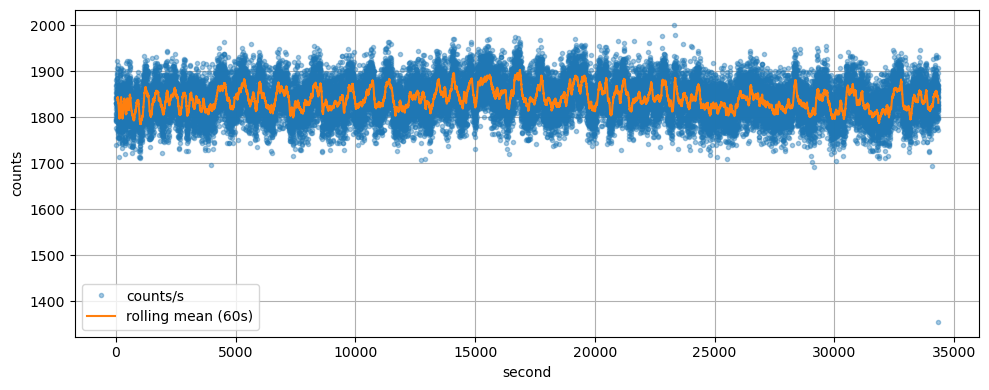

In [280]:
import numpy as np
import matplotlib.pyplot as plt

# counts_1s: your 1-second rebinned counts (length ~3434)
x = rebinned_counts.astype(float)
n = len(x)
mu = x.mean()
var = x.var(ddof=1)
fano = var / mu
print(f"mean={mu:.2f}, var={var:.2f}, Fano={fano:.3f}")

# Rolling stats to reveal drift (change the window as needed)
w = 60  # seconds (1 minute)
roll_mu = np.convolve(x, np.ones(w), 'valid')/w
roll_var = (np.convolve((x - mu)**2, np.ones(w), 'valid')/w)
plt.figure(figsize=(10,4)); plt.plot(x, '.', alpha=0.4, label='counts/s')
plt.plot(np.arange(w-1,n), roll_mu, '-', label=f'rolling mean ({w}s)')
plt.xlabel('second'); plt.ylabel('counts'); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


In [282]:
from scipy.stats import chi2

def blockwise_pearson(counts, block=60):
    counts = np.asarray(counts, float)
    n = len(counts)
    # split into blocks
    K = int(np.ceil(n / block))
    X2 = 0.0
    df = 0
    for k in range(K):
        a = k*block
        b = min((k+1)*block, n)
        y = counts[a:b]
        lam = y.mean()
        mu = np.full_like(y, lam)
        valid = mu > 0
        X2 += np.sum((y[valid]-mu[valid])**2 / mu[valid])
        df += valid.sum() - 1  # 1 fitted param (λ) per block
    p = 1 - chi2.cdf(X2, df)
    return X2, df, p, K

X2, df, p, K = blockwise_pearson(rebinned_counts, block=60)
print(f"Blockwise χ²={X2:.1f}, df={df}, p={p:.3g}  (blocks={K})")


Blockwise χ²=19492.7, df=33766, p=1  (blocks=573)


In [284]:
mu = rebinned_counts.mean()
var = rebinned_counts.var(ddof=1)
if var > mu:
    k = mu**2 / (var - mu)   # dispersion (size) parameter
    print(f"NB fit: mean={mu:.2f}, k={k:.2f} (smaller k => more over-dispersion)")
else:
    print("Under-dispersion (var <= mean) — NB is not appropriate.")


Under-dispersion (var <= mean) — NB is not appropriate.


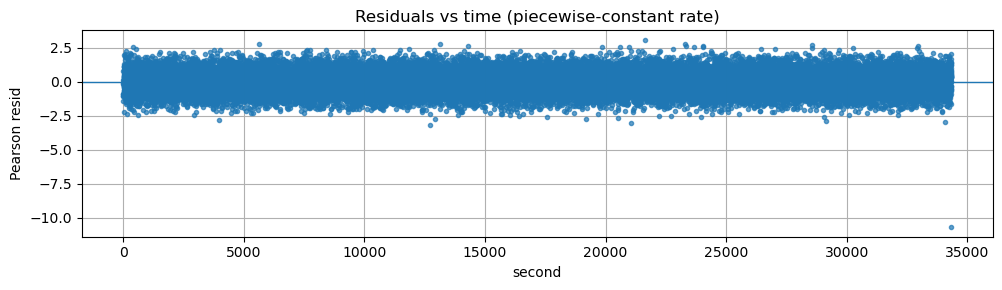

In [286]:
# Pearson residuals under piecewise λ (same blocks as above)
def blockwise_residuals(counts, block=60):
    counts = np.asarray(counts, float)
    n = len(counts)
    res = np.empty(n); res[:] = np.nan
    for a in range(0, n, block):
        b = min(a+block, n)
        lam = counts[a:b].mean()
        mu = lam
        res[a:b] = (counts[a:b] - mu) / np.sqrt(mu + 1e-12)
    return res

res = blockwise_residuals(rebinned_counts, block=60)
plt.figure(figsize=(10,3))
plt.plot(res, '.', alpha=0.7)
plt.axhline(0, linewidth=1); plt.xlabel('second'); plt.ylabel('Pearson resid')
plt.title('Residuals vs time (piecewise-constant rate)'); plt.grid(True); plt.tight_layout(); plt.show()


In [288]:
import numpy as np

def rebin_by_multinomial(old_edges, counts, new_width=None, rng=None):
    """
    old_edges: (N+1,) original edges
    counts:    (N,)    counts per original bin
    new_width: target fixed width (None -> median original)
    rng:       np.random.Generator
    Returns: (new_counts, new_edges)
    """
    rng = np.random.default_rng() if rng is None else rng
    old_edges = np.asarray(old_edges, float)
    counts = np.asarray(counts, int)
    dt = np.diff(old_edges)
    if np.any(dt <= 0):
        raise ValueError("Edges must be strictly increasing.")
    if new_width is None:
        new_width = np.median(dt)

    start, stop = old_edges[0], old_edges[-1]
    n_new = int(np.ceil((stop - start) / new_width))
    new_edges = start + np.arange(n_new + 1) * new_width
    new_counts = np.zeros(n_new, dtype=int)

    # for each old bin, find overlapping new bins and multinomially split c_i
    j0 = 0
    for i in range(len(counts)):
        a, b = old_edges[i], old_edges[i+1]
        c = counts[i]
        if c == 0:
            continue

        # advance j0 until new bin ends after a
        while j0 < n_new and new_edges[j0+1] <= a:
            j0 += 1
        j = j0

        overlaps = []
        idxs = []
        while j < n_new and new_edges[j] < b:
            left = max(a, new_edges[j])
            right = min(b, new_edges[j+1])
            olap = right - left
            if olap > 0:
                overlaps.append(olap)
                idxs.append(j)
            if new_edges[j+1] <= b:
                j += 1
            else:
                break

        if overlaps:
            p = np.array(overlaps, float)
            p /= p.sum()            # probabilities over this old bin
            split = rng.multinomial(c, p)
            new_counts[np.array(idxs)] += split

    return new_counts, new_edges


In [292]:
# centers -> edges as before
centers=parse_vtd_seconds(meas_arr3[0][1])
edges = centers_to_edges(centers)
counts_0p1, edges_0p1 = rebin_by_multinomial(edges, meas_arr3[0][3], new_width=0.1)
# then run the same Poisson GOF you already have on counts_0p1
lam, chi2_stat, df, p = poisson_gof_equal_bins(counts_0p1)
print(f"[0.1 s bins | multinomial rebin] λ̂={lam:.3f}, χ²={chi2_stat:.2f}, df={df}, p={p:.4g}")

# recompute Fano and residuals if you like
mu = counts_0p1.mean()
var = counts_0p1.var(ddof=1)
print(f"mean={mu:.2f}, var={var:.2f}, Fano={var/mu:.3f}")

[0.1 s bins | multinomial rebin] λ̂=1839.664, χ²=836.82, df=266, p=0
mean=1839.66, var=1485.96, Fano=0.808


In [294]:
y = counts_0p1.astype(float)
y = y - y.mean()
acf1 = np.corrcoef(y[:-1], y[1:])[0,1]           # lag-1 ACF
# 95% white-noise band ~ ±1.96/sqrt(N)
N = len(y)
ci = 1.96/np.sqrt(N)
print(f"lag-1 ACF = {acf1:.4f}, 95% CI ±{ci:.4f}")

lag-1 ACF = 0.3102, 95% CI ±0.0106


In [296]:
def coarsen(x, k):
    n = (len(x)//k)*k
    return x[:n].reshape(-1,k).sum(1)

for k in [1,2,5,10]:            # 0.1s, 0.2s, 0.5s, 1.0s
    z = coarsen(counts_0p1, k)
    mu, var = z.mean(), z.var(ddof=1)
    print(f"{0.1*k:>4.1f}s: mean={mu:.1f}, var={var:.1f}, Fano={var/mu:.3f}")


 0.1s: mean=1839.7, var=1486.0, Fano=0.808
 0.2s: mean=3679.4, var=3872.5, Fano=1.052
 0.5s: mean=9198.4, var=16622.3, Fano=1.807
 1.0s: mean=18396.8, var=55591.6, Fano=3.022


In [298]:
import numpy as np
from scipy.stats import chi2

y = counts_0p1.astype(float)
w = 50  # 5 s rolling window over 0.1 s bins; try 50–300
mu = np.convolve(y, np.ones(w)/w, mode='same')  # local mean (expected)
res = (y - mu) / np.sqrt(mu + 1e-12)

# Local Fano (Pearson) over windows
def local_fano(y, mu, k=200):  # 20 s blocks
    n = (len(y)//k)*k
    y, mu = y[:n], mu[:n]
    x = ((y - mu)**2 / (mu + 1e-12)).reshape(-1, k).mean(1)
    return x.mean(), x.std()  # mean~1 for Poisson
LF_mean, LF_sd = local_fano(y, mu, k=200)
print(f"Local Pearson Fano ≈ {LF_mean:.3f} ± {LF_sd:.3f} (Poisson would be ≈1)")

# Pearson χ² with time-varying mean (1 parameter per sample estimated by the smoother)
valid = mu > 0
X2 = np.sum(((y[valid]-mu[valid])**2) / mu[valid])
df = valid.sum() - 1  # very approximate
p = 1 - chi2.cdf(X2, df)
print(f"Time-varying Poisson (via rolling mean): Pearson χ²={X2:.1f}, df≈{df}, p≈{p:.3g}")


Local Pearson Fano ≈ 0.745 ± 2.493 (Poisson would be ≈1)
Time-varying Poisson (via rolling mean): Pearson χ²=30881.0, df≈34338, p≈1


In [300]:
import numpy as np
from numpy.linalg import lstsq

y = counts_0p1.astype(float)
y0 = y - y.mean()
m = 10  # look back 1 s (10×0.1 s bins); increase if needed
X = np.column_stack([np.roll(y0, k) for k in range(m)])
X[:m,:] = 0.0  # drop invalid rows
beta, *_ = lstsq(X[m:], y0[m:], rcond=None)
print("MA-like kernel (first 10 lags):", np.round(beta, 3))


MA-like kernel (first 10 lags): [ 1.  0.  0. -0. -0.  0. -0. -0.  0. -0.]


In [302]:
import numpy as np
from numpy.linalg import lstsq

y = counts_0p1.astype(float)
y0 = y - y.mean()

m = 20   # examine last 2 s (adjust)
X = np.column_stack([np.roll(y0, k) for k in range(1, m+1)])  # lags 1..m
X[:m, :] = 0.0
Y = y0.copy()
Y[:m] = 0.0

# small ridge to tame multicollinearity
lam = 1e-3
XtX = X[m:].T @ X[m:] + lam*np.eye(m)
Xty = X[m:].T @ Y[m:]
beta = np.linalg.solve(XtX, Xty)
print("MA-like kernel (lags 1..m):", np.round(beta, 3))


MA-like kernel (lags 1..m): [0.071 0.077 0.059 0.055 0.057 0.041 0.048 0.039 0.044 0.039 0.047 0.033
 0.046 0.035 0.033 0.029 0.032 0.03  0.029 0.034]


In [304]:
import numpy as np
from scipy.stats import chi2

y = counts_0p1.astype(float)
w = 100   # 10 s window; try 50–300
box = np.ones(w)

# plain rolling sum
s = np.convolve(y, box, mode='same')
# LOO mean: subtract the point itself from the window sum
mu = (s - y) / (w - 1)
mu = np.clip(mu, 1e-12, None)

# local Pearson Fano (should be ~1 if Poisson after detrending)
k = 200   # evaluate in 20 s blocks
n = (len(y)//k)*k
LF = ((y[:n]-mu[:n])**2 / mu[:n]).reshape(-1, k).mean(1)
print(f"LOO local Pearson Fano: mean={LF.mean():.3f}, sd={LF.std():.3f}")

# crude global Pearson with a df correction (subtract ~N/(w) params)
valid = mu > 0
X2 = np.sum((y[valid]-mu[valid])**2 / mu[valid])
edf = valid.sum() - valid.sum()/w   # rough effective df
p = 1 - chi2.cdf(X2, max(1, int(edf)))
print(f"Time-varying Poisson with LOO mean: χ²={X2:.1f}, df≈{int(edf)}, p≈{p:.3g}")


LOO local Pearson Fano: mean=0.960, sd=4.956
Time-varying Poisson with LOO mean: χ²=44842.3, df≈33995, p≈0


In [308]:
import numpy as np
import statsmodels.api as sm
from patsy import dmatrix
from scipy.stats import chi2

# y: your 0.1 s counts array
y = counts_0p1.astype(float)
t = np.arange(len(y)) * 0.1  # seconds

# cubic regression spline for the mean rate; adjust df (number of basis functions) as needed
X = dmatrix("bs(t, df=40, degree=3, include_intercept=True)", {"t": t})

mod = sm.GLM(y, X, family=sm.families.Poisson())
res = mod.fit()

# Core GOF numbers (works across versions)
dev = float(res.deviance)
pearson = float(getattr(res, "pearson_chi2", np.nan))
df_resid = int(res.df_resid)
df_model = int(res.df_model)

print(f"Deviance        = {dev:.2f}")
print(f"Pearson chi2    = {pearson:.2f}")
print(f"Df Residual     = {df_resid}")
print(f"Df Model        = {df_model}")
print(f"Deviance/df     = {dev/df_resid:.3f}")
print(f"Pearson/df      = {pearson/df_resid:.3f}")
print(f"AIC             = {res.aic:.2f}")

# p-values for overall fit (large p -> good fit)
p_dev = 1 - chi2.cdf(dev, df_resid)
p_pear = 1 - chi2.cdf(pearson, df_resid)
print(f"Deviance p      = {p_dev:.3g}")
print(f"Pearson p       = {p_pear:.3g}")

# Residual quick check
r_dev = res.resid_deviance
print(f"Deviance resid mean={np.mean(r_dev):.3f}, std={np.std(r_dev):.3f}")


Deviance        = 25265.33
Pearson chi2    = 25248.59
Df Residual     = 34299
Df Model        = 39
Deviance/df     = 0.737
Pearson/df      = 0.736
AIC             = 346589.64
Deviance p      = 1
Pearson p       = 1
Deviance resid mean=-0.003, std=0.858


In [310]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# -------------------- Helpers --------------------

def parse_vtd_seconds(vtd):
    """Parse 'HH:MM:SS:ffffff' array to seconds since the first timestamp."""
    parsed = np.array([list(map(int, s.split(':'))) for s in vtd], dtype=np.int64)
    H, M, S, us = parsed.T
    t_us = ((H * 3600 + M * 60 + S) * 1_000_000 + us)
    # handle midnight wrap-around
    wraps = np.where(np.diff(t_us) < 0)[0]
    if wraps.size:
        day_us = 24 * 3600 * 1_000_000
        for w in wraps:
            t_us[w+1:] += day_us
    return (t_us - t_us[0]) / 1e6  # seconds

def centers_to_edges(t_center):
    """Make bin edges from bin centers by midpoints + symmetric extrapolation."""
    t_center = np.asarray(t_center, float)
    if t_center.size < 2:
        raise ValueError("Need at least two centers to infer edges.")
    mids = 0.5 * (t_center[:-1] + t_center[1:])
    first_edge = t_center[0] - (mids[0] - t_center[0])
    last_edge  = t_center[-1] + (t_center[-1] - mids[-1])
    return np.concatenate(([first_edge], mids, [last_edge]))

def poisson_constant_rate_test(dt, counts, make_plots=True):
    """
    Variable-width bins: counts_i ~ Poisson(mu_i = r * dt_i), constant r (Hz).
    Returns a dict of results and (optionally) plots standardized residuals.
    """
    dt = np.asarray(dt, float)
    y  = np.asarray(counts, float)
    if dt.shape != y.shape:
        raise ValueError("dt and counts must have the same shape.")
    if np.any(dt <= 0):
        raise ValueError("All bin widths (dt) must be > 0.")

    T = dt.sum()                # total exposure (s)
    N = y.sum()                 # total counts
    r_hat = N / T               # MLE rate (Hz)
    mu = r_hat * dt             # expected per bin

    # Pearson chi-square
    valid = mu > 0
    X2 = np.sum((y[valid] - mu[valid])**2 / mu[valid])
    df = max(1, int(valid.sum()) - 1)             # 1 fitted parameter (r)
    p_pearson = 1 - chi2.cdf(X2, df)
    dispersion_pearson = X2 / df                  # =1 for ideal Poisson

    # Poisson deviance (with 0*log(0/μ)=0 convention)
    c = y[valid]; m = mu[valid]
    D = 2 * np.sum(np.where(c > 0, c * np.log(c / m) - (c - m), m))
    p_deviance = 1 - chi2.cdf(D, df)
    dispersion_deviance = D / df

    # Exact 95% CI for r from N ~ Poisson(r*T): chi-square limits
    # r_low  = 0.5 * χ²_{α/2, 2N}   / T
    # r_high = 0.5 * χ²_{1-α/2, 2(N+1)} / T
    alpha = 0.05
    r_lo = (0.5 * chi2.ppf(alpha/2, df=2*int(N))) / T if N > 0 else 0.0
    r_hi = (0.5 * chi2.ppf(1 - alpha/2, df=2*int(N + 1))) / T

    # Standardized (Pearson) residuals
    resid = (y - mu) / np.sqrt(np.maximum(mu, 1e-12))

    print(f"Total exposure T = {T:.3f} s, total counts N = {N:.0f}")
    print(f"r_hat = {r_hat:.3f} Hz  (95% CI [{r_lo:.3f}, {r_hi:.3f}])")
    print(f"Pearson:  χ² = {X2:.2f}, df = {df}, p = {p_pearson:.3g},  χ²/df = {dispersion_pearson:.3f}")
    print(f"Deviance: D  = {D:.2f}, df = {df}, p = {p_deviance:.3g},  D/df  = {dispersion_deviance:.3f}")

    if make_plots:
        # residuals vs time (or index if you prefer)
        tmid = np.cumsum(dt) - 0.5*dt
        plt.figure(figsize=(10,3.5))
        plt.plot(tmid, resid, '.', ms=2)
        plt.axhline(0, linewidth=1)
        plt.xlabel('Time [s]')
        plt.ylabel('Pearson residual')
        plt.title('Residuals under constant-rate Poisson (variable exposures)')
        plt.grid(True, axis='y')
        plt.tight_layout()
        plt.show()

        # quick QQ-style discrete check (against N(0,1) as a rough guide)
        rs = np.sort(resid[np.isfinite(resid)])
        q = np.linspace(0.5/len(rs), 1-0.5/len(rs), len(rs))
        from scipy.stats import norm
        plt.figure(figsize=(4,4))
        plt.plot(norm.ppf(q), rs, '.', ms=2)
        mn = min(rs.min(), norm.ppf(q).min()); mx = max(rs.max(), norm.ppf(q).max())
        plt.plot([mn, mx], [mn, mx], '-', lw=1)
        plt.xlabel('Theoretical N(0,1) quantiles')
        plt.ylabel('Pearson residuals')
        plt.title('QQ plot (rough)')
        plt.tight_layout()
        plt.show()

    return {
        "r_hat_Hz": r_hat,
        "r_CI95": (r_lo, r_hi),
        "pearson_chi2": X2,
        "pearson_df": df,
        "pearson_p": p_pearson,
        "pearson_dispersion": dispersion_pearson,
        "deviance": D,
        "deviance_df": df,
        "deviance_p": p_deviance,
        "deviance_dispersion": dispersion_deviance,
        "residuals": resid,
        "mu": mu,
    }

# -------------------- How to call --------------------
# If you have timestamp *centers* (strings like your vtd) and counts:
# t_centers = parse_vtd_seconds(vtd)
# edges = centers_to_edges(t_centers)
# dt = np.diff(edges)                 # exposures per variable bin
# results = poisson_constant_rate_test(dt, counts, make_plots=True)

# If you already have bin edges: dt = np.diff(edges) and call the test directly.


Total exposure T = 3433.871 s, total counts N = 63172236
r_hat = 18396.800 Hz  (95% CI [18392.264, 18401.337])
Pearson:  χ² = 1542739.10, df = 1768285, p = 1,  χ²/df = 0.872
Deviance: D  = 1526119.54, df = 1768285, p = 1,  D/df  = 0.863


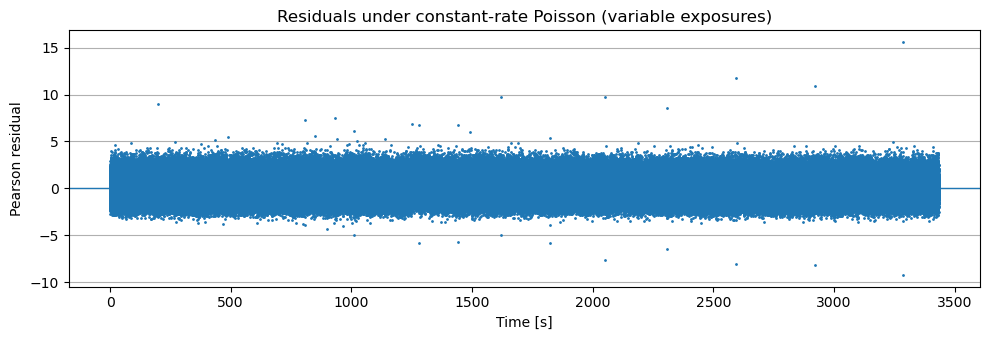

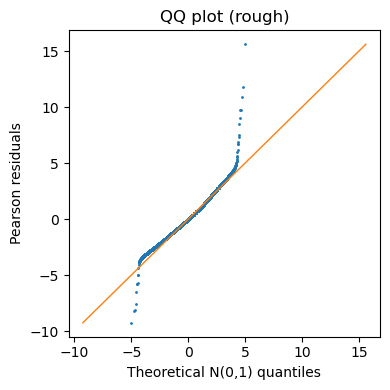

In [314]:

# If you have timestamp *centers* (strings like your vtd) and counts:
t_centers = parse_vtd_seconds(meas_arr3[0][1])
edges = centers_to_edges(t_centers)
dt = np.diff(edges)                 # exposures per variable bin
results = poisson_constant_rate_test(dt, meas_arr3[0][3], make_plots=True)

# If you already have bin edges: dt = np.diff(edges) and call the test directly.


In [262]:
analyze_poisson(t_s, meas_arr3[0][3])


Mean = 35.7251, Var = 19.3058, Fano = 0.5404 (95% CI [0.5382, 0.5431])


TypeError: Cannot cast array data from dtype('float64') to dtype('int64') according to the rule 'safe'

In [70]:
import numpy as np
from typing import Tuple, Dict, Any, List

# ----------------- helpers -----------------

def _timestr_to_seconds(tstr: str) -> float:
    h, m, s, us = tstr.split(':')
    return (int(h) * 3600) + (int(m) * 60) + int(s) + int(us) / 1e6

def _unwrap_seconds(sec: np.ndarray) -> np.ndarray:
    if sec.size <= 1:
        return sec.astype(float)
    out = sec.astype(float).copy()
    add = 0.0
    for i in range(1, sec.size):
        if sec[i] < sec[i-1]:
            add += 86400.0  # add a day after a rollover
        out[i] += add
    return out

def _visibility_from_block_sums(block_sums: np.ndarray) -> float:
    if block_sums.size == 0:
        return np.nan
    Nmin = float(np.min(block_sums))
    Nmax = float(np.max(block_sums))
    den = Nmax + Nmin
    return (Nmax - Nmin) / den if den > 0 else np.nan

# ------------- main function -------------

def point_binned_visibility(
    ts,
    counts,
    n_taus: int = 40,
    tau_max: float = None,
    log_bins: bool = True,
    verbose: bool = True
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, Dict[str, Any]]:
    """
    Point-binning visibility with analytic Poisson errors.

    Returns
    -------
    taus : np.ndarray
        Bin lengths (seconds), ascending.
    V : np.ndarray
        Visibility at each τ, using min/max across bins of summed counts.
    QBER : np.ndarray
        QBER(τ) = (1 - |V(τ)|)/2.
    V_err : np.ndarray
        Analytic 1σ uncertainty on V: sqrt(4AB / (A+B)^3), where A=Nmax, B=Nmin.
    QBER_err : np.ndarray
        Analytic 1σ uncertainty on QBER ≈ 0.5 * V_err.
    tau_err : np.ndarray
        1σ spread of actual K-sample bin durations (std across blocks) for each τ.
        (Use tau_err/√n_blocks for SEM if desired.)
    diagnostics : dict
        Summary stats about sample spacing and bin-duration consistency.
    """
    # ---- prepare data
    ts = np.asarray(ts).astype(str)
    x  = np.clip(np.nan_to_num(np.asarray(counts), nan=0.0), 0, None)
    n = min(ts.size, x.size)
    ts = ts[:n]; x = x[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    secs = _unwrap_seconds(
        np.fromiter((_timestr_to_seconds(s) for s in ts), dtype=float, count=n)
    )
    duration = float(secs[-1] - secs[0])
    if duration <= 0:
        raise ValueError("Non-positive duration.")

    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing.")
    dt_mean = float(np.mean(dt_pos))
    dt_std  = float(np.std(dt_pos, ddof=1)) if dt_pos.size > 1 else 0.0
    dt_cv   = dt_std / dt_mean if dt_mean > 0 else np.nan

    if tau_max is None:
        tau_max = 0.5 * duration
    tau_max = max(float(tau_max), dt_mean)

    # ---- choose K values (samples per bin)
    Kmax = max(1, int(np.floor(tau_max / dt_mean)))
    if n_taus <= 1:
        Ks = np.array([1], dtype=int)
    else:
        if log_bins:
            Ks = np.round(np.logspace(0, np.log10(Kmax), num=n_taus)).astype(int)
        else:
            Ks = np.round(np.linspace(1, Kmax, num=n_taus)).astype(int)
        Ks = np.unique(np.clip(Ks, 1, Kmax))

    taus = Ks * dt_mean
    V = np.empty_like(taus, dtype=float)
    QBER = np.empty_like(taus, dtype=float)
    V_err = np.full_like(taus, np.nan, dtype=float)
    QBER_err = np.full_like(taus, np.nan, dtype=float)
    tau_err = np.full_like(taus, np.nan, dtype=float)

    # Diagnostics we’ll collect per K
    per_tau_diag: List[Dict[str, float]] = []

    # ---- compute V(τ), analytic errors, and bin-size consistency
    for i, K in enumerate(Ks):
        n_full = (n // K) * K
        if n_full == 0:
            V[i] = np.nan
            QBER[i] = np.nan
            tau_err[i] = np.nan
            per_tau_diag.append({
                "K": int(K), "tau_target": K * dt_mean, "n_blocks": 0,
                "tau_mean": np.nan, "tau_std": np.nan,
                "rel_std": np.nan, "rmse_vs_target": np.nan,
                "max_abs_err": np.nan
            })
            continue

        # Block sums for visibility
        block_sums = x[:n_full].reshape(-1, K).sum(axis=1)
        # Central V and QBER
        V[i] = _visibility_from_block_sums(block_sums)
        QBER[i] = 0.5 * (1.0 - np.abs(V[i])) if np.isfinite(V[i]) else np.nan

        # Analytic errors from A=Nmax, B=Nmin (Poisson)
        A = float(np.max(block_sums))
        B = float(np.min(block_sums))
        den = A + B
        if den > 0 and np.isfinite(V[i]):
            varV = 4.0 * A * B / (den ** 3)
            V_err[i] = np.sqrt(varV)
            QBER_err[i] = 0.5 * V_err[i]

        # Actual time-span of each block (first to last sample in the block)
        starts = np.arange(0, n_full, K, dtype=int)
        durations = secs[starts + (K - 1)] - secs[starts]  # length per block
        tau_target = K * dt_mean

        # Consistency metrics (and τ error)
        tau_mean = float(np.mean(durations)) if durations.size else np.nan
        tau_std  = float(np.std(durations, ddof=1)) if durations.size > 1 else 0.0
        tau_err[i] = tau_std  # <-- expose as τ error (spread across blocks)
        rel_std  = (tau_std / tau_mean) if (durations.size and tau_mean > 0) else np.nan
        rmse     = float(np.sqrt(np.mean((durations - tau_target) ** 2))) if durations.size else np.nan
        max_err  = float(np.max(np.abs(durations - tau_target))) if durations.size else np.nan

        per_tau_diag.append({
            "K": int(K),
            "tau_target": tau_target,
            "n_blocks": int(durations.size),
            "tau_mean": tau_mean,
            "tau_std": tau_std,
            "rel_std": rel_std,
            "rmse_vs_target": rmse,
            "max_abs_err": max_err,
        })

    diagnostics = {
        "sample_spacing": {
            "n_samples": int(n),
            "duration_s": duration,
            "dt_mean_s": dt_mean,
            "dt_std_s": dt_std,
            "dt_cv": dt_cv,
            "dt_min_s": float(np.min(dt_pos)),
            "dt_med_s": float(np.median(dt_pos)),
            "dt_max_s": float(np.max(dt_pos)),
            "pct_1_99_s": (float(np.percentile(dt_pos, 1)), float(np.percentile(dt_pos, 99)))
        },
        "per_tau": per_tau_diag
    }

    if verbose:
        ss = diagnostics["sample_spacing"]
        print("\n[Sample spacing diagnostics]")
        print(f"  n = {ss['n_samples']}, duration = {ss['duration_s']:.6f} s")
        print(f"  mean Δt = {ss['dt_mean_s']:.6e} s, std = {ss['dt_std_s']:.6e} s, CV = {ss['dt_cv']:.3g}")
        print(f"  min/median/max Δt = {ss['dt_min_s']:.6e} / {ss['dt_med_s']:.6e} / {ss['dt_max_s']:.6e} s")
        p1, p99 = ss["pct_1_99_s"]
        print(f"  1–99% Δt = {p1:.6e} … {p99:.6e} s")

        print("\n[Bin-size consistency per τ (point binning)]")
        print("  K   τ_target(s)    n_blocks   τ_mean(s)     τ_std(s)     rel_std    RMSE(s)     max|err|(s)")
        for row in per_tau_diag:
            print(f"{row['K']:>4d}  {row['tau_target']:.6e}  {row['n_blocks']:>8d}  "
                  f"{row['tau_mean']:.6e}  {row['tau_std']:.6e}  {row['rel_std'] if np.isfinite(row['rel_std']) else np.nan:>8.3g}  "
                  f"{row['rmse_vs_target']:.6e}  {row['max_abs_err']:.6e}")

    # NOTE: tau_err is appended just before diagnostics:
    return taus, V, QBER, V_err, QBER_err, tau_err, diagnostics


In [72]:
import numpy as np
from typing import Tuple, Dict, Any, List, Optional

# ----------------- helpers -----------------

def _timestr_to_seconds(tstr: str) -> float:
    h, m, s, us = tstr.split(':')
    return (int(h) * 3600) + (int(m) * 60) + int(s) + int(us) / 1e6

def _unwrap_seconds(sec: np.ndarray) -> np.ndarray:
    if sec.size <= 1:
        return sec.astype(float)
    out = sec.astype(float).copy()
    add = 0.0
    for i in range(1, sec.size):
        if sec[i] < sec[i-1]:
            add += 86400.0  # add a day after a rollover
        out[i] += add
    return out

def _visibility_from_block_sums(block_sums: np.ndarray) -> float:
    if block_sums.size == 0:
        return np.nan
    Nmin = float(np.min(block_sums))
    Nmax = float(np.max(block_sums))
    den = Nmax + Nmin
    return (Nmax - Nmin) / den if den > 0 else np.nan

# ------------- main function -------------

def point_binned_visibility(
    ts,
    counts,
    n_taus: int = 40,
    tau_max: float = None,
    log_bins: bool = True,
    overlap: Optional[float] = None,   # <-- NEW: None or fraction in [0,1)
    verbose: bool = True
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, Dict[str, Any]]:
    """
    Point-binning visibility with analytic Poisson errors and optional window overlap.

    Parameters
    ----------
    overlap : None or float in [0,1)
        If None, use non-overlapping windows (stride = K).
        If given, use stride S = round(K*(1-overlap)).
        e.g., overlap=0.5 -> 50% overlap (S ≈ K/2).

    Returns
    -------
    taus, V, QBER, V_err, QBER_err, tau_err, diagnostics
    """
    # ---- prepare data
    ts = np.asarray(ts).astype(str)
    x  = np.clip(np.nan_to_num(np.asarray(counts), nan=0.0), 0, None)
    n = min(ts.size, x.size)
    ts = ts[:n]; x = x[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    secs = _unwrap_seconds(
        np.fromiter((_timestr_to_seconds(s) for s in ts), dtype=float, count=n)
    )
    duration = float(secs[-1] - secs[0])
    if duration <= 0:
        raise ValueError("Non-positive duration.")

    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing.")
    dt_mean = float(np.mean(dt_pos))
    dt_std  = float(np.std(dt_pos, ddof=1)) if dt_pos.size > 1 else 0.0
    dt_cv   = dt_std / dt_mean if dt_mean > 0 else np.nan

    if tau_max is None:
        tau_max = 0.5 * duration
    tau_max = max(float(tau_max), dt_mean)

    # ---- choose K values (samples per bin)
    Kmax = max(1, int(np.floor(tau_max / dt_mean)))
    if n_taus <= 1:
        Ks = np.array([1], dtype=int)
    else:
        if log_bins:
            Ks = np.round(np.logspace(0, np.log10(Kmax), num=n_taus)).astype(int)
        else:
            Ks = np.round(np.linspace(1, Kmax, num=n_taus)).astype(int)
        Ks = np.unique(np.clip(Ks, 1, Kmax))

    taus = Ks * dt_mean
    V = np.empty_like(taus, dtype=float)
    QBER = np.empty_like(taus, dtype=float)
    V_err = np.full_like(taus, np.nan, dtype=float)
    QBER_err = np.full_like(taus, np.nan, dtype=float)
    tau_err = np.full_like(taus, np.nan, dtype=float)

    # Validate overlap
    if overlap is not None:
        if not (0.0 <= overlap < 1.0):
            raise ValueError("overlap must be in [0, 1) or None.")

    # Diagnostics we’ll collect per K
    per_tau_diag: List[Dict[str, Any]] = []

    # ---- compute V(τ), analytic errors, and bin-size consistency
    for i, K in enumerate(Ks):
        # stride from overlap
        if overlap is None:
            stride = K
            overlap_eff = 0.0
        else:
            stride = max(1, int(round(K * (1.0 - overlap))))
            stride = min(stride, K)  # never exceed K
            overlap_eff = 1.0 - (stride / float(K))

        # starting indices; drop any final partial window (<K)
        if n < K:
            starts = np.array([], dtype=int)
        else:
            last_start = n - K
            starts = np.arange(0, last_start + 1, stride, dtype=int)

        n_blocks = int(starts.size)
        if n_blocks == 0:
            V[i] = np.nan
            QBER[i] = np.nan
            tau_err[i] = np.nan
            per_tau_diag.append({
                "K": int(K), "tau_target": K * dt_mean, "n_blocks": 0,
                "stride": int(stride), "overlap_eff": float(overlap_eff),
                "tau_mean": np.nan, "tau_std": np.nan, "rel_std": np.nan,
                "rmse_vs_target": np.nan, "max_abs_err": np.nan
            })
            continue

        # Efficient sliding sums via cumulative sum
        cs = np.concatenate(([0.0], np.cumsum(x, dtype=float)))
        ends = starts + K
        block_sums = cs[ends] - cs[starts]

        # Central V and QBER
        V[i] = _visibility_from_block_sums(block_sums)
        QBER[i] = 0.5 * (1.0 - np.abs(V[i])) if np.isfinite(V[i]) else np.nan

        # Analytic errors from A=Nmax, B=Nmin (Poisson)
        A = float(np.max(block_sums))
        B = float(np.min(block_sums))
        den = A + B
        if den > 0 and np.isfinite(V[i]):
            varV = 4.0 * A * B / (den ** 3)
            V_err[i] = np.sqrt(varV)
            QBER_err[i] = 0.5 * V_err[i]

        # Actual time-span of each window (first to last sample in window)
        durations = secs[ends - 1] - secs[starts]
        tau_target = K * dt_mean

        # Consistency metrics (and τ error)
        tau_mean = float(np.mean(durations)) if durations.size else np.nan
        tau_std  = float(np.std(durations, ddof=1)) if durations.size > 1 else 0.0
        tau_err[i] = tau_std
        rel_std  = (tau_std / tau_mean) if (durations.size and tau_mean > 0) else np.nan
        rmse     = float(np.sqrt(np.mean((durations - tau_target) ** 2))) if durations.size else np.nan
        max_err  = float(np.max(np.abs(durations - tau_target))) if durations.size else np.nan

        per_tau_diag.append({
            "K": int(K),
            "stride": int(stride),
            "overlap_eff": float(overlap_eff),   # actual overlap used
            "tau_target": tau_target,
            "n_blocks": n_blocks,
            "tau_mean": tau_mean,
            "tau_std": tau_std,
            "rel_std": rel_std,
            "rmse_vs_target": rmse,
            "max_abs_err": max_err,
        })

    diagnostics = {
        "sample_spacing": {
            "n_samples": int(n),
            "duration_s": duration,
            "dt_mean_s": dt_mean,
            "dt_std_s": dt_std,
            "dt_cv": dt_cv,
            "dt_min_s": float(np.min(dt_pos)),
            "dt_med_s": float(np.median(dt_pos)),
            "dt_max_s": float(np.max(dt_pos)),
            "pct_1_99_s": (float(np.percentile(dt_pos, 1)), float(np.percentile(dt_pos, 99)))
        },
        "per_tau": per_tau_diag
    }

    if verbose:
        ss = diagnostics["sample_spacing"]
        print("\n[Sample spacing diagnostics]")
        print(f"  n = {ss['n_samples']}, duration = {ss['duration_s']:.6f} s")
        print(f"  mean Δt = {ss['dt_mean_s']:.6e} s, std = {ss['dt_std_s']:.6e} s, CV = {ss['dt_cv']:.3g}")
        print(f"  min/median/max Δt = {ss['dt_min_s']:.6e} / {ss['dt_med_s']:.6e} / {ss['dt_max_s']:.6e} s")
        p1, p99 = ss["pct_1_99_s"]
        print(f"  1–99% Δt = {p1:.6e} … {p99:.6e} s")

        print("\n[Bin-size consistency per τ (point binning)]")
        print("  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)")
        for r in per_tau_diag:
            print(f"{r['K']:>3d}  {r['stride']:>6d}  {r['overlap_eff']:.2f}  {r['tau_target']:.6e}  "
                  f"{r['n_blocks']:>8d}  {r['tau_mean']:.6e}  {r['tau_std']:.6e}  "
                  f"{(r['rel_std'] if np.isfinite(r['rel_std']) else np.nan):>7.3g}  "
                  f"{r['rmse_vs_target']:.6e}  {r['max_abs_err']:.6e}")

    return taus, V, QBER, V_err, QBER_err, tau_err, diagnostics


In [74]:
taus3pb, V3pb, QBER3pb, V_err3pb, QBER_err3pb, tau_err3pb, diags3pb = point_binned_visibility(ts3, cs3, n_taus=10000,tau_max=10, log_bins=True)


[Sample spacing diagnostics]
  n = 484677, duration = 941.061359 s
  mean Δt = 1.941630e-03 s, std = 3.610886e-04 s, CV = 0.186
  min/median/max Δt = 8.140000e-04 / 1.985000e-03 / 4.983000e-03 s
  1–99% Δt = 9.970000e-04 … 2.820000e-03 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  1.941630e-03    484677  0.000000e+00  0.000000e+00      nan  1.941630e-03  1.941630e-03
  2       2  0.00  3.883260e-03    242338  1.941762e-03  3.615045e-04    0.186  1.974866e-03  3.053260e-03
  3       3  0.00  5.824889e-03    161559  3.883503e-03  3.893602e-04      0.1  1.980045e-03  3.087889e-03
  4       4  0.00  7.766519e-03    121169  5.825445e-03  4.000211e-04   0.0687  1.981864e-03  3.017519e-03
  5       5  0.00  9.708149e-03     96935  7.766728e-03  4.092909e-04   0.0527  1.984095e-03  3.060149e-03
  6       6  0.00  1.164978e-02     80779  9.709129e-03  4.047847e-04   0.0417  

In [75]:
taus3pbo, V3pbo, QBER3pbo, V_err3pbo, QBER_err3pbo, tau_err3pbo, diags3pbo = point_binned_visibility(ts3, cs3, n_taus=10000,tau_max=10, log_bins=True, overlap= 0.5)


[Sample spacing diagnostics]
  n = 484677, duration = 941.061359 s
  mean Δt = 1.941630e-03 s, std = 3.610886e-04 s, CV = 0.186
  min/median/max Δt = 8.140000e-04 / 1.985000e-03 / 4.983000e-03 s
  1–99% Δt = 9.970000e-04 … 2.820000e-03 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  1.941630e-03    484677  0.000000e+00  0.000000e+00      nan  1.941630e-03  1.941630e-03
  2       1  0.50  3.883260e-03    484676  1.941630e-03  3.610886e-04    0.186  1.974920e-03  3.069260e-03
  3       2  0.33  5.824889e-03    242338  3.883260e-03  3.893237e-04      0.1  1.980277e-03  3.070889e-03
  4       2  0.50  7.766519e-03    242337  5.825025e-03  4.006913e-04   0.0688  1.982410e-03  3.067519e-03
  5       2  0.60  9.708149e-03    242337  7.766527e-03  4.082971e-04   0.0526  1.984088e-03  3.067149e-03
  6       3  0.50  1.164978e-02    161558  9.708404e-03  4.062966e-04   0.0418  

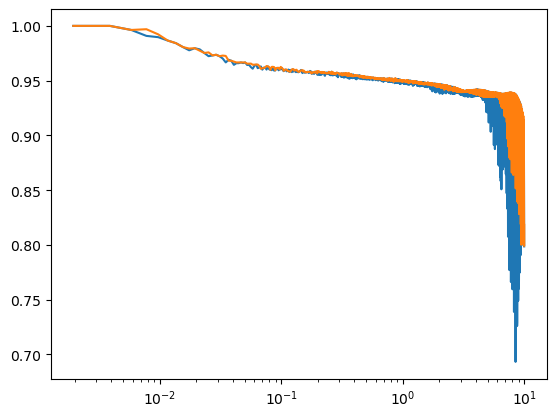

In [88]:
%matplotlib inline
plt.semilogx(taus3pb,V3pb)
plt.semilogx(taus3pbo,V3pbo)

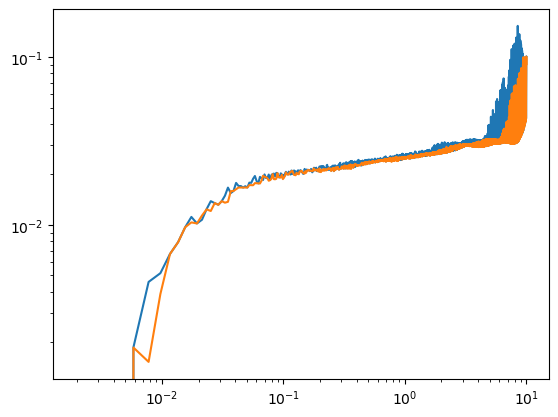

In [90]:
plt.loglog(taus3pb,QBER3pb)
plt.loglog(taus3pbo,QBER3pbo)

In [92]:
taus4pb, V4pb, QBER4pb, V_err4pb, QBER_err4pb, tau_err4pb, diags4pb = point_binned_visibility(ts4, cs4, n_taus=10000,tau_max=10, log_bins=True)


[Sample spacing diagnostics]
  n = 106349, duration = 206.478336 s
  mean Δt = 1.941535e-03 s, std = 3.692273e-04 s, CV = 0.19
  min/median/max Δt = 8.260000e-04 / 1.982000e-03 / 3.406000e-03 s
  1–99% Δt = 9.970000e-04 … 2.816000e-03 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  1.941535e-03    106349  0.000000e+00  0.000000e+00      nan  1.941535e-03  1.941535e-03
  2       2  0.00  3.883069e-03     53174  1.944509e-03  3.672271e-04    0.189  1.973036e-03  3.057069e-03
  3       3  0.00  5.824604e-03     35449  3.882384e-03  3.973803e-04    0.102  1.982455e-03  3.015604e-03
  4       4  0.00  7.766139e-03     26587  5.827199e-03  4.027252e-04   0.0691  1.980320e-03  3.033139e-03
  5       5  0.00  9.707674e-03     21269  7.766814e-03  4.119046e-04    0.053  1.984085e-03  3.027674e-03
  6       6  0.00  1.164921e-02     17724  9.709016e-03  4.017136e-04   0.0414  1

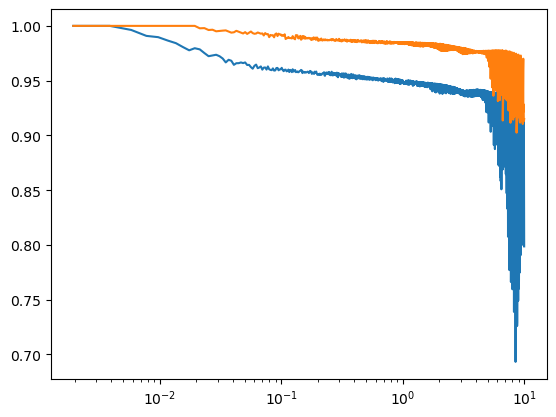

In [94]:

plt.semilogx(taus3pb,V3pb)
plt.semilogx(taus4pb,V4pb)

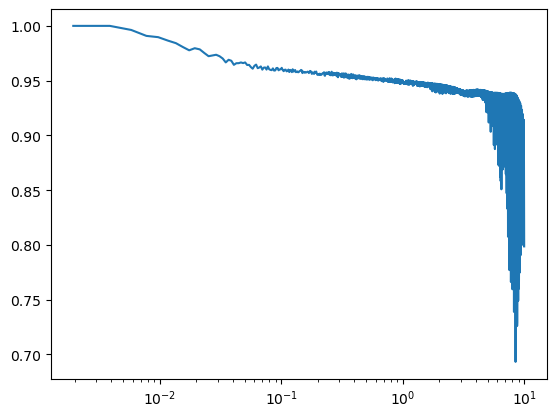

In [96]:
plt.semilogx(taus3pb,V3pb)

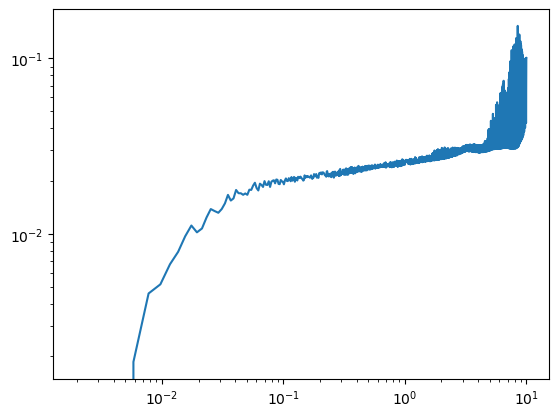

In [98]:
plt.loglog(taus3pb,QBER3pb)

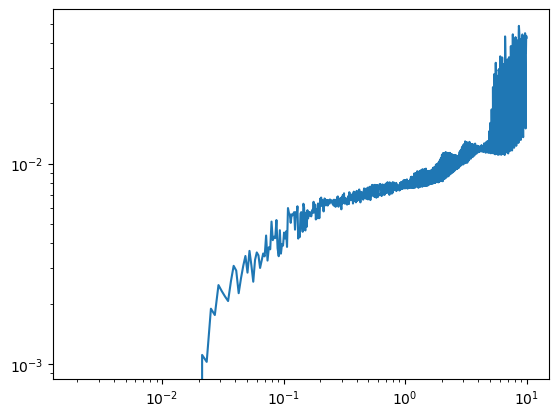

In [100]:
plt.loglog(taus4pb,QBER4pb)

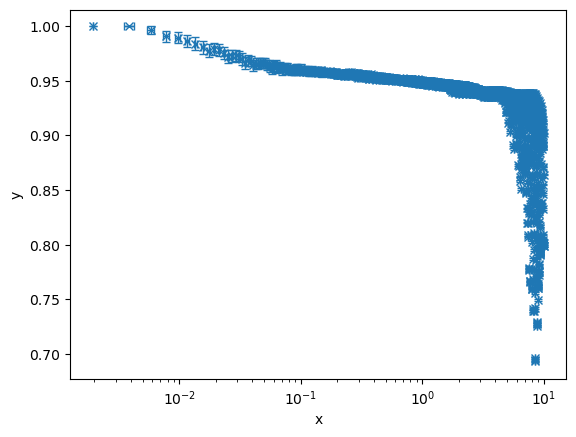

In [447]:
import numpy as np
import matplotlib.pyplot as plt
# Example data (must be >0 for log-x)
x  = taus3pb
y  = V3pb

# Symmetric errors
xerr = tau_err3pb
yerr = V_err3pb

fig, ax = plt.subplots()

ax.errorbar(
    x, y, yerr=yerr, xerr=xerr,
    fmt='x', capsize=3, elinewidth=1, markeredgewidth=1
)

ax.set_xscale('log')            # <- semilogx behavior
ax.set_xlabel('x')
ax.set_ylabel('y')
#ax.grid(True, which='both', ls=':')

plt.show()

In [102]:
import numpy as np

# ---------- time helpers ----------
def _timestr_to_seconds(tstr: str) -> float:
    h, m, s, us = tstr.split(':')
    return (int(h) * 3600) + (int(m) * 60) + int(s) + int(us) / 1e6

def _unwrap_seconds(sec: np.ndarray) -> np.ndarray:
    if sec.size <= 1:
        return sec.astype(float)
    out = sec.astype(float).copy()
    add = 0.0
    for i in range(1, sec.size):
        if sec[i] < sec[i-1]:
            add += 86400.0  # day rollover
        out[i] += add
    return out

def _seconds_to_timestr(t: float) -> str:
    # format seconds (can exceed 24h); we fold modulo 86400 for the string
    t_mod = t % 86400.0
    h = int(t_mod // 3600)
    m = int((t_mod % 3600) // 60)
    s = int(t_mod % 60)
    us = int(round((t_mod - int(t_mod)) * 1e6))
    # handle rounding to next second
    if us == 1_000_000:
        us = 0; s += 1
        if s == 60:
            s = 0; m += 1
            if m == 60:
                m = 0; h = (h + 1) % 24
    return f"{h:02d}:{m:02d}:{s:02d}:{us:06d}"

# ---------- main ----------
def bin_by_tau_point(
    ts,
    counts,
    tau: float,
    ts_mode: str = "start",          # 'start' | 'end' | 'center'
    include_partial: str = "drop"    # 'drop' | 'keep' | 'normalize'
):
    """
    Bin by a single τ using point-binning (K samples per bin, K ≈ tau / mean Δt).

    Parameters
    ----------
    ts : array-like of str ('HH:MM:SS:ffffff')
    counts : array-like of non-negative numbers
    tau : float, target bin size in seconds
    ts_mode : which timestamp to emit per bin:
        'start' -> first sample's original timestamp (default)
        'end'   -> last sample's original timestamp
        'center'-> mean time of samples in the bin (formatted back to string)
    include_partial : how to treat the final short bin (<K samples):
        'drop'      -> drop it (same as earlier code) [default]
        'keep'      -> keep raw sum (short bin often becomes Nmin)
        'normalize' -> scale the short-bin sum by K/L to be comparable to full bins

    Returns
    -------
    ts_binned : np.ndarray of str, one timestamp per bin
    counts_binned : np.ndarray of float, sum per bin (normalized if requested)
    info : dict with metadata (K, tau_effective, n_bins, dropped_samples, etc.)
    """
    ts = np.asarray(ts).astype(str)
    x  = np.clip(np.nan_to_num(np.asarray(counts), nan=0.0), 0, None)
    n = min(ts.size, x.size)
    ts = ts[:n]; x = x[:n]
    if n < 1:
        return np.array([], dtype=str), np.array([], dtype=float), {
            "K": 0, "tau_effective": np.nan, "n_bins": 0, "dropped_samples": 0
        }

    # Parse / unwrap time, compute mean Δt and K from tau
    secs = _unwrap_seconds(np.fromiter((_timestr_to_seconds(s) for s in ts), dtype=float, count=n))
    if n < 2:
        # only one point -> one-bin result if include_partial!='drop'
        if include_partial == "drop":
            return np.array([], dtype=str), np.array([], dtype=float), {
                "K": 1, "tau_effective": np.nan, "n_bins": 0, "dropped_samples": 1
            }
        # keep/normalize: single bin with that point
        ts_b = np.array([ts[0]])
        cnts = np.array([x[0]], dtype=float)
        return ts_b, cnts, {"K": 1, "tau_effective": 0.0, "n_bins": 1, "dropped_samples": 0}

    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing.")
    dt_mean = float(np.mean(dt_pos))

    K = max(1, int(np.rint(float(tau) / dt_mean)))
    tau_eff = K * dt_mean

    # Build bins of K samples
    if include_partial == "drop":
        n_full = (n // K) * K
        starts = np.arange(0, n_full, K, dtype=int)
        lens = np.full_like(starts, K)
        dropped = n - n_full
    else:
        n_bins = int(np.ceil(n / K))
        starts = np.arange(0, n_bins * K, K, dtype=int)
        lens = np.minimum(K, n - starts)
        lens = lens[lens > 0]
        starts = starts[:lens.size]
        dropped = 0

    # Sums per bin
    sums = np.add.reduceat(x, starts)
    sums = sums[:lens.size]  # guard
    if include_partial == "normalize":
        # scale short bins to K-sample equivalent
        scale = (K / lens.astype(float))
        sums = sums * scale

    # Timestamp per bin
    if ts_mode == "start":
        ts_binned = ts[starts]
    elif ts_mode == "end":
        ts_binned = ts[starts + lens - 1]
    elif ts_mode == "center":
        centers = []
        for s0, L in zip(starts, lens):
            t_mean = float(np.mean(secs[s0:s0+L]))
            centers.append(_seconds_to_timestr(t_mean))
        ts_binned = np.array(centers, dtype=object)
    else:
        raise ValueError("ts_mode must be one of {'start','end','center'}")

    info = {
        "K": int(K),
        "tau_effective": float(tau_eff),
        "requested_tau": float(tau),
        "n_bins": int(len(sums)),
        "dropped_samples": int(dropped),
        "include_partial": include_partial,
        "ts_mode": ts_mode,
    }
    return ts_binned, sums.astype(float), info


In [104]:
ts13,cs13=meas_arr2[13][1],meas_arr2[13][3]
ts11,cs11=meas_arr2[11][1],meas_arr2[11][3]

In [106]:
%matplotlib inline
ts_b, counts_b, meta = bin_by_tau_point(ts11, cs11, tau=0.0125, ts_mode="start", include_partial="normalize")
ts_b=ts_to_seconds_since_start(ts_b)

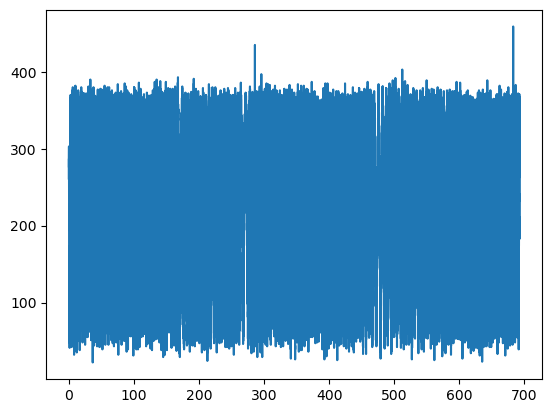

In [108]:
plt.plot(ts_b,counts_b)

In [110]:
ts_b2, counts_b2, meta2 = bin_by_tau_point(ts4, cs4, tau=10, ts_mode="start", include_partial="normalize")

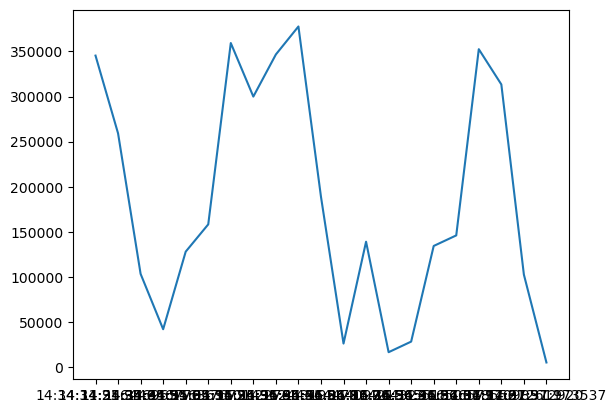

In [112]:
plt.plot(ts_b2,counts_b2)

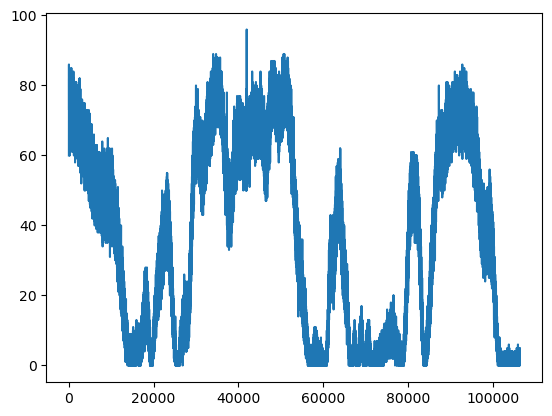

In [114]:
plt.plot(meas_arr2[4][2],meas_arr2[4][3])

In [116]:
ts12,cs12=meas_arr2[12][1],meas_arr2[12][3]

In [118]:
taus11a, V11a, QBER11a, _, _, _, _ = point_binned_visibility(ts11, cs11, n_taus=10000,tau_max=100, log_bins=True)


[Sample spacing diagnostics]
  n = 356922, duration = 693.014160 s
  mean Δt = 1.941646e-03 s, std = 3.627580e-04 s, CV = 0.187
  min/median/max Δt = 8.900000e-04 / 1.968000e-03 / 5.987000e-03 s
  1–99% Δt = 9.970000e-04 … 2.823000e-03 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  1.941646e-03    356922  0.000000e+00  0.000000e+00      nan  1.941646e-03  1.941646e-03
  2       2  0.00  3.883292e-03    178461  1.941240e-03  3.625696e-04    0.187  1.975606e-03  2.985292e-03
  3       3  0.00  5.824937e-03    118974  3.882058e-03  3.854415e-04   0.0993  1.980743e-03  3.064937e-03
  4       4  0.00  7.766583e-03     89230  5.824944e-03  3.949864e-04   0.0678  1.981407e-03  3.034583e-03
  5       5  0.00  9.708229e-03     71384  7.766955e-03  3.996119e-04   0.0515  1.981977e-03  3.031229e-03
  6       6  0.00  1.164987e-02     59487  9.706727e-03  3.978746e-04    0.041  

In [119]:
taus11b, V11b, QBER11b, _, _, _, _ = point_binned_visibility(ts11, cs11, n_taus=10000,tau_max=100, log_bins=True, overlap=0.5)


[Sample spacing diagnostics]
  n = 356922, duration = 693.014160 s
  mean Δt = 1.941646e-03 s, std = 3.627580e-04 s, CV = 0.187
  min/median/max Δt = 8.900000e-04 / 1.968000e-03 / 5.987000e-03 s
  1–99% Δt = 9.970000e-04 … 2.823000e-03 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  1.941646e-03    356922  0.000000e+00  0.000000e+00      nan  1.941646e-03  1.941646e-03
  2       1  0.50  3.883292e-03    356921  1.941646e-03  3.627580e-04    0.187  1.975242e-03  2.993292e-03
  3       2  0.33  5.824937e-03    178460  3.883297e-03  3.861395e-04   0.0994  1.979664e-03  3.062937e-03
  4       2  0.50  7.766583e-03    178460  5.824537e-03  3.944082e-04   0.0677  1.981692e-03  3.039583e-03
  5       2  0.60  9.708229e-03    178459  7.766593e-03  3.991476e-04   0.0514  1.982239e-03  3.200229e-03
  6       3  0.50  1.164987e-02    118973  9.707002e-03  3.972056e-04   0.0409  

In [120]:
taus12a, V12a, QBER12a, _, _, _, _ = point_binned_visibility(ts12, cs12, n_taus=10000,tau_max=100, log_bins=True)


[Sample spacing diagnostics]
  n = 179188, duration = 347.971506 s
  mean Δt = 1.941946e-03 s, std = 3.528116e-04 s, CV = 0.182
  min/median/max Δt = 8.610000e-04 / 1.988000e-03 / 5.986000e-03 s
  1–99% Δt = 9.970000e-04 … 2.820000e-03 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  1.941946e-03    179188  0.000000e+00  0.000000e+00      nan  1.941946e-03  1.941946e-03
  2       2  0.00  3.883892e-03     89594  1.942713e-03  3.523950e-04    0.181  1.972906e-03  3.022892e-03
  3       3  0.00  5.825838e-03     59729  3.884018e-03  3.827049e-04   0.0985  1.979173e-03  3.053838e-03
  4       4  0.00  7.767785e-03     44797  5.825413e-03  3.948521e-04   0.0678  1.982098e-03  3.019785e-03
  5       5  0.00  9.709731e-03     35837  7.767527e-03  4.021941e-04   0.0518  1.983409e-03  3.042731e-03
  6       6  0.00  1.165168e-02     29864  9.711232e-03  4.033617e-04   0.0415  

In [121]:
taus12b, V12b, QBER12b, _, _, _, _ = point_binned_visibility(ts12, cs12, n_taus=10000,tau_max=100, log_bins=True, overlap=0.5)


[Sample spacing diagnostics]
  n = 179188, duration = 347.971506 s
  mean Δt = 1.941946e-03 s, std = 3.528116e-04 s, CV = 0.182
  min/median/max Δt = 8.610000e-04 / 1.988000e-03 / 5.986000e-03 s
  1–99% Δt = 9.970000e-04 … 2.820000e-03 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  1.941946e-03    179188  0.000000e+00  0.000000e+00      nan  1.941946e-03  1.941946e-03
  2       1  0.50  3.883892e-03    179187  1.941946e-03  3.528116e-04    0.182  1.973735e-03  3.022892e-03
  3       2  0.33  5.825838e-03     89593  3.883892e-03  3.832293e-04   0.0987  1.979399e-03  3.048838e-03
  4       2  0.50  7.767785e-03     89593  5.826604e-03  3.945363e-04   0.0677  1.980868e-03  3.039785e-03
  5       2  0.60  9.709731e-03     89592  7.767781e-03  4.040294e-04    0.052  1.983534e-03  3.102731e-03
  6       3  0.50  1.165168e-02     59728  9.709852e-03  4.033978e-04   0.0415  

Text(0, 0.5, 'Estimated Maximum Visibility')

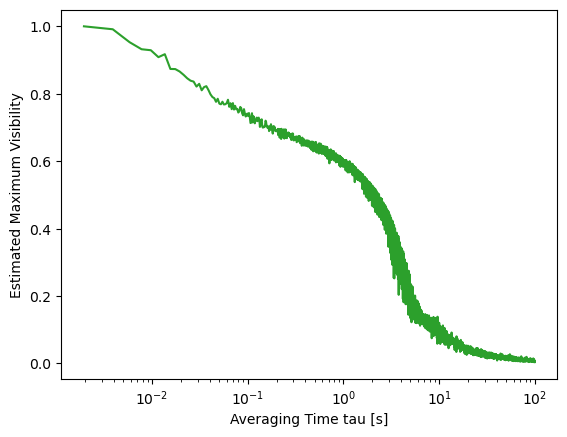

In [126]:
plt.semilogx(taus11a, V11a, color='tab:green')

plt.xlabel('Averaging Time tau [s]')
plt.ylabel('Estimated Maximum Visibility')

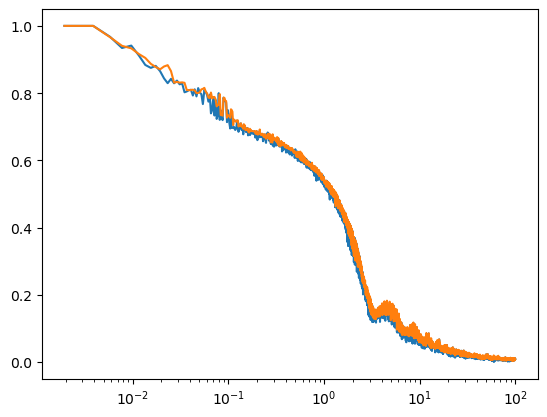

In [128]:
plt.semilogx(taus12a, V12a)
plt.semilogx(taus12b, V12b)

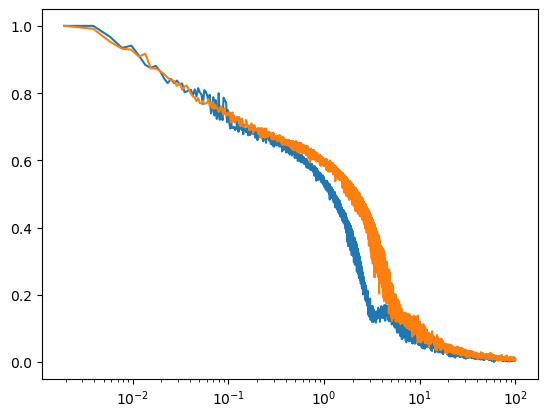

In [130]:
plt.semilogx(taus12a, V12a)
plt.semilogx(taus11a, V11a)

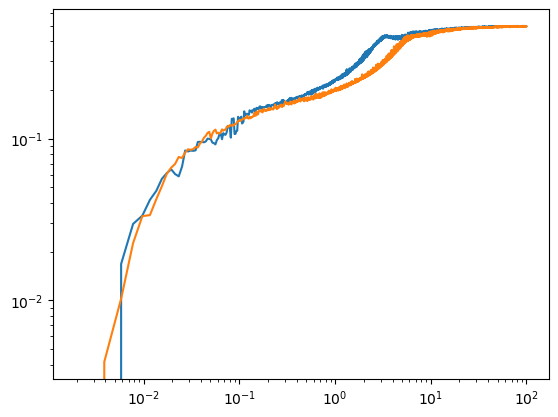

In [132]:
plt.loglog(taus12b, QBER12b)
plt.loglog(taus11b, QBER11b)

In [134]:
import numpy as np
from typing import Optional, Tuple

def rolling_visibility_segments(
    ts: np.ndarray,
    counts: np.ndarray,
    phase_length: float,
    overlap: Optional[float] = None,
    min_points: int = 2,   # require at least this many samples per segment
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Slide a window of length `phase_length` (s) across the data (optionally overlapped),
    and compute per-segment visibility and its analytic 1σ error assuming Poisson counts.

    Visibility in a segment:
        A = max(counts in segment)
        B = min(counts in segment)
        V = (A - B) / (A + B)
        σ_V = sqrt( 4 A B / (A + B)^3 )

    Parameters
    ----------
    ts : array-like of float
        Timestamps in seconds (nondecreasing).
    counts : array-like of float
        Non-negative counts per sample (same length/order as ts).
    phase_length : float
        Segment duration (seconds), must be > 0.
    overlap : None or float in [0,1)
        If None: non-overlapping segments (stride = phase_length).
        Else: stride = phase_length * (1 - overlap). Example: 0.5 -> 50% overlap.
    min_points : int
        Minimum number of samples required in a segment to compute visibility.

    Returns
    -------
    t_centers : np.ndarray (float)
        Center time of each segment (start + phase_length/2).
    V : np.ndarray (float)
        Visibility per segment (NaN when undefined).
    V_err : np.ndarray (float)
        Analytic 1σ error per segment (NaN when undefined).
    """
    ts = np.asarray(ts, dtype=float)
    x  = np.asarray(counts, dtype=float)

    if ts.size != x.size:
        raise ValueError("ts and counts must have the same length.")
    if ts.size == 0:
        return np.array([], float), np.array([], float), np.array([], float)
    if phase_length <= 0:
        raise ValueError("phase_length must be > 0.")

    # stride from overlap
    if overlap is None:
        stride = phase_length
    else:
        if not (0.0 <= overlap < 1.0):
            raise ValueError("overlap must be in [0, 1) or None.")
        stride = phase_length * (1.0 - overlap)
        if stride <= 0:
            stride = np.finfo(float).eps  # guard

    # sanitize counts (non-negative, finite)
    x = np.clip(np.nan_to_num(x, nan=0.0), 0.0, None)

    t0, t1 = ts[0], ts[-1]
    if (t1 - t0) < phase_length:
        return np.array([], float), np.array([], float), np.array([], float)

    # build segment starts and centers
    n_segs = int(np.floor((t1 - t0 - phase_length) / stride)) + 1
    starts  = t0 + np.arange(n_segs, dtype=float) * stride
    centers = starts + 0.5 * phase_length

    V     = np.full(n_segs, np.nan, dtype=float)
    V_err = np.full(n_segs, np.nan, dtype=float)

    # two-pointer sweep
    i_start = 0
    i_end   = 0
    N = ts.size

    for k, s in enumerate(starts):
        seg_end = s + phase_length
        # advance to segment bounds
        while i_start < N and ts[i_start] < s:
            i_start += 1
        if i_end < i_start:
            i_end = i_start
        while i_end < N and ts[i_end] < seg_end:
            i_end += 1

        L = i_end - i_start
        if L >= min_points:
            seg_vals = x[i_start:i_end]
            A = float(np.max(seg_vals))
            B = float(np.min(seg_vals))
            den = A + B
            if den > 0:
                V[k] = (A - B) / den
                # analytic 1σ (delta-method, treating A,B independent Poisson)
                V_err[k] = np.sqrt(4.0 * A * B / (den ** 3))
            else:
                V[k] = np.nan
                V_err[k] = np.nan
        else:
            V[k] = np.nan
            V_err[k] = np.nan

    return centers, V, V_err


In [136]:
ts_b, counts_b, meta = bin_by_tau_point(ts11, cs11, tau=0.0125, ts_mode="start", include_partial="normalize")
ts_b=ts_to_seconds_since_start(ts_b)

Text(0, 0.5, 'Counts (per 6.25/500 s)')

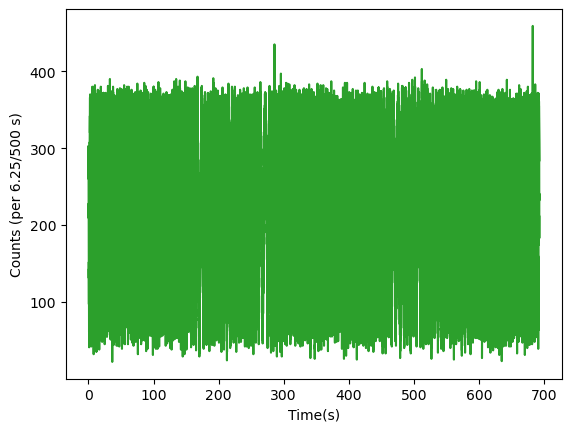

In [138]:
plt.plot(ts_b,counts_b, color='tab:green')
plt.xlabel('Time(s)')
plt.ylabel('Counts (per 6.25/500 s)')

In [140]:
ts11rv,V11rv, V11rver=rolling_visibility_segments(ts_b,counts_b,phase_length=6, overlap=None)

In [142]:
ts11rvo,V11rvo, V11rvoer=rolling_visibility_segments(ts_b,counts_b,phase_length=6, overlap=0.75)

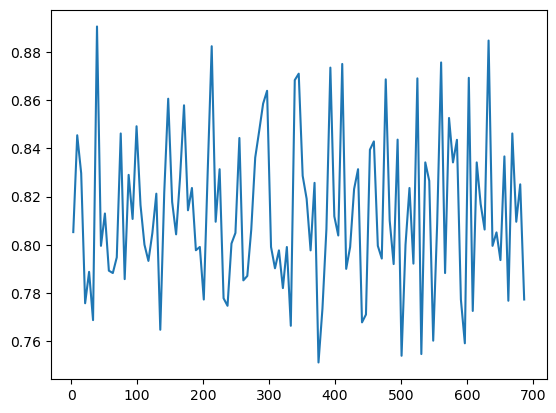

In [144]:
plt.plot(ts11rv,V11rv)
#plt.plot(ts11rvo,V11rvo)

In [146]:
ts12,cs12=meas_arr2[12][1],meas_arr2[12][3]
ts13,cs13=meas_arr2[13][1],meas_arr2[13][3]

In [148]:
ts12_b, counts12_b, _ = bin_by_tau_point(ts12, cs12, tau=0.0125, ts_mode="start", include_partial="normalize")
ts12_b=ts_to_seconds_since_start(ts12_b)

In [150]:
ts13_b, counts13_b, _ = bin_by_tau_point(ts13, cs13, tau=0.0125, ts_mode="start", include_partial="normalize")
ts13_b=ts_to_seconds_since_start(ts13_b)

In [228]:
edges13, centers13, y_mean13, count3 = binned_average(ts13_b, counts13_b, n_bins=100)

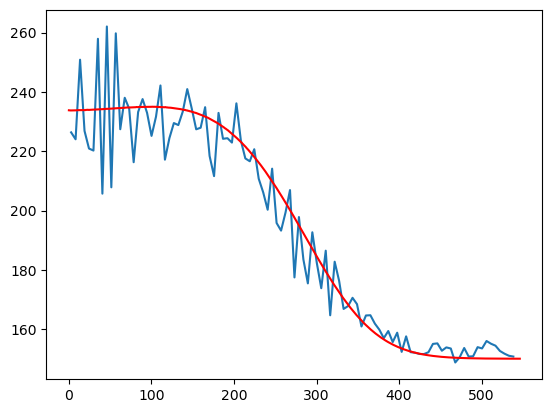

In [240]:
plt.plot(centers13, y_mean13)
psnew=(ps/np.max(ps))
#psnew2=(np.max(psnew)-psnew)/(np.max(psnew)+np.min(psnew))
psnew2=(psnew*85)+150
vsnew=(vs*100)*(547.3046329999999/501)
plt.plot(vsnew,psnew2,color='red', label='Optical Power*0.4/VOA Voltage')


In [154]:
ts12rv,V12rv, V12rver=rolling_visibility_segments(ts12_b,counts12_b,phase_length=6, overlap=None)
ts12rvo,V12rvo, V12rvoer=rolling_visibility_segments(ts12_b,counts12_b,phase_length=6, overlap=0.5)

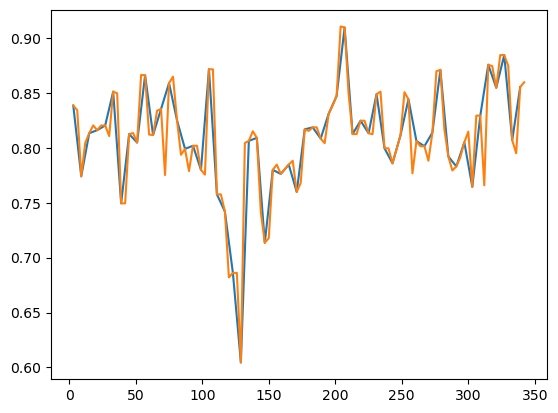

In [156]:
%matplotlib inline
plt.plot(ts12rv,V12rv)
plt.plot(ts12rvo,V12rvo)

In [158]:
ts13rv,V13rv, V13rver=rolling_visibility_segments(ts13_b,counts13_b,phase_length=6, overlap=None)
ts13rvo,V13rvo, V13rvoer=rolling_visibility_segments(ts13_b,counts13_b,phase_length=6, overlap=0.5)

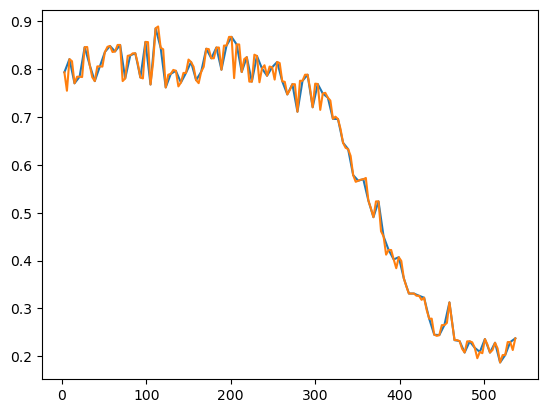

In [160]:
plt.plot(ts13rv,V13rv)
plt.plot(ts13rvo,V13rvo)

<ErrorbarContainer object of 3 artists>

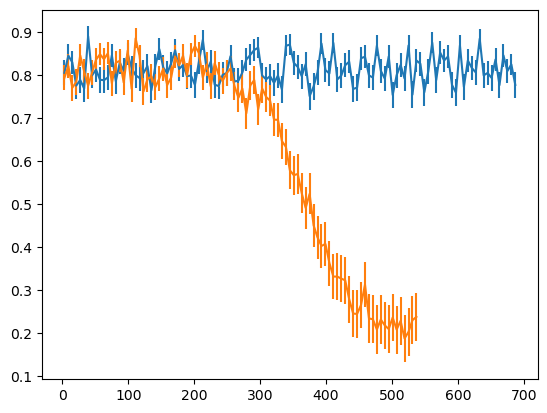

In [162]:
plt.errorbar(ts11rv,V11rv,yerr=V11rver)
#plt.errorbar(ts12rv,V12rv,yerr=V12rver)
plt.errorbar(ts13rv,V13rv,yerr=V13rver)


In [164]:
ps=np.load(r'D:\PhD Thesis Writing\Data\2025-06-04\psfixed.npy')
vs=np.load(r'D:\PhD Thesis Writing\Data\2025-06-04\vsfixed.npy')

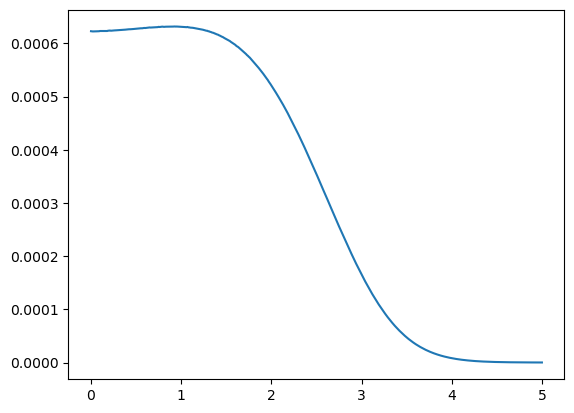

In [166]:
plt.plot(vs,ps)

<ErrorbarContainer object of 3 artists>

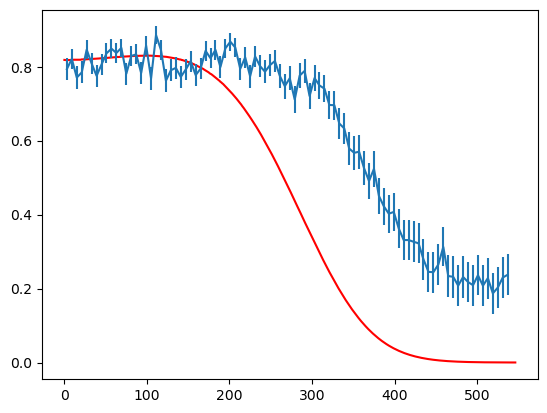

In [214]:
psnew=(ps/np.max(ps))
#psnew2=(np.max(psnew)-psnew)/(np.max(psnew)+np.min(psnew))
psnew2=(psnew*0.83)
vsnew=(vs*100)*(547.3046329999999/501)
plt.plot(vsnew,psnew2,color='red', label='Optical Power*0.4/VOA Voltage')
plt.errorbar(ts13rv,V13rv,yerr=V13rver)
#plt.plot(vsnew,psnew)

In [176]:
psnew=ps/np.max(ps)
vsnew=vs*100

<ErrorbarContainer object of 3 artists>

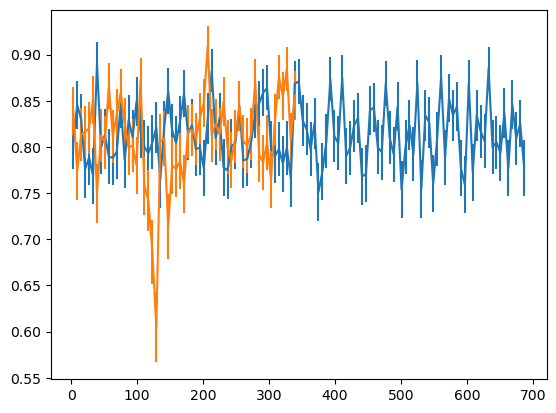

In [178]:
plt.errorbar(ts11rv,V11rv,yerr=V11rver)
plt.errorbar(ts12rv,V12rv,yerr=V12rver)

In [1542]:
np.save('ts11rv',ts11rv)
np.save('V11rv',V11rv)
np.save('V11rver',V11rver)

In [1544]:
np.save('ts12rv',ts12rv)
np.save('V12rv',V12rv)
np.save('V112ver',V12rver)

In [1546]:
np.save('ts13rv',ts13rv)
np.save('V13rv',V13rv)
np.save('V13rver',V13rver)

In [ ]:
np.save('ts11rv',ts11rv)
np.save('V11rv',V11rv)
np.save('V11rver',V11rver)
np.save('ts12rv',ts12rv)
np.save('V12rv',V12rv)
np.save('V112ver',V12rver)
np.save('ts13rv',ts13rv)
np.save('V13rv',V13rv)
np.save('V13rver',V13rver)

In [172]:
QBER11rv=(1-V11rv)/2
QBER12rv=(1-V12rv)/2
QBER13rv=(1-V13rv)/2

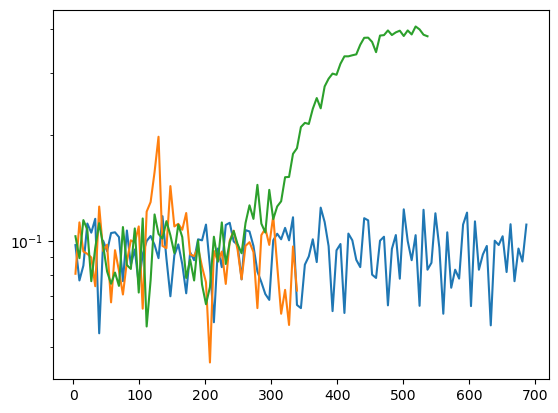

In [174]:
plt.semilogy(ts11rv,QBER11rv)
plt.semilogy(ts12rv,QBER12rv)
plt.semilogy(ts13rv,QBER13rv)

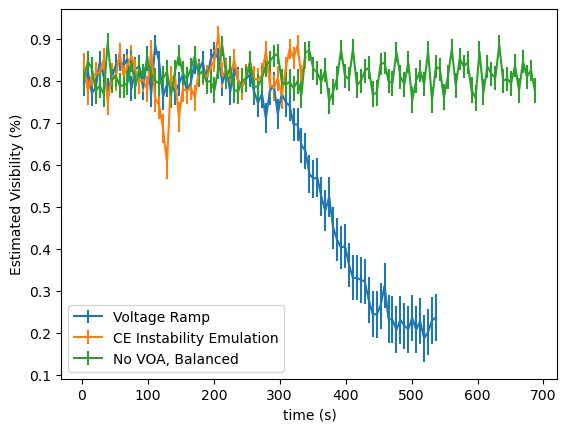

In [176]:
plt.errorbar(ts13rv,V13rv,yerr=V13rver, label='Voltage Ramp')
plt.errorbar(ts12rv,V12rv,yerr=V12rver, label='CE Instability Emulation')
plt.errorbar(ts11rv,V11rv,yerr=V11rver, label='No VOA, Balanced')
plt.xlabel('time (s)')
plt.ylabel('Estimated Visibility (%)')
plt.legend()

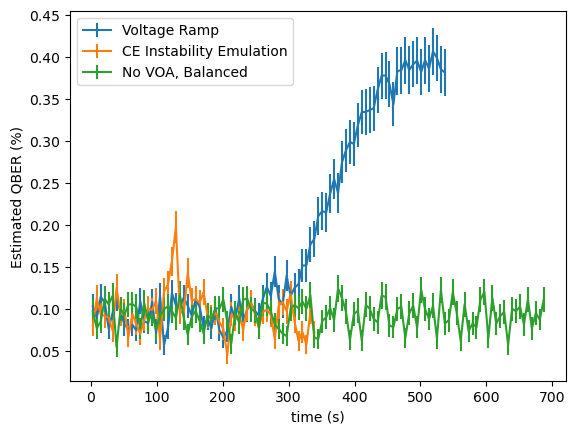

In [178]:
plt.errorbar(ts13rv,QBER13rv,yerr=0.5*V13rver, label='Voltage Ramp')
plt.errorbar(ts12rv,QBER12rv,yerr=0.5*V12rver, label='CE Instability Emulation')
plt.errorbar(ts11rv,QBER11rv,yerr=0.5*V11rver, label='No VOA, Balanced')
plt.xlabel('time (s)')
plt.ylabel('Estimated QBER (%)')
plt.legend()

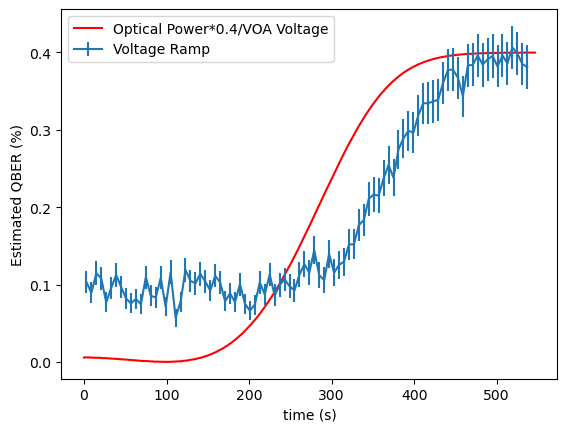

In [188]:
psnew=(ps/np.max(ps))
psnew2=(np.max(psnew)-psnew)/(np.max(psnew)+np.min(psnew))
psnew2=psnew2*0.4
vsnew=(vs*100)*(547.3046329999999/501)
plt.plot(vsnew,psnew2,color='red', label='Optical Power*0.4/VOA Voltage')
plt.errorbar(ts13rv,QBER13rv,yerr=0.5*V13rver,color='tab:blue', label='Voltage Ramp')
plt.xlabel('time (s)')
plt.ylabel('Estimated QBER (%)')
plt.legend()

<ErrorbarContainer object of 3 artists>

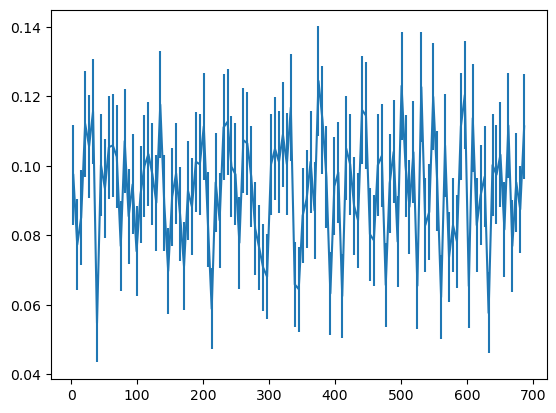

In [393]:
plt.errorbar(ts11rv,QBER11rv,yerr=0.5*V11rver)

In [141]:
import numpy as np
import matplotlib.pyplot as plt

def plot_visibility_comparison(
    V_ref, V_cmp, t_ref=None, t_cmp=None,
    V_ref_err=None, V_cmp_err=None,
    ref_label="reference (orange)", cmp_label="comparison (blue)"
):
    """
    Compare two visibility series: reference (orange) vs comparison (blue).
    - If both time vectors are given, aligns by index order (assumes already paired).
    - Shows: overlaid series, residuals (cmp - ref), and scatter with y=x.
    - Prints bias / RMSE / corr.
    """
    V_ref = np.asarray(V_ref, float)
    V_cmp = np.asarray(V_cmp, float)

    n = min(V_ref.size, V_cmp.size)
    V_ref, V_cmp = V_ref[:n], V_cmp[:n]
    if t_ref is None: t_ref = np.arange(n)
    if t_cmp is None: t_cmp = np.arange(n)
    t_ref, t_cmp = np.asarray(t_ref)[:n], np.asarray(t_cmp)[:n]

    # basic stats (ignore NaNs)
    m = np.isfinite(V_ref) & np.isfinite(V_cmp)
    bias = np.nanmean(V_cmp[m] - V_ref[m]) if np.any(m) else np.nan
    rmse = np.sqrt(np.nanmean((V_cmp[m] - V_ref[m])**2)) if np.any(m) else np.nan
    corr = np.corrcoef(V_ref[m], V_cmp[m])[0,1] if np.sum(m) > 1 else np.nan
    print(f"bias = {bias:.4g},  RMSE = {rmse:.4g},  corr = {corr:.3g}  (n={np.sum(m)})")

    fig = plt.figure(figsize=(11, 8))
    gs = fig.add_gridspec(2, 2, height_ratios=[2,1], width_ratios=[2,1], hspace=0.25, wspace=0.25)

    # (A) Overlaid time series
    ax1 = fig.add_subplot(gs[0, 0])
    if V_ref_err is None:
        ax1.plot(t_ref[m], V_ref[m], color='tab:orange', label=ref_label, alpha=0.9)
    else:
        ax1.errorbar(t_ref[m], V_ref[m], yerr=np.asarray(V_ref_err)[:n][m],
                     fmt='o', ms=2, capsize=2, color='tab:orange', label=ref_label, alpha=0.9)
    if V_cmp_err is None:
        ax1.plot(t_cmp[m], V_cmp[m], color='tab:blue', label=cmp_label, alpha=0.9)
    else:
        ax1.errorbar(t_cmp[m], V_cmp[m], yerr=np.asarray(V_cmp_err)[:n][m],
                     fmt='o', ms=2, capsize=2, color='tab:blue', label=cmp_label, alpha=0.9)
    ax1.set_ylabel("Visibility V")
    ax1.legend(loc="best")
    ax1.grid(True, ls=":")

    # (B) Residuals vs time
    ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
    resid = V_cmp - V_ref
    ax2.axhline(0, color='k', lw=1)
    ax2.plot(t_ref[m], resid[m], '.', alpha=0.7, color='tab:blue')
    ax2.set_xlabel("Time / index")
    ax2.set_ylabel("Residual (cmp − ref)")
    ax2.grid(True, ls=":")

    # (C) Scatter with identity line
    ax3 = fig.add_subplot(gs[:, 1])
    lim_lo = np.nanmin([V_ref[m].min(), V_cmp[m].min()])
    lim_hi = np.nanmax([V_ref[m].max(), V_cmp[m].max()])
    pad = 0.02 * (lim_hi - lim_lo if np.isfinite(lim_hi - lim_lo) else 1.0)
    ax3.plot([lim_lo-pad, lim_hi+pad], [lim_lo-pad, lim_hi+pad], 'k--', lw=1, label='y=x')
    ax3.plot(V_ref[m], V_cmp[m], '.', alpha=0.7, color='tab:blue')
    ax3.set_xlabel("V (reference)")
    ax3.set_ylabel("V (comparison)")
    ax3.set_aspect('equal', adjustable='box')
    ax3.grid(True, ls=":")
    ax3.legend(loc="best")

    plt.show()

<ErrorbarContainer object of 3 artists>

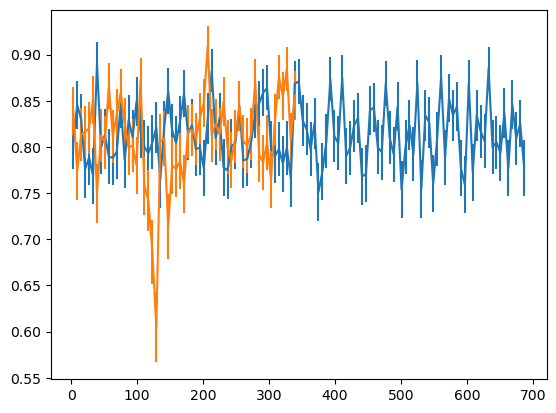

In [186]:
plt.errorbar(ts11rv,V11rv,yerr=V11rver)
plt.errorbar(ts12rv,V12rv,yerr=V12rver)

bias = -0.005102,  RMSE = 0.06187,  corr = -0.189  (n=57)


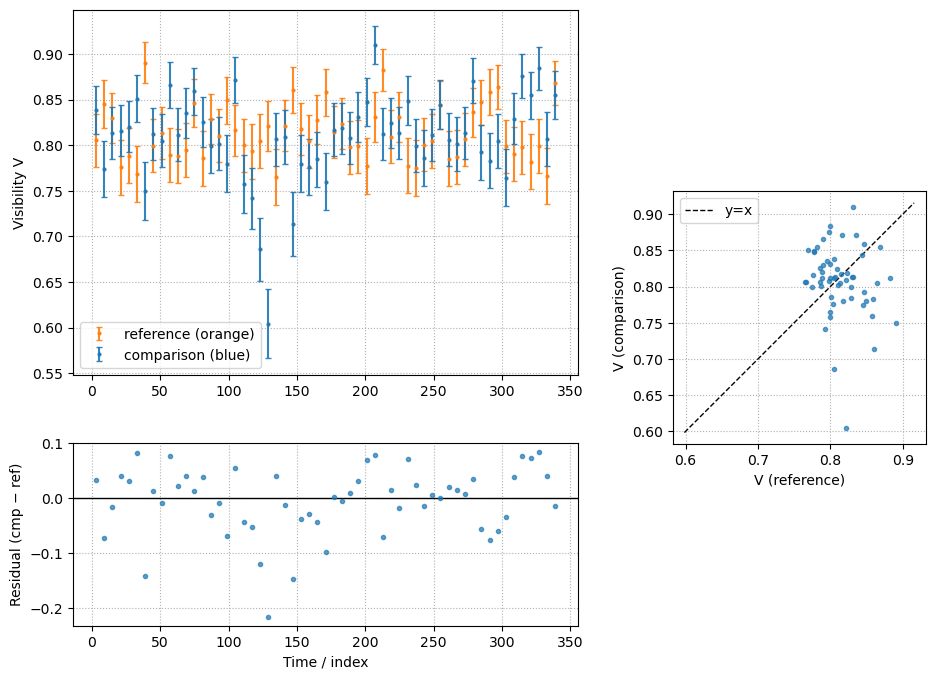

In [188]:
plot_visibility_comparison(V11rv, V12rv, t_ref=ts11rv, t_cmp=ts12rv,V_ref_err=V11rver, V_cmp_err=V12rver)

In [143]:
import numpy as np

def continuous_visibility_adaptive(
    ts, counts,
    period_bounds=(2.5, 5.0),      # expected fringe period range (s)
    dt_resample=0.05,              # resampling step (s)
    bins_per_period=8,             # time bins per period for bin-sums
    window_factor=1.5,             # L(t) = window_factor * T_hat(t)
    overlap=0.75,                  # fraction overlap for windows (0.. <1)
    min_points_per_window=8,       # guard: need at least this many samples
):
    """
    Return (t_centers, V, V_err, T_est) for a continuous, adaptive visibility estimate.

    Steps per center time:
      1) Estimate local period T_hat via short-time autocorrelation.
      2) Set window length L = window_factor * T_hat (clipped to period_bounds).
      3) Bin the window into M ≈ bins_per_period * (L/T_hat) ≈ bins_per_period * window_factor bins.
      4) Sum counts per bin, compute V from max/min bin-sums and its analytic Poisson error.

    Parameters
    ----------
    ts : array-like, seconds, nondecreasing
    counts : array-like, non-negative
    period_bounds : (T_min, T_max) in seconds
    dt_resample : float, resampling step for uniform grid (s)
    bins_per_period : int
    window_factor : float, multiplier of local period for window length
    overlap : float in [0,1), window overlap fraction
    min_points_per_window : int, guard for tiny windows

    Returns
    -------
    t_centers : np.ndarray
    V         : np.ndarray
    V_err     : np.ndarray  (analytic 1σ, Poisson, delta-method)
    T_est     : np.ndarray  (local period estimates used)
    """
    ts = np.asarray(ts, float)
    x  = np.asarray(counts, float)
    n  = min(ts.size, x.size)
    ts = ts[:n]; x = np.clip(np.nan_to_num(x, nan=0.0), 0, None)[:n]
    if n < 2:
        return np.array([]), np.array([]), np.array([]), np.array([])

    T_min, T_max = period_bounds
    T_min = max(T_min, dt_resample*2)
    T_max = max(T_max, T_min + dt_resample)

    # -- resample to uniform grid for stable autocorr/binning
    t0, t1 = ts[0], ts[-1]
    N_grid = int(np.floor((t1 - t0) / dt_resample)) + 1
    t_grid = t0 + np.arange(N_grid) * dt_resample
    # bin original counts to grid via histogram with weights
    grid_counts, _ = np.histogram(ts, bins=np.append(t_grid, t_grid[-1] + dt_resample), weights=x)
    # centers for analysis windows
    L_max = window_factor * T_max
    stride = (1.0 - overlap) * (window_factor * ((T_min + T_max) / 2.0))
    stride = max(dt_resample, stride)
    starts = np.arange(t0, t1 - L_max + dt_resample, stride)
    centers = starts + 0.5 * L_max   # temporary; we’ll recompute with local L

    # Prepare outputs
    t_centers = []
    V_list, Verr_list, Test_list = [], [], []

    # helper: local period from short-time autocorrelation on the grid
    def local_period(i0, i1):
        seg = grid_counts[i0:i1]
        if seg.size < 3:
            return np.nan
        # remove mean, compute FFT autocorr efficiently
        y = seg - seg.mean()
        nfft = 1
        while nfft < 2*seg.size:
            nfft <<= 1
        Y = np.fft.rfft(y, n=nfft)
        ac = np.fft.irfft(Y * np.conj(Y), n=nfft)[:seg.size]
        ac /= np.maximum(ac[0], 1e-12)
        # search for first local max in the lag range [T_min, T_max]
        lmin = int(np.round(T_min / dt_resample))
        lmax = int(np.round(T_max / dt_resample))
        if lmax >= seg.size:
            lmax = seg.size - 1
        if lmin < 1 or lmin >= lmax:
            return np.nan
        lag_slice = ac[lmin:lmax+1]
        lag_idx = np.argmax(lag_slice) + lmin
        return lag_idx * dt_resample

    # sweep windows
    for s in starts:
        # crude initial local period using a large window (2*T_max)
        half = int(np.round((2*T_max) / dt_resample))
        i_mid = int(np.clip((s + 0.5*L_max - t0) / dt_resample, 0, N_grid-1))
        i0p = max(0, i_mid - half)
        i1p = min(N_grid, i_mid + half)
        T_hat = local_period(i0p, i1p)
        if not np.isfinite(T_hat):
            # fallback: median of bounds
            T_hat = 0.5 * (T_min + T_max)
        T_hat = float(np.clip(T_hat, T_min, T_max))
        L = window_factor * T_hat

        # indices for the actual window [s, s+L)
        i0 = int(np.floor((s - t0) / dt_resample))
        i1 = int(np.floor((s + L - t0) / dt_resample))
        i0 = max(0, i0); i1 = min(N_grid, i1)
        seg = grid_counts[i0:i1]
        if seg.size < max(min_points_per_window, 3):
            continue

        # choose number of bins ≈ bins_per_period per period
        M = max(4, int(np.round(bins_per_period * (L / T_hat))))
        # make M (almost) equal-sized bins over the segment
        # use reduceat on chunk boundaries
        edges = np.linspace(0, seg.size, M+1).astype(int)
        sums = np.add.reduceat(seg, edges[:-1])
        # compute V from bin-sums (robust: you can use percentiles instead of pure min/max)
        A = float(np.max(sums))
        B = float(np.min(sums))
        den = A + B
        if den <= 0:
            continue
        V = (A - B) / den
        # analytic Poisson error (delta-method)
        V_err = np.sqrt(4.0 * A * B / (den**3))

        # store
        t_centers.append(s + 0.5 * L)
        V_list.append(V)
        Verr_list.append(V_err)
        Test_list.append(T_hat)

    return np.array(t_centers), np.array(V_list), np.array(Verr_list), np.array(Test_list)


In [190]:
t_c, V, V_err, T_local = continuous_visibility_adaptive(
    ts_b,counts_b,
    period_bounds=(2.5, 6.0),
    dt_resample=0.005,        # 50 ms grid
    bins_per_period=40,
    window_factor=1.75,
    overlap=0.85,            # 75% overlap
)
# Example QBER with propagated error:
Q = 0.5*(1 - np.abs(V))
Q_err = 0.5*V_err

<ErrorbarContainer object of 3 artists>

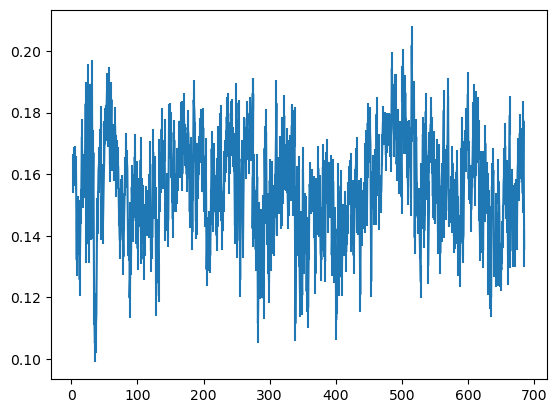

In [192]:
plt.errorbar(t_c,Q,yerr=Q_err)


<ErrorbarContainer object of 3 artists>

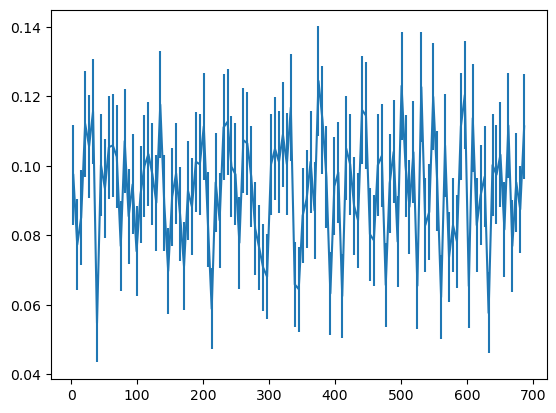

In [196]:
plt.errorbar(ts11rv,QBER11rv,yerr=0.5*V11rver)

In [198]:
import numpy as np
from scipy import stats

def mann_kendall(y):
    y = np.asarray(y, float)
    n = len(y)
    S = 0
    for i in range(n-1):
        S += np.sum(np.sign(y[i+1:] - y[i]))
    # variance under H0 with ties correction
    _, counts = np.unique(y, return_counts=True)
    tie_term = np.sum(counts*(counts-1)*(counts+1))
    varS = (n*(n-1)*(2*n+5) - tie_term) / 18.0
    z = 0.0
    if S > 0:  z = (S-1)/np.sqrt(varS)
    if S == 0: z = 0.0
    if S < 0:  z = (S+1)/np.sqrt(varS)
    p = 2*(1 - stats.norm.cdf(abs(z)))
    return {"S": S, "z": z, "p": p}

def pettitt_test(y):
    y = np.asarray(y, float)
    n = len(y)
    # rank-based statistic
    ranks = stats.rankdata(y)
    U = np.zeros(n)
    for t in range(n):
        U[t] = 2*np.sum(ranks[:t+1]) - (t+1)*(n+1)
    K = int(np.argmax(np.abs(U)))
    Uk = U[K]
    p = 2*np.exp((-6*(Uk**2)) / (n**3 + n**2))
    return {"k": K, "U": Uk, "p": float(min(1.0, p))}

def analyze_visibility_time(V, t=None, alpha=0.01):
    V = np.asarray(V, float)
    m = np.isfinite(V)
    V = V[m]
    if t is None:
        t = np.arange(len(m))[m]
    else:
        t = np.asarray(t, float)[m]
    t = t - t[0]

    # 1) Linear trend (OLS)
    A = np.vstack([t, np.ones_like(t)]).T
    beta, resid, _, _ = np.linalg.lstsq(A, V, rcond=None)
    slope, intercept = beta
    # standard errors
    dof = max(1, len(V) - 2)
    sigma2 = (np.sum((V - (slope*t + intercept))**2)) / dof
    cov = sigma2 * np.linalg.inv(A.T @ A)
    se_slope = np.sqrt(cov[0,0])
    tstat = slope / se_slope if se_slope > 0 else np.nan
    p_ols = 2 * (1 - stats.t.cdf(abs(tstat), dof))

    # 2) Monotonic trend (non-parametric)
    rho, p_spear = stats.spearmanr(t, V, nan_policy='omit')
    mk = mann_kendall(V)

    # 3) Step-like change (change-point)
    pet = pettitt_test(V)

    # simple ACF (first few lags) to spot serial correlation
    def acf(x, kmax=10):
        x = x - np.mean(x)
        c0 = np.dot(x, x)
        return np.array([np.dot(x[:-k], x[k:])/c0 for k in range(1, kmax+1)])
    acf_vals = acf(V, 10)

    verdicts = {
        "trend_detected": (p_ols < alpha) or (p_spear < alpha) or (mk["p"] < alpha),
        "changepoint_detected": pet["p"] < alpha
    }

    results = {
        "ols": {"slope_per_time": slope, "se": se_slope, "t": tstat, "p": p_ols},
        "spearman": {"rho": rho, "p": p_spear},
        "mann_kendall": mk,
        "pettitt": pet,
        "acf_lags_1to10": acf_vals,
        "verdicts@alpha": alpha,
        **verdicts
    }
    return results


In [200]:
import numpy as np
from scipy import stats

def summarize_visibility_errors(V, t=None, V_err=None, alpha=0.01, hac_lags=None):
    """
    Return confidence intervals for:
      - slope of V vs t (OLS; WLS if V_err given)
      - constant mean visibility (weighted or unweighted)
    Optionally also compute Newey–West (HAC) SE for the slope (requires statsmodels).

    Parameters
    ----------
    V : array-like
    t : array-like or None  (if None, use np.arange(n))
    V_err : array-like or None  (per-point 1σ; triggers WLS if provided)
    alpha : significance level for (1-alpha) CI (default 0.05 -> 95% CI)
    hac_lags : int or None  (e.g., 5–10). If provided and statsmodels installed, also return HAC slope SE.

    Returns
    -------
    dict with:
      slope, slope_se, slope_CI, (optional slope_se_HAC, slope_CI_HAC),
      mean, mean_se, mean_CI, n, dof
    """
    V = np.asarray(V, float)
    m = np.isfinite(V)
    V = V[m]
    n = V.size
    if n < 2:
        raise ValueError("Need at least 2 finite points.")
    if t is None:
        t = np.arange(len(m))[m].astype(float)
    else:
        t = np.asarray(t, float)[m]
    t = t - t[0]

    # weights (for WLS), default to 1
    if V_err is not None:
        V_err = np.asarray(V_err, float)[m]
        w = 1.0/np.maximum(V_err, 1e-15)**2
    else:
        w = np.ones_like(V)

    # ---- (W)OLS slope & SE
    # Weighted design
    Wsqrt = np.sqrt(w)
    X = np.vstack([t, np.ones_like(t)]).T
    Xw = X * Wsqrt[:, None]
    yw = V * Wsqrt
    beta, *_ = np.linalg.lstsq(Xw, yw, rcond=None)
    slope, intercept = beta
    resid = V - (slope*t + intercept)
    dof = max(1, n - 2)
    # Weighted residual variance (Pearson)
    sigma2 = (w * resid**2).sum() / dof
    cov = sigma2 * np.linalg.inv(Xw.T @ Xw)
    slope_se = np.sqrt(cov[0, 0])

    tcrit = stats.t.ppf(1 - alpha/2, dof)
    slope_CI = (slope - tcrit*slope_se, slope + tcrit*slope_se)

    # ---- Weighted mean (if trend negligible)
    wsum = w.sum()
    mean = (w * V).sum() / wsum
    mean_se = np.sqrt(1.0 / wsum)    # known-variance WLS mean SE
    mean_CI = (mean - tcrit*mean_se, mean + tcrit*mean_se)

    out = {
        "n": int(n),
        "dof": int(dof),
        "slope": float(slope),
        "slope_se": float(slope_se),
        "slope_CI": tuple(map(float, slope_CI)),
        "mean": float(mean),
        "mean_se": float(mean_se),
        "mean_CI": tuple(map(float, mean_CI)),
    }

    # ---- Optional HAC (Newey–West) slope SE
    if hac_lags is not None:
        try:
            import statsmodels.api as sm
            model = sm.OLS(V, sm.add_constant(t), hasconst=True)
            res = model.fit()
            hac = res.get_robustcov_results(cov_type='HAC', maxlags=int(hac_lags))
            slope_se_HAC = float(np.sqrt(hac.cov_params()[1,1]))
            slope_CI_HAC = (slope - tcrit*slope_se_HAC, slope + tcrit*slope_se_HAC)
            out.update({
                "slope_se_HAC": slope_se_HAC,
                "slope_CI_HAC": tuple(map(float, slope_CI_HAC)),
                "hac_lags": int(hac_lags),
            })
        except Exception:
            pass

    return out


In [202]:
analyze_visibility_time(V11rv,t=ts11rv,alpha=0.0001)

{'ols': {'slope_per_time': 2.0385547878461294e-06,
  'se': 1.528495688194861e-05,
  't': 0.1333700057900486,
  'p': 0.8941379915221743},
 'spearman': {'rho': 0.020264431916627242, 'p': 0.8297985774728621},
 'mann_kendall': {'S': 122.0,
  'z': 0.29247964695594003,
  'p': 0.7699199192651147},
 'pettitt': {'k': 22, 'U': -228.0, 'p': 1.0},
 'acf_lags_1to10': array([-0.11093224, -0.09620459, -0.06268363, -0.12917038, -0.11123036,
        -0.21053785,  0.10754051,  0.11483721, -0.08281377,  0.09395167]),
 'verdicts@alpha': 0.0001,
 'trend_detected': False,
 'changepoint_detected': False}

In [204]:
summarize_visibility_errors(V11rv,t=ts11rv, V_err=V11rver,alpha=0.0001)

{'n': 115,
 'dof': 113,
 'slope': 4.420467341957334e-06,
 'slope_se': 1.581196689517548e-05,
 'slope_CI': (-5.9365165320337875e-05, 6.820610000425254e-05),
 'mean': 0.8187599768571651,
 'mean_se': 0.0026071626729632725,
 'mean_CI': (0.8082426565483789, 0.8292772971659512)}

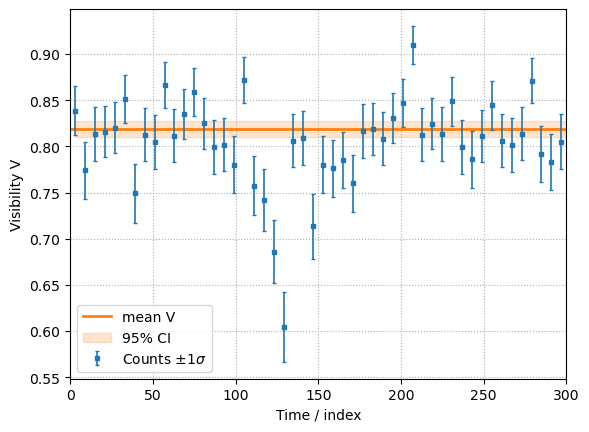

In [206]:
import numpy as np
import matplotlib.pyplot as plt

t = ts11rv
V_mean = 0.8187599768571651
V_lo, V_hi = 0.8099511185906624, 0.8275688351236677
plt.axhline(V_mean, color='tab:orange', lw=2, label='mean V')
plt.fill_between(t, V_lo, V_hi, color='tab:orange', alpha=0.2, label='95% CI')
plt.errorbar(ts12rv,V12rv,yerr=V12rver,fmt='s', ms=3.5, color='tab:blue',
            ecolor='tab:blue', elinewidth=1.2, capsize=1.5,
            label='Counts $±1σ$')
plt.ylabel('Visibility V'); plt.xlabel('Time / index'); plt.legend(); plt.grid(True, ls=':')
plt.xlim(0,300)
plt.show()

(0.0, 300.0)

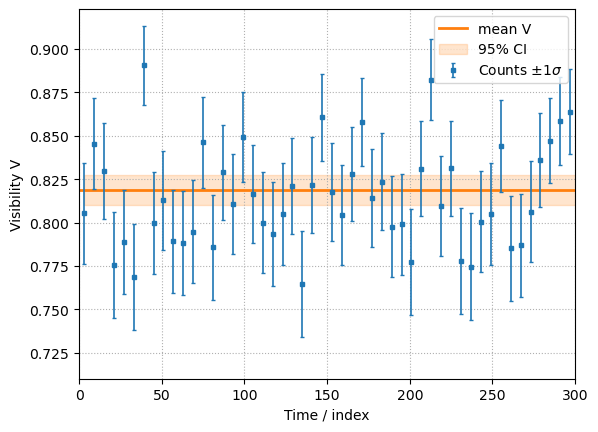

In [208]:
import numpy as np
import matplotlib.pyplot as plt

t = ts11rv
V_mean = 0.8187599768571651
V_lo, V_hi = 0.8099511185906624, 0.8275688351236677
plt.axhline(V_mean, color='tab:orange', lw=2, label='mean V')
plt.fill_between(t, V_lo, V_hi, color='tab:orange', alpha=0.2, label='95% CI')
plt.errorbar(ts11rv,V11rv,yerr=V11rver,fmt='s', ms=3.5, color='tab:blue',
            ecolor='tab:blue', elinewidth=1.2, capsize=1.5,
            label='Counts $±1σ$')
plt.ylabel('Visibility V'); plt.xlabel('Time / index'); plt.legend(); plt.grid(True, ls=':')
plt.xlim(0,300)

In [210]:
import numpy as np
from scipy import stats

def compare_voa_to_reference_mean(
    V_voa,                          # VOA visibility array
    Vref_mean, Vref_se,             # reference mean and its SE
    V_voa_err=None,                 # optional per-point 1σ for weighted mean
    alpha=0.05
):
    V = np.asarray(V_voa, float)
    m = np.isfinite(V)
    V = V[m]
    n = V.size

    # Weighted or unweighted mean for VOA
    if V_voa_err is not None:
        e = np.asarray(V_voa_err, float)[m]
        w = 1.0 / np.maximum(e, 1e-15)**2
        V_voa_mean = float(np.sum(w * V) / np.sum(w))
        V_voa_se   = float(1.0 / np.sqrt(np.sum(w)))
    else:
        V_voa_mean = float(np.mean(V))
        # robust SE allowing for unknown variance (sample std / sqrt(n))
        V_voa_se   = float(np.std(V, ddof=1) / np.sqrt(max(1, n)))

    # Difference vs reference mean (independent datasets)
    delta   = V_voa_mean - Vref_mean
    se_delta = np.sqrt(V_voa_se**2 + Vref_se**2)

    # z/t test (large n -> z). Use t with df ~ n-1 as a conservative choice.
    df = max(1, n - 1)
    tstat = delta / se_delta if se_delta > 0 else np.nan
    p = 2 * (1 - stats.t.cdf(abs(tstat), df))

    tcrit = stats.t.ppf(1 - alpha/2, df)
    ci = (delta - tcrit*se_delta, delta + tcrit*se_delta)

    # Also report QBER difference
    # q = (1 - V)/2, so Δq ≈ -(1/2)ΔV and SE_Δq ≈ (1/2)SE_ΔV
    dq   = -0.5 * delta
    se_dq = 0.5 * se_delta
    ci_q = (dq - tcrit*se_dq, dq + tcrit*se_dq)

    return {
        "n_voa": int(n),
        "V_voa_mean": V_voa_mean,
        "V_voa_se": V_voa_se,
        "V_ref_mean": float(Vref_mean),
        "V_ref_se": float(Vref_se),
        "delta_V": delta,
        "delta_V_se": se_delta,
        "delta_V_CI": ci,
        "t": tstat,
        "p_two_sided": p,
        "delta_QBER": dq,
        "delta_QBER_se": se_dq,
        "delta_QBER_CI": ci_q,
    }

In [212]:
ts12rv,V12rv,yerr=V12rver)

SyntaxError: unmatched ')' (4017210824.py, line 1)

In [214]:
compare_voa_to_reference_mean(V12rv,0.8187599768571651, 0.0026071626729632725,V_voa_err=V12rver, alpha=0.0001)

{'n_voa': 57,
 'V_voa_mean': 0.8172250020737968,
 'V_voa_se': 0.00374356073090043,
 'V_ref_mean': 0.8187599768571651,
 'V_ref_se': 0.0026071626729632725,
 'delta_V': -0.0015349747833682814,
 'delta_V_se': 0.004561967135922042,
 'delta_V_CI': (-0.020648412449736607, 0.017578462883000044),
 't': -0.3364721265266283,
 'p_two_sided': 0.7377725025724158,
 'delta_QBER': 0.0007674873916841407,
 'delta_QBER_se': 0.002280983567961021,
 'delta_QBER_CI': (-0.008789231441500022, 0.010324206224868303)}

In [216]:
import numpy as np
import matplotlib.pyplot as plt

def plot_voa_vs_ref_mean(t_voa, V_voa, Vref_mean, Vref_CI=None, V_voa_err=None, title=None):
    t_voa = np.asarray(t_voa, float)
    V_voa = np.asarray(V_voa, float)
    m = np.isfinite(t_voa) & np.isfinite(V_voa)
    t, V = t_voa[m], V_voa[m]

    resid = V - Vref_mean

    fig = plt.figure(figsize=(10,7))
    gs = fig.add_gridspec(2,1, height_ratios=[2,1], hspace=0.25)

    # Top: VOA visibility vs time
    ax1 = fig.add_subplot(gs[0])
    if V_voa_err is None:
        ax1.plot(t, V, '.', alpha=0.8, label='VOA visibility')
    else:
        V_voa_err = np.asarray(V_voa_err, float)[m]
        ax1.errorbar(t, V, yerr=V_voa_err, fmt='.', ms=3, capsize=2, alpha=0.8, label='VOA visibility')
    ax1.axhline(Vref_mean, color='tab:orange', lw=2, label='Reference mean')

    if Vref_CI is not None:
        lo, hi = Vref_CI
        ax1.fill_between([t.min(), t.max()], lo, hi, color='tab:orange', alpha=0.15, label='Ref CI')

    ax1.set_ylabel('Visibility V')
    ax1.grid(True, ls=':')
    ax1.legend(loc='best')
    if title: ax1.set_title(title)

    # Bottom: residuals
    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.axhline(0, color='k', lw=1)
    if Vref_CI is not None:
        lo2 = Vref_CI[0]-Vref_mean
        hi2 = Vref_CI[1]-Vref_mean
        ax2.fill_between([t.min(), t.max()], lo2, hi2, color='tab:orange', alpha=0.15, label='Ref CI')
    ax2.plot(t, resid, '.', alpha=0.8, label='Residual = VOA − ref mean')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Residual')
    ax2.grid(True, ls=':')

    # Quick stats on residuals
    mu = float(np.nanmean(resid))
    sd = float(np.nanstd(resid, ddof=1))
    ax2.text(0.01, 0.95, f"mean={mu:.4g}, sd={sd:.4g}", transform=ax2.transAxes, va='top')

    plt.show()

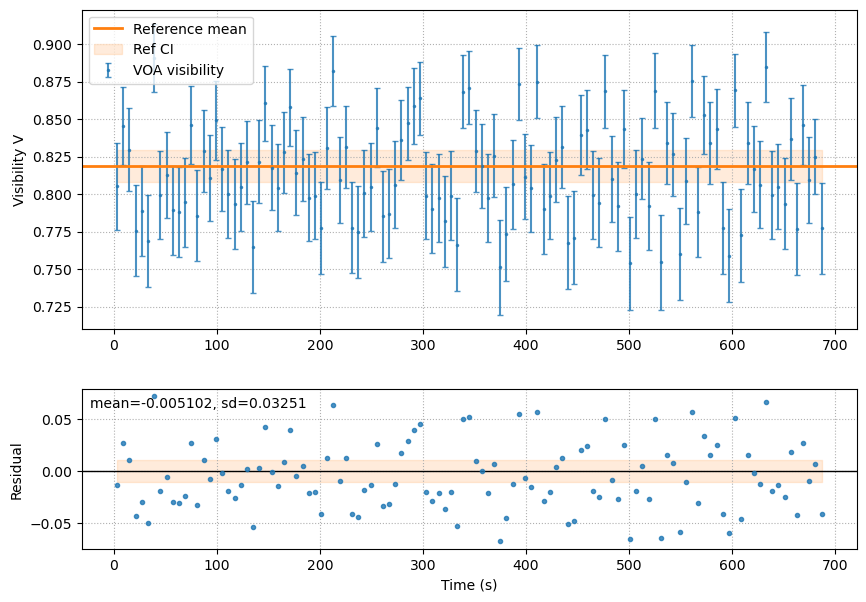

In [218]:
plot_voa_vs_ref_mean(ts11rv, V11rv, 0.8187599768571651, Vref_CI=(0.8082426565483789, 0.8292772971659512), V_voa_err=V11rver, title=None)

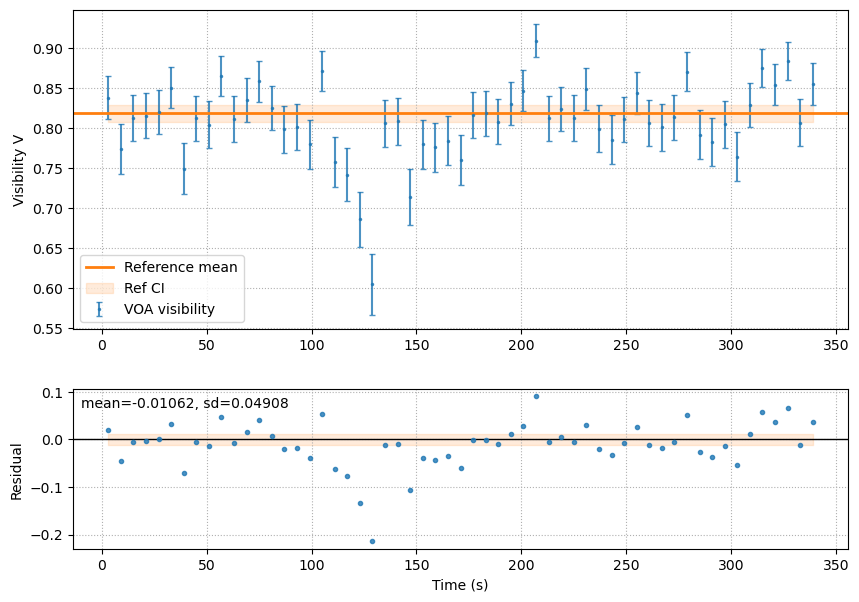

In [220]:
plot_voa_vs_ref_mean(ts12rv, V12rv, 0.8187599768571651, Vref_CI=(0.8082426565483789, 0.8292772971659512), V_voa_err=V12rver, title=None)

In [222]:
import numpy as np
import matplotlib.pyplot as plt

def plot_ref_band_vs_voa_errbars_with_side_hist(
    t_ref, V_ref, V_ref_err,
    t_voa, V_voa, V_voa_err,
    bins=25, density=True, title=None,
    time_range=(0.0, 350.0)   # <-- keep only this window
):
    t_ref = np.asarray(t_ref, float); V_ref = np.asarray(V_ref, float); V_ref_err = np.asarray(V_ref_err, float)
    t_voa = np.asarray(t_voa, float); V_voa = np.asarray(V_voa, float); V_voa_err = np.asarray(V_voa_err, float)

    # finite masks
    mref = np.isfinite(t_ref) & np.isfinite(V_ref) & np.isfinite(V_ref_err)
    mvoa = np.isfinite(t_voa) & np.isfinite(V_voa) & np.isfinite(V_voa_err)
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=18)
    plt.rc('axes', labelsize=16)
    # time-window masks
    if time_range is not None:
        tmin, tmax = time_range
        mref &= (t_ref >= tmin) & (t_ref <= tmax)
        mvoa &= (t_voa >= tmin) & (t_voa <= tmax)

    t_ref, V_ref, V_ref_err = t_ref[mref], V_ref[mref], V_ref_err[mref]
    t_voa, V_voa, V_voa_err = t_voa[mvoa], V_voa[mvoa], V_voa_err[mvoa]

    # shared bins
    if np.isscalar(bins):
        v_all = np.concatenate([V_ref, V_voa]) if V_ref.size and V_voa.size else (V_ref if V_ref.size else V_voa)
        vmin, vmax = np.nanmin(v_all), np.nanmax(v_all)
        pad = 0.02 * max(1e-12, vmax - vmin)
        bins = np.linspace(vmin - pad, vmax + pad, int(bins))

    fig, (ax_ts, ax_hist) = plt.subplots(
        1, 2,
        figsize=(10, 5),
        gridspec_kw={"width_ratios": [4.0, 1.0], "wspace": -0.005},
        sharey=True,
        constrained_layout=True   # <-- use this
    )
    w_ref = np.ones_like(V_ref, dtype=float) / max(1, V_ref.size)
    w_voa = np.ones_like(V_voa, dtype=float) / max(1, V_voa.size)
    # left: band + error bars
    order_ref = np.argsort(t_ref)
    tr, Vr, Er = t_ref[order_ref], V_ref[order_ref], V_ref_err[order_ref]
    ax_ts.plot(tr, Vr,marker='s',ms=2.5, lw=0, label="Reference mean")
    ax_ts.fill_between(tr, Vr - Er, Vr + Er, alpha=0.2, label="Ref ±1σ")
    ax_ts.errorbar(t_voa, V_voa, yerr=V_voa_err, fmt='o', ms=3, capsize=2, label="VOA visibility")
    ax_ts.set_xlabel("Time (s)"); ax_ts.set_ylabel("Visibility V"); ax_ts.grid(True, ls=":"); ax_ts.legend(loc="best")

    # right: sideways histogram(s)
    ax_hist.hist(V_ref, bins=bins, weights=w_ref, alpha=0.75,
                 label="Ref", orientation='horizontal', density=False)
    ax_hist.hist(V_voa, bins=bins, weights=w_voa, alpha=0.45,
                 label="VOA", orientation='horizontal', density=False)
    ax_hist.set_xlabel("Normalized Freq" if density else "Count"); ax_hist.legend(loc="best")
    #ax_hist.set_yticks([])                 # no tick locations
    ax_hist.tick_params(axis='y', length=0)  # (optional) hide tick marks
    #ax_hist.spines['left'].set_visible(False)  # (optional) hide left spine
    if title: fig.suptitle(title)
    return fig, (ax_ts, ax_hist)


(<Figure size 1000x500 with 2 Axes>,
 (<Axes: xlabel='Time (s)', ylabel='Visibility V'>,
  <Axes: xlabel='Normalized Freq'>))

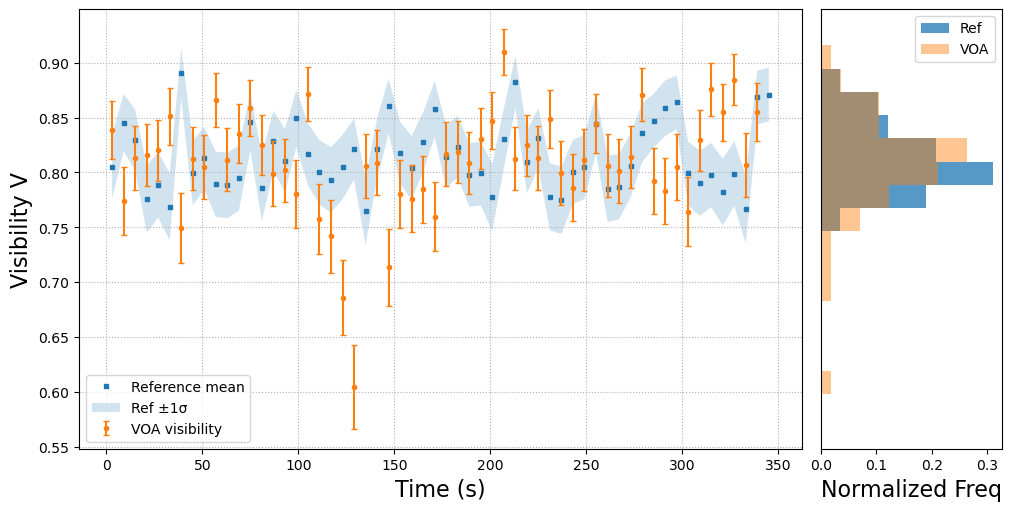

In [224]:
plot_ref_band_vs_voa_errbars_with_side_hist(ts11rv, V11rv, V11rver,ts12rv, V12rv, V12rver,
                                            bins=16, density=True, title=None,
                                           time_range=(0.0, 350.0))

In [513]:
input_vs=np.load(r'D:\PhD Thesis Writing\Data\2025-07-24\input_vs.npy')

In [515]:
input_ns=[]
for i in range(len(input_vs)):
    input_ns.append(i)

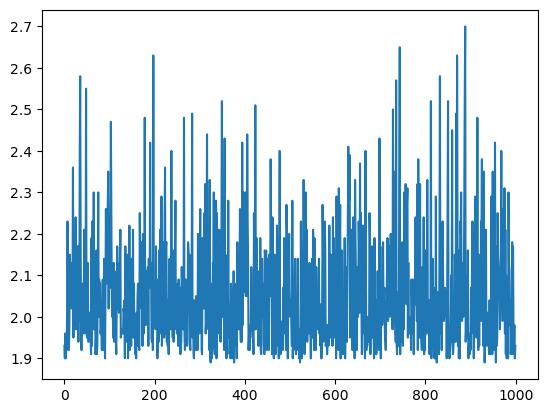

In [517]:
plt.plot(input_ns,input_vs)

In [519]:
i_new_vs=input_vs[0:350]
i_new_ns=input_ns[0:350]

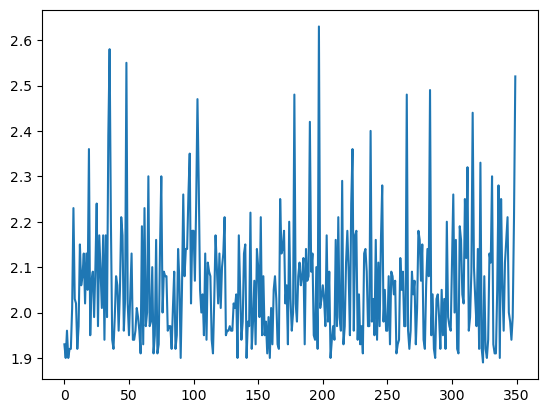

In [521]:
plt.plot(i_new_ns,i_new_vs)

In [523]:
np.mean(input_vs)

2.05841

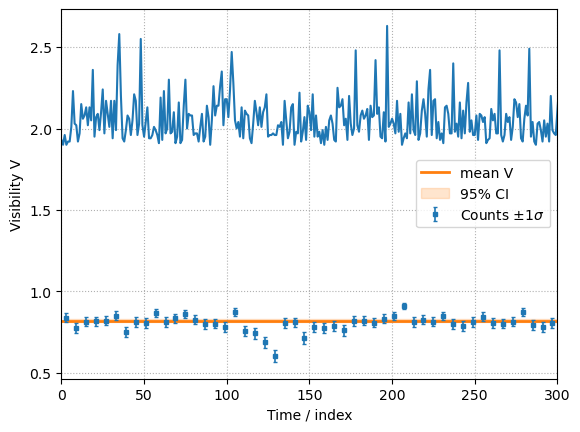

In [525]:

t = ts11rv
V_mean = 0.8187599768571651
V_lo, V_hi = 0.8099511185906624, 0.8275688351236677
plt.axhline(V_mean, color='tab:orange', lw=2, label='mean V')
plt.fill_between(t, V_lo, V_hi, color='tab:orange', alpha=0.2, label='95% CI')
plt.errorbar(ts12rv,V12rv,yerr=V12rver,fmt='s', ms=3.5, color='tab:blue',
            ecolor='tab:blue', elinewidth=1.2, capsize=1.5,
            label='Counts $±1σ$')
plt.plot(i_new_ns,i_new_vs)
plt.ylabel('Visibility V'); plt.xlabel('Time / index'); plt.legend(); plt.grid(True, ls=':')
plt.xlim(0,300)
plt.show()

In [216]:
from typing import Tuple
import numpy as np

def binned_average(
    x, 
    y, 
    n_bins: int
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Compute binned averages of y with respect to x.

    Parameters
    ----------
    x : array-like, shape (N,)
        Independent variable (used for binning).
    y : array-like, shape (N,)
        Dependent variable whose average per bin is returned.
    n_bins : int
        Number of equally-spaced bins between min(x) and max(x).

    Returns
    -------
    bin_edges   : (n_bins+1,) array
        The edges of the bins [left, right].
    bin_centers : (n_bins,) array
        The centers of the bins.
    y_mean      : (n_bins,) array
        Mean of y values falling in each bin (NaN for empty bins).
    counts      : (n_bins,) array
        Number of samples falling in each bin.

    Notes
    -----
    - NaNs in x or y are ignored.
    - The bins are closed on the left and open on the right,
      except the last bin which includes its right edge.
    """
    x = np.asarray(x)
    y = np.asarray(y)

    if x.shape != y.shape:
        raise ValueError("x and y must have the same shape.")
    if n_bins <= 0 or int(n_bins) != n_bins:
        raise ValueError("n_bins must be a positive integer.")

    # Drop NaNs
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if x.size == 0:
        raise ValueError("No finite data left after removing NaNs.")

    # Bin edges and centers
    x_min, x_max = np.min(x), np.max(x)
    if x_min == x_max:
        # All x are identical; put everything in one bin
        n_bins = 1
    edges = np.linspace(x_min, x_max, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    # Assign samples to bins
    # digitize: bins are (edges[i-1], edges[i]] if right=True
    # We want [left, right) except include the very last right edge too.
    idx = np.digitize(x, edges, right=False) - 1  # now nominally [0, n_bins]
    idx = np.clip(idx, 0, n_bins - 1)

    # Use bincount to get sums and counts per bin
    counts = np.bincount(idx, minlength=n_bins)
    sums = np.bincount(idx, weights=y, minlength=n_bins)

    # Avoid division by zero for empty bins
    with np.errstate(invalid="ignore", divide="ignore"):
        means = sums / counts
    means[counts == 0] = np.nan

    return edges, centers, means, counts

In [529]:
edges, centers, y_mean, counts = binned_average(i_new_ns, i_new_vs, n_bins=40)

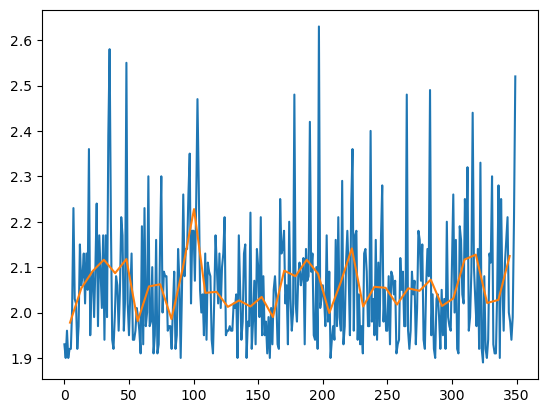

In [531]:
plt.plot(i_new_ns,i_new_vs)
plt.plot(centers,y_mean)

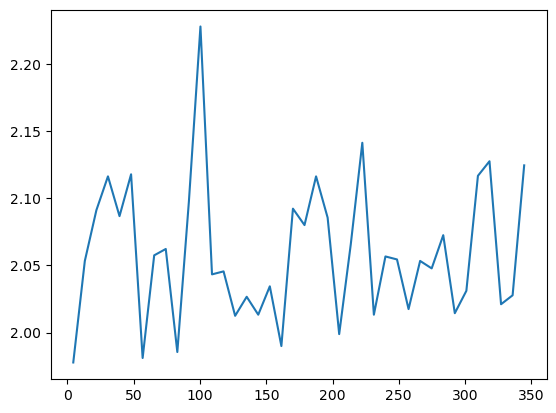

In [533]:
plt.plot(centers,y_mean)

In [535]:
y_mean_diff=np.sqrt((y_mean-np.mean(input_vs))**2)

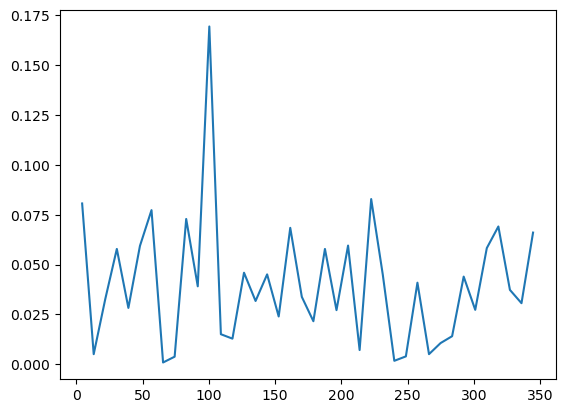

In [537]:
plt.plot(centers,y_mean_diff)

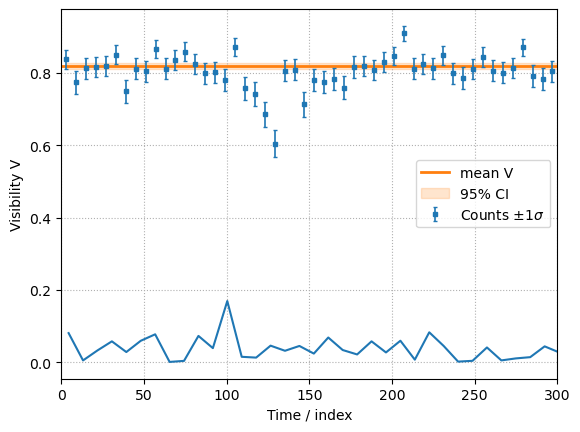

In [539]:
t = ts11rv
V_mean = 0.8187599768571651
V_lo, V_hi = 0.8099511185906624, 0.8275688351236677
plt.axhline(V_mean, color='tab:orange', lw=2, label='mean V')
plt.fill_between(t, V_lo, V_hi, color='tab:orange', alpha=0.2, label='95% CI')
plt.errorbar(ts12rv,V12rv,yerr=V12rver,fmt='s', ms=3.5, color='tab:blue',
            ecolor='tab:blue', elinewidth=1.2, capsize=1.5,
            label='Counts $±1σ$')
plt.plot(centers,y_mean_diff)
plt.ylabel('Visibility V'); plt.xlabel('Time / index'); plt.legend(); plt.grid(True, ls=':')
plt.xlim(0,300)
plt.show()

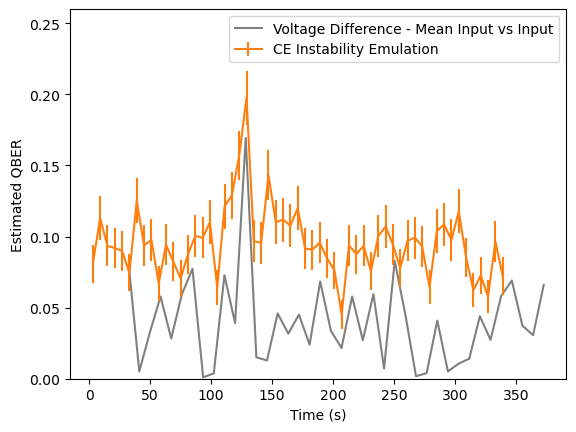

In [561]:
plt.plot(centers+28,y_mean_diff, color='gray', label='Voltage Difference - Mean Input vs Input')
plt.errorbar(ts12rv,QBER12rv,yerr=0.5*V12rver, color='tab:orange', label='CE Instability Emulation')
plt.xlabel('Time (s)')
plt.ylabel('Estimated QBER')
plt.ylim(0,0.26)
plt.legend()

In [350]:
from typing import Literal, Tuple
import numpy as np
from scipy.ndimage import uniform_filter1d

def moving_average_scipy(
    x,
    y,
    window: int,
    align: Literal["center", "left", "right"] = "center",
    min_count: int = 1,
    mode: str = "constant",
    cval: float = 0.0,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Moving (rolling) average using SciPy's uniform_filter1d (boxcar).

    Parameters
    ----------
    x : array-like, shape (N,)
        Sample positions (returned as-is).
    y : array-like, shape (N,)
        Values to average.
    window : int
        Number of points in the moving window (>=1).
    align : {'center','left','right'}, default 'center'
        Alignment of the reported average relative to the window.
        - 'center': symmetric window around each index.
        - 'left'  : trailing window ending at each index.
        - 'right' : leading window starting at each index.
    min_count : int, default 1
        Minimum number of finite points required to return a value.
    mode : str, default 'constant'
        Boundary handling for uniform_filter1d (e.g., 'nearest', 'reflect').
    cval : float, default 0.0
        Constant value used when mode='constant'.

    Returns
    -------
    x_out : ndarray, shape (N,)
    y_ma  : ndarray, shape (N,)
        Moving average with NaN where insufficient data exist.

    Notes
    -----
    - NaNs in y are ignored per-window using a finite-data mask.
    - `mode` controls how edges are handled; with 'constant' and cval=0,
      edges naturally have smaller effective counts.
    """
    x = np.asarray(x)
    y = np.asarray(y)

    if x.shape != y.shape:
        raise ValueError("x and y must have the same shape.")
    if window < 1 or int(window) != window:
        raise ValueError("window must be a positive integer.")
    if window > y.size:
        raise ValueError("window cannot exceed the length of the data.")
    if not (1 <= min_count <= window):
        raise ValueError("min_count must be between 1 and window inclusive.")

    # Masked averaging: sum and count separately, then divide
    finite = np.isfinite(y)
    y_safe = np.where(finite, y, 0.0).astype(float)

    sums = uniform_filter1d(y_safe, size=window, mode=mode, cval=cval)
    counts = uniform_filter1d(finite.astype(float), size=window, mode=mode, cval=0.0)

    with np.errstate(invalid="ignore", divide="ignore"):
        y_ma = sums / counts
    y_ma[counts < min_count] = np.nan

    # Align output by rolling the centered result
    if align == "center":
        shift = 0
    elif align == "left":   # trailing window ending at i => center shifted backward
        shift = -((window - 1) // 2)
    elif align == "right":  # leading window starting at i => center shifted forward
        shift = +((window - 1) // 2)
    else:
        raise ValueError("align must be 'center', 'left', or 'right'.")

    if shift:
        y_ma = np.roll(y_ma, shift)

        # After rolling, pad positions that no longer have full window support
        # (to avoid accidental wrap-around contributions)
        pad = abs(shift)
        if align == "left":
            y_ma[-pad:] = np.nan
        elif align == "right":
            y_ma[:pad] = np.nan

    return x.copy(), y_ma


In [438]:
x_c, y_c = moving_average_scipy(i_new_ns, i_new_vs, window=15, align="center")

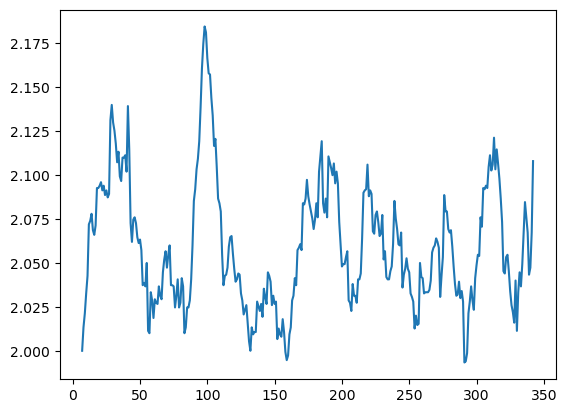

In [440]:
plt.plot(x_c, y_c)

In [442]:
y_c_mean_diff=np.sqrt((y_c-np.mean(input_vs))**2)

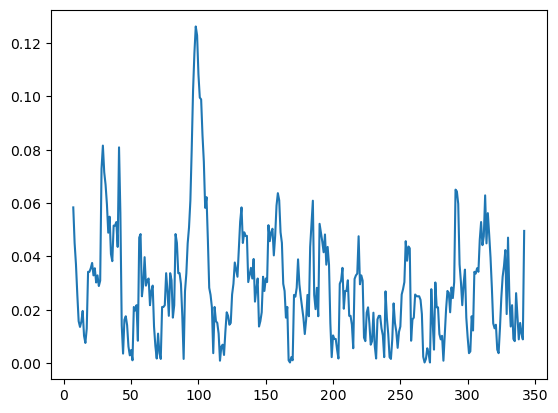

In [446]:
plt.plot(x_c, y_c_mean_diff)

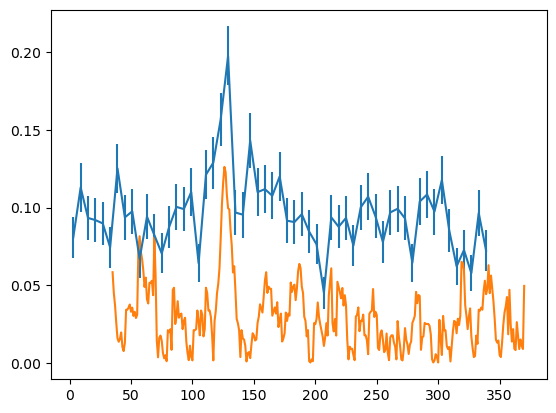

In [448]:
plt.errorbar(ts12rv,QBER12rv,yerr=0.5*V12rver)
plt.plot(x_c+28,y_c_mean_diff)

In [355]:
import numpy as np
ts11rv=np.load('ts11rv.npy')
V11rv=np.load('V11rv.npy')
V11rver=np.load('V11rver.npy')
ts12rv=np.load('ts12rv.npy')
V12rv=np.load('V12rv.npy')
V12rver=np.load('V112ver.npy')
ts13rv=np.load('ts13rv.npy')
V13rv=np.load('V13rv.npy')
V13rver=np.load('V13rver.npy')

In [359]:
QBER11rv=(1-V11rv)/2
QBER12rv=(1-V12rv)/2
QBER13rv=(1-V13rv)/2

In [361]:
QBER11rver=0.5*V11rver
QBER12rver=0.5*V12rver
QBER13rver=0.5*V13rver

In [7]:
from matplotlib import pyplot as plt

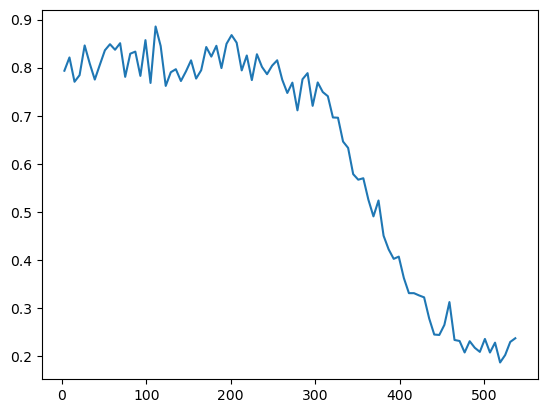

In [9]:
plt.plot(ts13rv,V13rv)

In [129]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def plot_qber_detection(
    t_ref, q_ref, e_ref,              # balanced (reference) run
    t_voa, q_voa, e_voa,              # ramped VOA run
    delta=0.01,                       # practical margin in absolute QBER (e.g., 1%)
    cl=0.99,                          # confidence level for detection & baseline band
    consecutive=2,                    # K consecutive bins to confirm detection
    # --- plateau detection (where QBER stops changing) ---
    plateau_bins=5,                   # points per slope window
    plateau_cl=0.95,                  # 2-sided CL for "slope ~ 0" test
    slope_abs_min=0.0,                # practical |slope| threshold in QBER per second
    search_plateau_after_detect=True, # only search after detection
    #
    time_label="Time (s)",
    title="QBER vs time: detection and plateau",
    show_ci_band=True,
    return_info=False
):
    """
    Plot VOA QBER vs time against a balanced baseline and mark:
      (1) detection time (QBER rises above baseline+delta at CL=cl)
      (2) plateau time (QBER slope ~ 0 within a sliding window)
    """

    # --- sanitize inputs
    t_ref = np.asarray(t_ref, float); q_ref = np.asarray(q_ref, float); e_ref = np.asarray(e_ref, float)
    t_voa = np.asarray(t_voa, float); q_voa = np.asarray(q_voa, float); e_voa = np.asarray(e_voa, float)

    mref = np.isfinite(t_ref) & np.isfinite(q_ref) & np.isfinite(e_ref)
    mvoa = np.isfinite(t_voa) & np.isfinite(q_voa) & np.isfinite(e_voa)

    t_ref, q_ref, e_ref = t_ref[mref], q_ref[mref], e_ref[mref]
    t_voa, q_voa, e_voa = t_voa[mvoa], q_voa[mvoa], e_voa[mvoa]

    if q_ref.size == 0 or q_voa.size == 0:
        raise ValueError("Empty input after filtering NaNs.")

    # --- weighted baseline mean and SE
    w_ref = 1.0 / np.maximum(e_ref, 1e-15)**2
    q0 = float(np.sum(w_ref * q_ref) / np.sum(w_ref))
    SE0 = float(1.0 / np.sqrt(np.sum(w_ref)))

    # --- thresholds
    alpha = 1.0 - cl
    zcrit_one_sided = stats.norm.ppf(1.0 - alpha)          # detection
    zcrit_two_sided = stats.norm.ppf(1.0 - alpha/2.0)      # band

    # --- per-bin combined SE for VOA vs baseline
    SE_delta = np.sqrt(SE0**2 + e_voa**2)
    z = (q_voa - (q0 + delta)) / np.maximum(SE_delta, 1e-15)

    # --- detection with K consecutive passes
    passes = z >= zcrit_one_sided
    first_idx = -1
    if consecutive <= 1:
        first_idx = int(np.argmax(passes)) if np.any(passes) else -1
    else:
        if np.any(passes):
            K = int(consecutive)
            run = np.convolve(passes.astype(int), np.ones(K, dtype=int), mode='valid')
            hit = np.where(run >= K)[0]
            if hit.size:
                first_idx = int(hit[0])  # index of first bin in the first K-run

    t_detect, t_bracket = None, None
    if first_idx >= 0:
        k0 = first_idx
        k1 = first_idx + max(1, consecutive) - 1
        t_detect = float(t_voa[k0])
        t_left = float(t_voa[max(0, k0-1)]) if k0 > 0 else float(t_voa[k0])
        t_right = float(t_voa[min(q_voa.size-1, k1)])
        t_bracket = (t_left, t_right)

    # --- plateau detection: rolling weighted slope test (2-sided)
    plateau_idx = -1
    if q_voa.size >= plateau_bins and plateau_bins >= 3:
        start_i = (first_idx if (search_plateau_after_detect and first_idx >= 0) else 0)
        for i in range(start_i, q_voa.size - plateau_bins + 1):
            sl = slice(i, i + plateau_bins)
            t_win = t_voa[sl]
            q_win = q_voa[sl]
            e_win = e_voa[sl]
            w = 1.0 / np.maximum(e_win, 1e-15)**2

            # Weighted least squares slope & SE
            X = np.vstack([t_win, np.ones_like(t_win)]).T
            Wsqrt = np.sqrt(w)
            Xw = X * Wsqrt[:, None]
            yw = q_win * Wsqrt
            beta, *_ = np.linalg.lstsq(Xw, yw, rcond=None)
            slope, intercept = beta
            resid = q_win - (slope * t_win + intercept)
            dof = max(1, plateau_bins - 2)
            sigma2 = (w * resid**2).sum() / dof
            cov = sigma2 * np.linalg.inv(Xw.T @ Xw)
            se_slope = np.sqrt(cov[0, 0])

            # two-sided test for slope ~ 0 (plateau)
            tcrit = stats.t.ppf(1.0 - (1.0 - plateau_cl)/2.0, dof)
            tstat = slope / np.maximum(se_slope, 1e-15)
            cond_stat = np.abs(tstat) <= tcrit
            cond_mag  = (np.abs(slope) <= slope_abs_min) if slope_abs_min > 0 else True

            if cond_stat and cond_mag:
                plateau_idx = i  # plateau begins at the start of this window
                break

    t_plateau = float(t_voa[plateau_idx]) if plateau_idx >= 0 else None

    # --- PLOTTING ------------------------------------------------------------
    fig = plt.figure(figsize=(11, 6), constrained_layout=True)
    gs = fig.add_gridspec(2, 1, height_ratios=[2.0, 1.0], hspace=0.25)

    # (A) top axis: QBER vs time with baseline band and delta line
    ax = fig.add_subplot(gs[0, 0])

    oref = np.argsort(t_ref)
    ormp = np.argsort(t_voa)

    if show_ci_band:
        ax.axhspan(q0 - zcrit_two_sided*SE0, q0 + zcrit_two_sided*SE0,
                   color='tab:blue', alpha=0.12, label=f"Baseline ±{int(cl*100)}% CI")

    ax.axhline(q0, color='tab:blue', lw=2, label="Baseline mean")
    ax.axhline(q0 + delta, color='tab:red', lw=1.5, ls='--', label=f"δ = {delta:.3g}")

    ax.errorbar(t_voa[ormp], q_voa[ormp], yerr=e_voa[ormp],
                fmt='o', ms=4, capsize=2, color='tab:orange', label='VOA QBER')

    # detection marker
    if t_detect is not None:
        ax.axvline(t_detect, color='tab:green', lw=2, ls='-', label=f"Detect @ {t_detect:.2f}s")
        if t_bracket is not None:
            ax.axvspan(t_bracket[0], t_bracket[1], color='tab:green', alpha=0.10)

        j = first_idx
        dq = q_voa[j] - q0
        ax.annotate(
            f"t* = {t_detect:.2f}s\nΔQBER = {dq:+.3f}\nZ = {z[j]:.2f} (≥ {zcrit_one_sided:.2f})",
            xy=(t_detect, q_voa[j]),
            xytext=(10, 20), textcoords='offset points',
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="tab:green", alpha=0.9),
            arrowprops=dict(arrowstyle="->", color="tab:green", lw=1.5),
            ha='left', va='bottom'
        )

    # plateau marker
    if t_plateau is not None:
        ax.axvline(t_plateau, color='tab:purple', lw=2, ls='--', label=f"Plateau @ {t_plateau:.2f}s")
        # Optional annotation: report local slope ± SE
        sl = slice(plateau_idx, plateau_idx + plateau_bins)
        t_win = t_voa[sl]; q_win = q_voa[sl]; e_win = e_voa[sl]
        w = 1.0 / np.maximum(e_win, 1e-15)**2
        X = np.vstack([t_win, np.ones_like(t_win)]).T
        Wsqrt = np.sqrt(w); Xw = X * Wsqrt[:, None]; yw = q_win * Wsqrt
        slope, intercept = np.linalg.lstsq(Xw, yw, rcond=None)[0]
        resid = q_win - (slope*t_win + intercept)
        dof = max(1, plateau_bins - 2)
        sigma2 = (w * resid**2).sum() / dof
        cov = sigma2 * np.linalg.inv(Xw.T @ Xw)
        se_slope = np.sqrt(cov[0,0])
        ax.annotate(
            f"Plateau start\nslope={slope:+.3g} ± {se_slope:.3g} (/s)\nCL={int(plateau_cl*100)}%",
            xy=(t_plateau, np.interp(t_plateau, t_voa[ormp], q_voa[ormp])),
            xytext=(10, -40), textcoords='offset points',
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="tab:purple", alpha=0.9),
            arrowprops=dict(arrowstyle="->", color="tab:purple", lw=1.5),
            ha='left', va='top'
        )

    ax.set_xlabel(time_label)
    ax.set_ylabel("QBER")
    ax.grid(True, ls=":")
    ax.legend(loc="best")
    ax.set_title(title)

    # (B) bottom axis: detection statistic (z) vs time
    ax2 = fig.add_subplot(gs[1, 0], sharex=ax)
    ax2.axhline(0.0, color='k', lw=1)
    ax2.axhline(zcrit_one_sided, color='tab:red', lw=1.5, ls='--',
                label=f"One-sided z crit ({int(cl*100)}% CL)")
    ax2.plot(t_voa[ormp], z[ormp], marker='o', ms=3, lw=1.0, color='tab:purple')
    if t_detect is not None:
        ax2.axvline(t_detect, color='tab:green', lw=2)
    if t_plateau is not None:
        ax2.axvline(t_plateau, color='tab:purple', lw=2, ls='--')

    ax2.set_xlabel(time_label)
    ax2.set_ylabel("Detection statistic  z")
    ax2.grid(True, ls=":")
    ax2.legend(loc="best")

    info = {
        "q0": q0, "SE0": SE0,
        "alpha": alpha, "zcrit_one_sided": float(zcrit_one_sided),
        "zcrit_two_sided": float(zcrit_two_sided),
        "delta": delta, "consecutive": int(consecutive),
        "t_detect": t_detect, "t_bracket": t_bracket, "first_index": first_idx,
        "plateau_idx": plateau_idx, "t_plateau": t_plateau,
        "plateau_bins": int(plateau_bins), "plateau_cl": plateau_cl,
        "slope_abs_min": slope_abs_min,
        "z_series": z, "SE_delta": SE_delta
    }
    return (fig, (ax, ax2), info) if return_info else (fig, (ax, ax2))


In [279]:
psnew2=[]
psnew=((ps/np.max(ps))*0.40)
for i in range(len(psnew)):
    psnew2.append((np.max(psnew)-psnew[i])/np.max(psnew))
psnew2=np.array(psnew2)

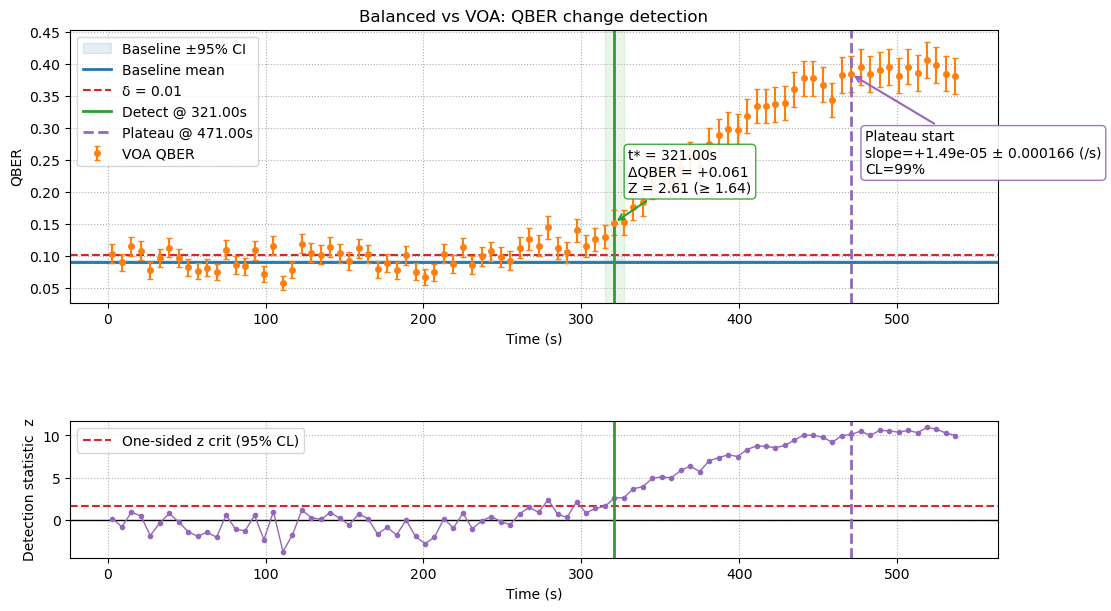

In [395]:
fig, (ax_top, ax_bottom), info  = plot_qber_detection(
    ts11rv, QBER11rv, QBER11rver,
    ts13rv, QBER13rv, QBER13rver,
    delta=0.01, cl=0.95, consecutive=2,
    title="Balanced vs VOA: QBER change detection",
    return_info=True,
    plateau_bins=8,
    plateau_cl=0.9999,
    slope_abs_min=2e-5
)
# (Optional) tweak axes before showing
#ax_top.set_xlim(0, 350)
#ax_bottom.set_xlim(0, 350)

# Show / save
import matplotlib.pyplot as plt
#psnew=((ps/np.max(ps))*0.4)
#vsnew=((vs*100)*1.00749)+34
#ax_top.plot(vsnew,psnew)
#ax_top.legend(loc='upper left')
#plt.show()

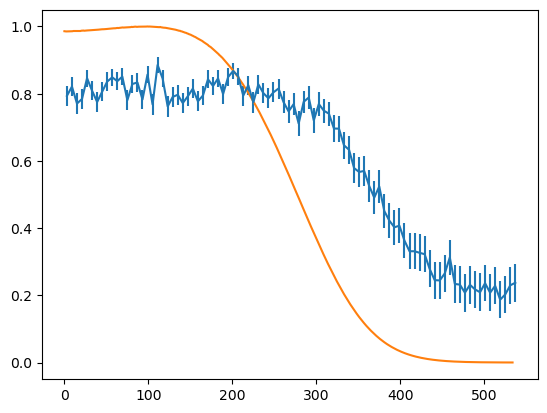

In [269]:
psnew=((ps/np.max(ps)))
vsnew=(vs*100)*1.06749
plt.errorbar(ts13rv,V13rv,yerr=V13rver)
plt.plot(vsnew,psnew)

In [225]:
ts13rv

array([  3.,   9.,  15.,  21.,  27.,  33.,  39.,  45.,  51.,  57.,  63.,
        69.,  75.,  81.,  87.,  93.,  99., 105., 111., 117., 123., 129.,
       135., 141., 147., 153., 159., 165., 171., 177., 183., 189., 195.,
       201., 207., 213., 219., 225., 231., 237., 243., 249., 255., 261.,
       267., 273., 279., 285., 291., 297., 303., 309., 315., 321., 327.,
       333., 339., 345., 351., 357., 363., 369., 375., 381., 387., 393.,
       399., 405., 411., 417., 423., 429., 435., 441., 447., 453., 459.,
       465., 471., 477., 483., 489., 495., 501., 507., 513., 519., 525.,
       531., 537.])

In [195]:
# (Optional) tweak axes before showing
axes[0].set_xlim(0, 350)
axes[1].set_xlim(0, 350)

# Show / save
import matplotlib.pyplot as plt
plt.show()      

In [193]:
plt.show()

In [21]:
meas = import_all_measurements(r'D:\PhD Thesis Writing\Data\2025-07-23')
# meas is a list of dicts, already time-ordered:
# [{'name': 'm1_', 'ts': array([...]), 'ns': array([...]), 'xs': array([...])}, ...]
# Access first measurement:
first = meas[0]
name, ts, ns, xs = first["name"], first["ts"], first["ns"], first["xs"]

# If you prefer a numpy array of entries:
meas_arr = import_all_measurements_as_array(r'D:\PhD Thesis Writing\Data\2025-07-23')
# Each meas_arr[i] is: (name, ts, ns, xs)


In [31]:
meas_arr[22][3]

array([ 82.,  96., 101., ...,  92.,  92.,  92.])

In [37]:
meas_arr[22][1][0]

'16:49:53:998392'

In [39]:
meas_arr[22][1][1]

'16:49:54:000386'

In [41]:
54.000386-53.998392

0.0019939999999962765

In [43]:
1/0.0019939999999962765


501.50451354155837

In [311]:
eg_ts=meas_arr2[13][2]/500
eg_cs=meas_arr2[13][3]

In [323]:
len(eg_ts[20000:278650])

258650

Text(0, 0.5, 'Counts (per 1/500 s)')

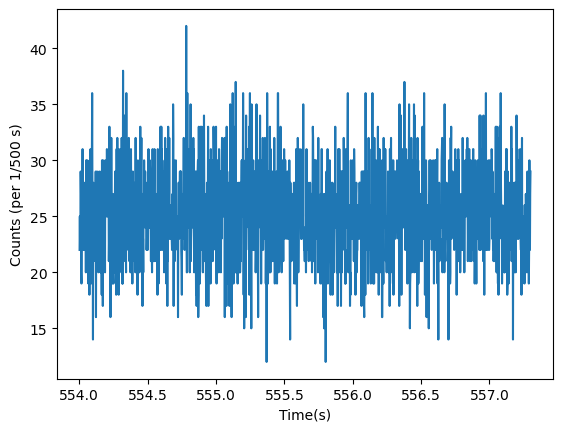

In [347]:
plt.plot(eg_ts[277000:278650],eg_cs[277000:278650])
plt.xlabel('Time(s)')
plt.ylabel('Counts (per 1/500 s)')

Text(0, 0.5, 'Counts (per 1/500 s)')

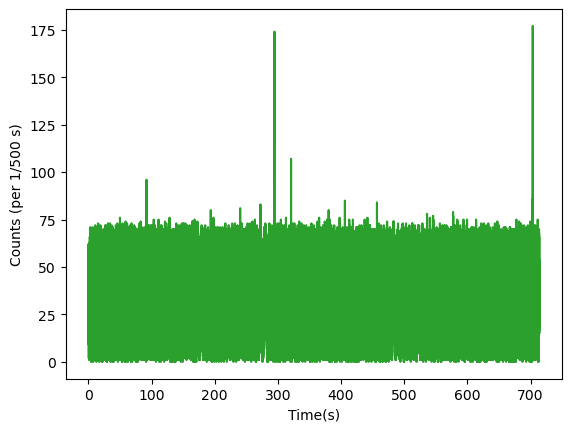

In [365]:
plt.plot(meas_arr2[11][2]/500,meas_arr2[11][3], color='tab:green')
plt.xlabel('Time(s)')
plt.ylabel('Counts (per 1/500 s)')

In [47]:
np.max(meas_arr[22][2]/500)

579.234

In [49]:
np.max(ts13rv)

537.0

In [51]:
# Each meas_arr[i] is (name, ts, ns, xs)
for i, rec in enumerate(meas_arr):
    name = rec[0]
    print(i, name)

# List of (index, name):
indexed_names = [(i, rec[0]) for i, rec in enumerate(meas_arr)]

0 test2
1 test3
2 test4
3 test5
4 test6
5 measurement_23_07_25_test
6 measurement_23_07_25_test2
7 measurement_23_07_25_test3
8 measurement_23_07_25_test4
9 measurement_23_07_25_test5_nolight
10 measurement_23_07_25_test6
11 measurement_23_07_25_test7
12 measurement_23_07_25_test8
13 measurement_23_07_25_test9
14 measurement1
15 measurement2
16 measurement3_varying
17 measurement_23_07_25_test10
18 measurement_23_07_25_test11
19 measurement_23_07_25_varying1
20 measurement4_ramp
21 measurement_23_07_25_constant1
22 measurement_23_07_25_ramp1


In [53]:
meas_arr[20][1][0]

'16:29:49:261183'

In [55]:
meas_arr[20][1][1]

'16:29:49:263178'

In [59]:
1/(0.263178-0.261183)

501.253132832074

In [61]:
np.max(meas_arr[20][2]/500)

568.48

In [63]:
meas_arr2 = import_all_measurements_as_array(r'D:\PhD Thesis Writing\Data\2025-07-24')


In [65]:
meas_arr2[13][1]

array(['15:44:09:350525', '15:44:09:352519', '15:44:09:354514', ...,
       '15:53:10:439550', '15:53:10:441736', '15:53:10:443723'],
      dtype='<U15')

In [67]:
# Each meas_arr[i] is (name, ts, ns, xs)
for i, rec in enumerate(meas_arr2):
    name = rec[0]
    print(i, name)

# List of (index, name):
indexed_names = [(i, rec[0]) for i, rec in enumerate(meas_arr2)]

0 measurement_24_07_25_ramp1
1 measurement_24_07_25_ramptest
2 measurement_24_07_25_ramp2
3 measurement_24_07_25_balanced1
4 measurement_24_07_25_balanced2_lv
5 measurement_24_07_25_fan_lv
6 measurement_24_07_25_fan2_lv
7 measurement_24_07_25_fan3_lv
8 measurement_24_07_25_fan4_lv
9 measurement_24_07_25_1km_balanced_lv
10 measurement_24_07_25_1km_balanced1_lv
11 measurement_24_07_25_1km_balanced2_lv
12 measurement_24_07_25_1km_random1_lv
13 measurement_24_07_25_1km_ramp1_lv


In [109]:
meas_arr2[2][1]

array(['12:56:43:213107', '12:56:43:215101', '12:56:43:217096', ...,
       '13:09:08:214431', '13:09:08:216826', '13:09:08:218824'],
      dtype='<U15')

In [93]:
np.max(meas_arr2[0][2]/500)

336.162

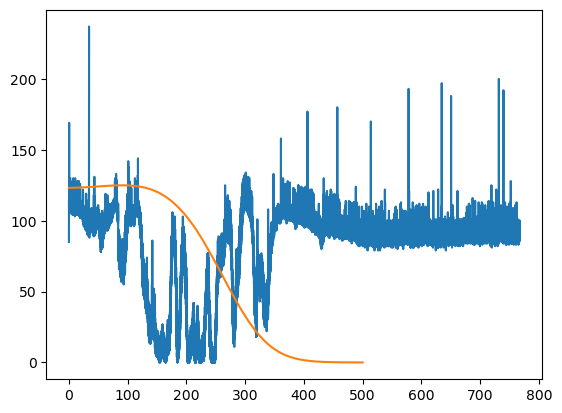

In [103]:
plt.plot(meas_arr2[2][2]/500,meas_arr2[2][3])
psnew=((ps/np.max(ps))*125)
vsnew=(vs*100)
plt.plot(vsnew,psnew)

In [289]:
ps=np.load(r'D:\PhD Thesis Writing\Data\2025-06-04\psfixed.npy')
vs=np.load(r'D:\PhD Thesis Writing\Data\2025-06-04\vsfixed.npy')

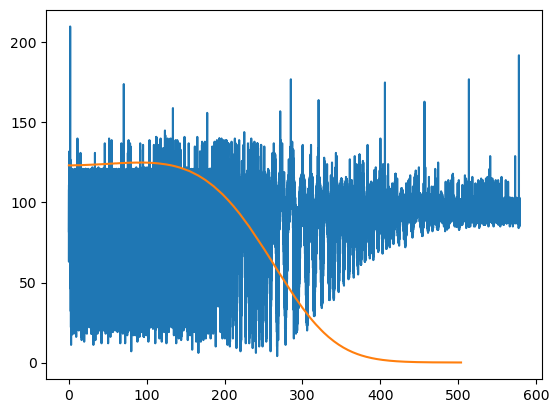

In [253]:
plt.plot(meas_arr[22][2]/500,meas_arr[22][3])
psnew=((ps/np.max(ps))*125)
vsnew=(vs*100)*1.00749
plt.plot(vsnew,psnew)

In [233]:
import time
from datetime import datetime

In [235]:
vs=[]
counter=0.0
for i in range(501):
    vs.append(counter)
    counter=counter+0.01
    counter=round(counter, 2)

In [237]:
ps2=[]
for i in range(501):
    time.sleep(1)
    reading=datetime.now().strftime("%H:%M:%S:%f")
    print(reading)
    ps2.append(reading)

02:10:00:929446
02:10:01:936011
02:10:02:943195
02:10:03:950427
02:10:04:957601
02:10:05:965346
02:10:06:972837
02:10:07:980733
02:10:08:988571
02:10:09:996314
02:10:11:003867
02:10:12:011267
02:10:13:018275
02:10:14:025089
02:10:15:032584
02:10:16:039970
02:10:17:047788
02:10:18:055297
02:10:19:062573
02:10:20:070316
02:10:21:078108
02:10:22:085720
02:10:23:093539
02:10:24:101128
02:10:25:108047
02:10:26:114550
02:10:27:122039
02:10:28:129497
02:10:29:137239
02:10:30:144980
02:10:31:152682
02:10:32:159652
02:10:33:166074
02:10:34:173298
02:10:35:180976
02:10:36:186936
02:10:37:193619
02:10:38:200683
02:10:39:208473
02:10:40:215715
02:10:41:223450
02:10:42:230942


KeyboardInterrupt: 

In [257]:
(42.230942-41.223450)*500

503.7459999999996

In [241]:
41.223450-40.215715

1.0077349999999967

In [243]:
40.215715-39.208473

1.007242000000005

In [245]:
39.208473-38.200683

1.00779

In [765]:
FSMOFF_250ks2 = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-07-21\FSMOFF\C1--fibrefs_fsmoff_250ks--00001.csv',skiprows=5, delimiter=',', usecols=1)
off250ts=np.linspace(-10,10,len(FSMOFF_250ks2))

In [799]:
FSMON_250ks = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-07-21\FSMON\C1--fibrefs_fsmon_250ks--00001.csv',skiprows=5, delimiter=',', usecols=1)
on250ts=np.linspace(-10,10,len(FSMON_250ks))

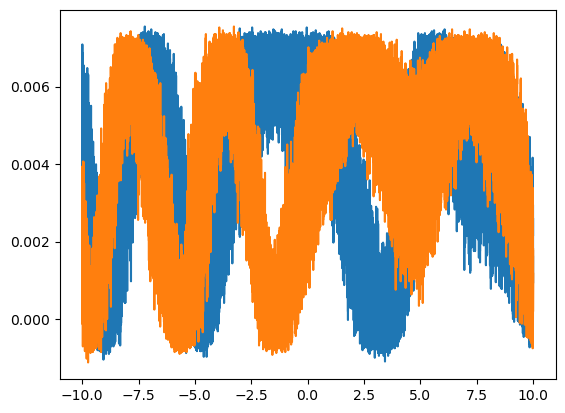

In [801]:
plt.plot(off250ts,FSMOFF_250ks2)
plt.plot(on250ts,FSMON_250ks)

In [802]:
_, centersoff, y_meanoff, _ = binned_average(off250ts, FSMOFF_250ks2, n_bins=80)

In [805]:
_, centerson, y_meanon, _ = binned_average(on250ts, FSMON_250ks, n_bins=80)

In [807]:
visoffest=(np.max(y_meanoff)-np.min(y_meanoff))/(np.max(y_meanoff)+np.min(y_meanoff))

In [809]:
visoffest

0.9195768575100205

In [811]:
visonest=(np.max(y_meanon)-np.min(y_meanon))/(np.max(y_meanon)+np.min(y_meanon))

In [813]:
visonest

0.9240535772176063

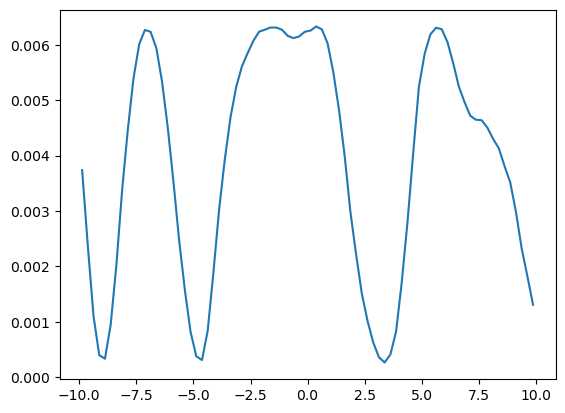

In [815]:
plt.plot(centersoff, y_meanoff)

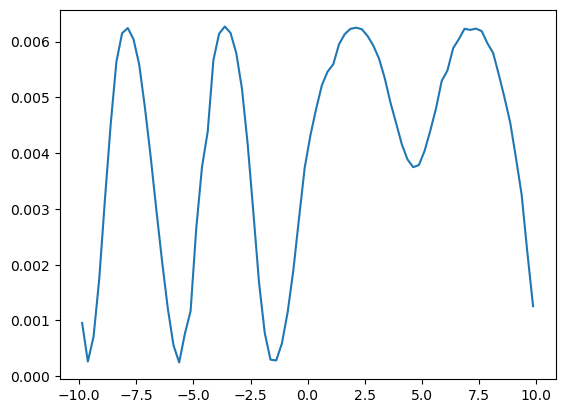

In [817]:
plt.plot(centerson, y_meanon)

In [620]:
import numpy as np
from typing import Tuple, Dict, Any, List, Optional

# ----------------- helpers -----------------

def _visibility_from_block_sums(block_sums: np.ndarray) -> float:
    if block_sums.size == 0:
        return np.nan
    Nmin = float(np.min(block_sums))
    Nmax = float(np.max(block_sums))
    den = Nmax + Nmin
    return (Nmax - Nmin) / den if den > 0 else np.nan

# ------------- main function -------------

def point_binned_visibility(
    ts,
    counts,
    n_taus: int = 40,
    tau_max: float = None,
    log_bins: bool = True,
    overlap: Optional[float] = None,   # None or fraction in [0,1)
    verbose: bool = True
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, Dict[str, Any]]:
    """
    Point-binning visibility with analytic Poisson errors and optional window overlap.

    INPUTS
    ------
    ts : array-like of float
        Timestamps in SECONDS (numeric, nondecreasing).
    counts : array-like
        Non-negative counts per sample (same length/order as ts).
    n_taus : int
        Number of τ values (i.e., K-values) to evaluate.
    tau_max : float or None
        Maximum τ (seconds). Default: half of total duration.
    log_bins : bool
        If True, K spaced logarithmically; otherwise linearly.
    overlap : None or float in [0,1)
        If None, non-overlapping windows (stride = K samples).
        Else stride S = round(K * (1 - overlap)); e.g. overlap=0.5 -> ~50% overlap.
    verbose : bool
        Print diagnostics.

    RETURNS
    -------
    taus : np.ndarray (float)
        Bin lengths (seconds), ascending (unique).
    V : np.ndarray
        Visibility at each τ, using min/max across window sums.
    QBER : np.ndarray
        QBER(τ) = (1 - |V|)/2.
    V_err : np.ndarray
        Analytic 1σ uncertainty on V: sqrt(4AB / (A+B)^3), A=Nmax, B=Nmin.
    QBER_err : np.ndarray
        Analytic 1σ uncertainty on QBER = 0.5 * V_err.
    tau_err : np.ndarray
        1σ spread of the actual window durations (std across windows) at each τ.
    diagnostics : dict
        Sample spacing summary + per-τ window stats.
    """
    # ---- prepare data
    secs = np.asarray(ts, dtype=float)
    x    = np.clip(np.nan_to_num(np.asarray(counts), nan=0.0), 0, None)
    n = min(secs.size, x.size)
    secs = secs[:n]; x = x[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    duration = float(secs[-1] - secs[0])
    if not np.isfinite(duration) or duration <= 0:
        raise ValueError("Non-positive duration or invalid timestamps.")

    dts = np.diff(secs)
    dt_pos = dts[dts > 0]
    if dt_pos.size == 0:
        raise ValueError("Timestamps are not strictly advancing (all Δt ≤ 0).")
    dt_mean = float(np.mean(dt_pos))
    dt_std  = float(np.std(dt_pos, ddof=1)) if dt_pos.size > 1 else 0.0
    dt_cv   = dt_std / dt_mean if dt_mean > 0 else np.nan

    if tau_max is None:
        tau_max = 0.5 * duration
    tau_max = max(float(tau_max), dt_mean)

    # ---- choose K values (samples per bin)
    Kmax = max(1, int(np.floor(tau_max / dt_mean)))
    if n_taus <= 1:
        Ks = np.array([1], dtype=int)
    else:
        if log_bins:
            Ks = np.round(np.logspace(0, np.log10(Kmax), num=n_taus)).astype(int)
        else:
            Ks = np.round(np.linspace(1, Kmax, num=n_taus)).astype(int)
        Ks = np.unique(np.clip(Ks, 1, Kmax))

    taus    = Ks * dt_mean
    V       = np.empty_like(taus, dtype=float)
    QBER    = np.empty_like(taus, dtype=float)
    V_err   = np.full_like(taus, np.nan, dtype=float)
    QBER_err= np.full_like(taus, np.nan, dtype=float)
    tau_err = np.full_like(taus, np.nan, dtype=float)

    # Validate overlap
    if overlap is not None and not (0.0 <= overlap < 1.0):
        raise ValueError("overlap must be in [0, 1) or None.")

    # Diagnostics per τ
    per_tau_diag: List[Dict[str, Any]] = []

    # ---- compute V(τ), analytic errors, and window-duration consistency
    for i, K in enumerate(Ks):
        # stride from overlap
        if overlap is None:
            stride = K
            overlap_eff = 0.0
        else:
            stride = max(1, int(round(K * (1.0 - overlap))))
            stride = min(stride, K)
            overlap_eff = 1.0 - (stride / float(K))

        # starting indices; drop final partial window (<K)
        if n < K:
            starts = np.array([], dtype=int)
        else:
            last_start = n - K
            starts = np.arange(0, last_start + 1, stride, dtype=int)

        n_blocks = int(starts.size)
        if n_blocks == 0:
            V[i] = np.nan
            QBER[i] = np.nan
            tau_err[i] = np.nan
            per_tau_diag.append({
                "K": int(K), "stride": int(stride), "overlap_eff": float(overlap_eff),
                "tau_target": K * dt_mean, "n_blocks": 0,
                "tau_mean": np.nan, "tau_std": np.nan, "rel_std": np.nan,
                "rmse_vs_target": np.nan, "max_abs_err": np.nan
            })
            continue

        # Efficient sliding sums via cumulative sum
        cs = np.concatenate(([0.0], np.cumsum(x, dtype=float)))
        ends = starts + K
        block_sums = cs[ends] - cs[starts]

        # Central V and QBER
        V[i] = _visibility_from_block_sums(block_sums)
        QBER[i] = 0.5 * (1.0 - np.abs(V[i])) if np.isfinite(V[i]) else np.nan

        # Analytic errors from A=Nmax, B=Nmin (Poisson)
        A = float(np.max(block_sums))
        B = float(np.min(block_sums))
        den = A + B
        if den > 0 and np.isfinite(V[i]):
            varV = 4.0 * A * B / (den ** 3)
            V_err[i] = np.sqrt(varV)
            QBER_err[i] = 0.5 * V_err[i]

        # Actual time-span of each window (first to last sample in window)
        durations = secs[ends - 1] - secs[starts]
        tau_target = K * dt_mean

        # Consistency metrics (and τ error)
        tau_mean = float(np.mean(durations)) if durations.size else np.nan
        tau_std  = float(np.std(durations, ddof=1)) if durations.size > 1 else 0.0
        tau_err[i] = tau_std
        rel_std  = (tau_std / tau_mean) if (durations.size and tau_mean > 0) else np.nan
        rmse     = float(np.sqrt(np.mean((durations - tau_target) ** 2))) if durations.size else np.nan
        max_err  = float(np.max(np.abs(durations - tau_target))) if durations.size else np.nan

        per_tau_diag.append({
            "K": int(K),
            "stride": int(stride),
            "overlap_eff": float(overlap_eff),
            "tau_target": tau_target,
            "n_blocks": n_blocks,
            "tau_mean": tau_mean,
            "tau_std": tau_std,
            "rel_std": rel_std,
            "rmse_vs_target": rmse,
            "max_abs_err": max_err,
        })

    diagnostics = {
        "sample_spacing": {
            "n_samples": int(n),
            "duration_s": duration,
            "dt_mean_s": dt_mean,
            "dt_std_s": dt_std,
            "dt_cv": dt_cv,
            "dt_min_s": float(np.min(dt_pos)),
            "dt_med_s": float(np.median(dt_pos)),
            "dt_max_s": float(np.max(dt_pos)),
            "pct_1_99_s": (float(np.percentile(dt_pos, 1)), float(np.percentile(dt_pos, 99)))
        },
        "per_tau": per_tau_diag
    }

    if verbose:
        ss = diagnostics["sample_spacing"]
        print("\n[Sample spacing diagnostics]")
        print(f"  n = {ss['n_samples']}, duration = {ss['duration_s']:.6f} s")
        print(f"  mean Δt = {ss['dt_mean_s']:.6e} s, std = {ss['dt_std_s']:.6e} s, CV = {ss['dt_cv']:.3g}")
        print(f"  min/median/max Δt = {ss['dt_min_s']:.6e} / {ss['dt_med_s']:.6e} / {ss['dt_max_s']:.6e} s")
        p1, p99 = ss["pct_1_99_s"]
        print(f"  1–99% Δt = {p1:.6e} … {p99:.6e} s")

        print("\n[Bin-size consistency per τ (point binning)]")
        print("  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)")
        for r in per_tau_diag:
            print(f"{r['K']:>3d}  {r['stride']:>6d}  {r['overlap_eff']:.2f}  {r['tau_target']:.6e}  "
                  f"{r['n_blocks']:>8d}  {r['tau_mean']:.6e}  {r['tau_std']:.6e}  "
                  f"{(r['rel_std'] if np.isfinite(r['rel_std']) else np.nan):>7.3g}  "
                  f"{r['rmse_vs_target']:.6e}  {r['max_abs_err']:.6e}")

    return taus, V, QBER, V_err, QBER_err, tau_err, diagnostics


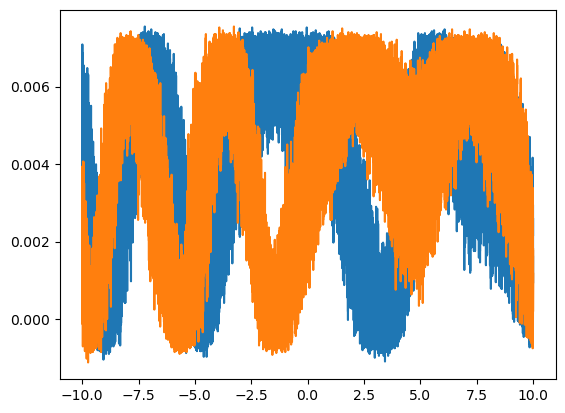

In [819]:
plt.plot(off250ts,FSMOFF_250ks2)
plt.plot(on250ts,FSMON_250ks)

In [821]:
tausoff, Voff, QBERoff , _ ,_ ,_,_ = point_binned_visibility(off250ts, FSMOFF_250ks2, n_taus=1000,tau_max=10, log_bins=True)


[Sample spacing diagnostics]
  n = 5000002, duration = 20.000000 s
  mean Δt = 3.999999e-06 s, std = 9.880666e-16 s, CV = 2.47e-10
  min/median/max Δt = 3.999999e-06 / 3.999999e-06 / 3.999999e-06 s
  1–99% Δt = 3.999999e-06 … 3.999999e-06 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  3.999999e-06   5000002  0.000000e+00  0.000000e+00      nan  3.999999e-06  3.999999e-06
  2       2  0.00  7.999998e-06   2500001  3.999999e-06  9.880671e-16  2.47e-10  3.999999e-06  3.999999e-06
  3       3  0.00  1.200000e-05   1666667  7.999998e-06  9.890297e-16  1.24e-10  3.999999e-06  3.999999e-06
  4       4  0.00  1.600000e-05   1250000  1.200000e-05  2.780366e-16  2.32e-11  3.999999e-06  3.999999e-06
  5       5  0.00  2.000000e-05   1000000  1.600000e-05  9.852760e-16  6.16e-11  3.999999e-06  3.999999e-06
  6       6  0.00  2.400000e-05    833333  2.000000e-05  9.881782e-16  4.

In [822]:
tauson, Von, QBERon ,_ ,_ ,_,_ = point_binned_visibility(on250ts, FSMON_250ks, n_taus=1000,tau_max=10, log_bins=True)


[Sample spacing diagnostics]
  n = 5000002, duration = 20.000000 s
  mean Δt = 3.999999e-06 s, std = 9.880666e-16 s, CV = 2.47e-10
  min/median/max Δt = 3.999999e-06 / 3.999999e-06 / 3.999999e-06 s
  1–99% Δt = 3.999999e-06 … 3.999999e-06 s

[Bin-size consistency per τ (point binning)]
  K  stride  overlap  τ_target(s)  n_blocks  τ_mean(s)   τ_std(s)   rel_std   RMSE(s)   max|err|(s)
  1       1  0.00  3.999999e-06   5000002  0.000000e+00  0.000000e+00      nan  3.999999e-06  3.999999e-06
  2       2  0.00  7.999998e-06   2500001  3.999999e-06  9.880671e-16  2.47e-10  3.999999e-06  3.999999e-06
  3       3  0.00  1.200000e-05   1666667  7.999998e-06  9.890297e-16  1.24e-10  3.999999e-06  3.999999e-06
  4       4  0.00  1.600000e-05   1250000  1.200000e-05  2.780366e-16  2.32e-11  3.999999e-06  3.999999e-06
  5       5  0.00  2.000000e-05   1000000  1.600000e-05  9.852760e-16  6.16e-11  3.999999e-06  3.999999e-06
  6       6  0.00  2.400000e-05    833333  2.000000e-05  9.881782e-16  4.

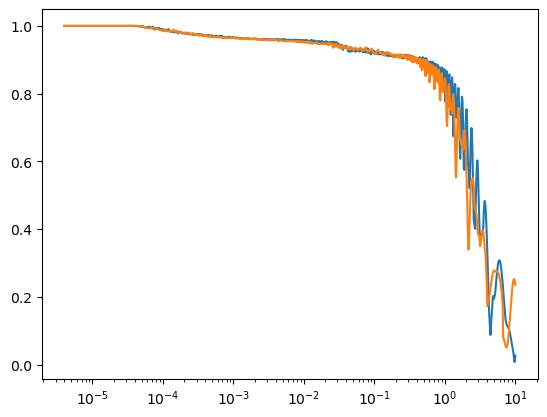

In [823]:
plt.semilogx(tausoff, Voff)
plt.semilogx(tauson, Von)

(0.9, 1.1)

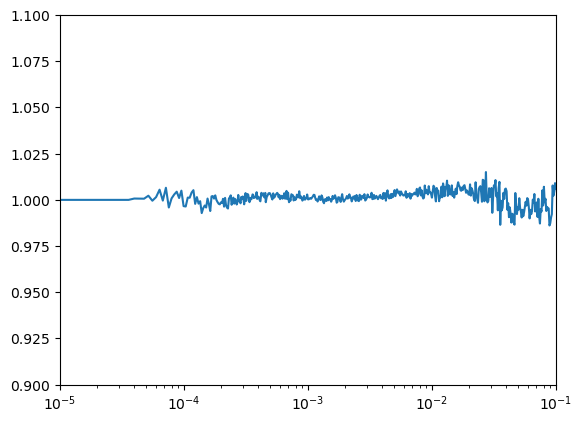

In [824]:
plt.semilogx(tausoff, Voff/Von)
plt.xlim(0.00001,0.1)
plt.ylim(0.9,1.1)